In [1]:
import numpy as np
from pytenet.global_krylov_method import  get_W, get_S
from pytenet.global_krylov_method import generate_krylov_space, generate_reduced_H_non_ortho,generate_krylov_space_test_poly_with_constant
import numpy as np
import copy
import h5py
np.set_printoptions(precision=4,suppress=True)
import matplotlib.pyplot as plt
import pickle
from pytenet.hamiltonian_thc import eval_func
import pytenet as ptn
from pytenet.operation import outer_product,vdot,apply_operator, add_mps_and_compress,add_mps, apply_operator_and_compress,apply_operator, operator_average,operator_inner_product
from scipy.sparse.linalg import eigsh
from pytenet.Lanczos import dmrg_singlesite,dmrg_twosite,solve_ritz_vecs,generate_re_ortho_space, generate_restart_with_ritz,generate_Krylov_space_TRL ,generate_band_krylov,generate_single_state_bose,generate_single_state_spin,generate_single_state_spin1,generate_band_thick_krylov
import copy
import scipy
from pytenet.mps import create_random_mps
from matplotlib.ticker import FuncFormatter

### Ising Model

In [108]:
mpo_ising = ptn.ising_mpo(L=12,J = 1,g = 1, h =2)
matrix_ising = mpo_ising.as_matrix(sparse_format=True)
eigenvalues, vecs = eigsh(matrix_ising, k=10, which='SA', return_eigenvectors=True)

v = create_random_mps([1,1,1,1,1,1,1,1,1,1,1,1,1],'right',rng = np.random.default_rng(1234))
v.zero_qnumbers()

In [109]:
N_Krylov = 100
max_bond_Krylov = 12
#max_bond_Krylov = 75
trunc_tol = 1e-10
foldername = f"test"
generate_krylov_space(N_Krylov, mpo_ising, v, max_bond_Krylov, trunc_tol, foldername) 
N_list = []
e_ising = []
N_use = 100
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, mpo_ising)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
for N in range(5, N_use+1, 5):
    N_list.append(N)
    H_part = H_reduced[:N, :N]
    e_rotate, v_rotate = np.linalg.eigh(H_part)
    e_ising.append(e_rotate)

[1, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 1]
2
[1, 2, 4, 5, 5, 5, 5, 5, 5, 5, 4, 2, 1]
3
[1, 2, 4, 7, 7, 7, 7, 7, 7, 7, 4, 2, 1]
4
[1, 2, 4, 8, 9, 9, 9, 9, 9, 8, 4, 2, 1]
5
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
6
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
7
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
8
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
9
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
10
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
11
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
12
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
13
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
14
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
15
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
16
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
17
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
18
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
19
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
20
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
21
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
22
[1, 2, 4, 8, 12, 12,

c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


In [42]:
opt_gs_err = []
opt_1st_err = []
opt_2nd_err = []
opt_3rd_err = []
opt_4th_err = []
#bond_dim_list = [1,6,10,20,30,40,50,60,70,80,90,100,110,120,130,140,150,160,170,180,186]
bond_dim_list = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20]
for i in bond_dim_list:
    gs_vec = copy.deepcopy(vecs.T[0])
    ex1st_vec = copy.deepcopy(vecs.T[1])
    ex2nd_vec = copy.deepcopy(vecs.T[2])
    ex3rd_vec = copy.deepcopy(vecs.T[3])
    ex4th_vec = copy.deepcopy(vecs.T[4])
    gs_mps = ptn.MPS.from_vector(2,12,gs_vec)
    ex1st_mps = ptn.MPS.from_vector(2,12,ex1st_vec)
    ex2nd_mps = ptn.MPS.from_vector(2,12,ex2nd_vec)
    ex3rd_mps = ptn.MPS.from_vector(2,12,ex3rd_vec)
    ex4th_mps = ptn.MPS.from_vector(2,12,ex4th_vec)
    gs_mps.orthonormalize("right")
    ex1st_mps.orthonormalize("right")
    ex2nd_mps.orthonormalize("right")
    ex3rd_mps.orthonormalize("right")
    ex4th_mps.orthonormalize("right")
    gs_mps.compress_direct_svd_left_max_bond(tol=0,max_bond=i)
    gs_mps.orthonormalize("right")
    gs_mps.orthonormalize("left")
    ex1st_mps.compress_direct_svd_left_max_bond(tol=0,max_bond=i)
    ex1st_mps.orthonormalize("right")
    ex1st_mps.orthonormalize("left")
    ex2nd_mps.compress_direct_svd_left_max_bond(tol=0,max_bond=i)
    ex2nd_mps.orthonormalize("right")
    ex2nd_mps.orthonormalize("left")
    ex3rd_mps.compress_direct_svd_left_max_bond(tol=0,max_bond=i)
    ex3rd_mps.orthonormalize("right")
    ex3rd_mps.orthonormalize("left")
    ex4th_mps.compress_direct_svd_left_max_bond(tol=0,max_bond=i)
    ex4th_mps.orthonormalize("right")
    ex4th_mps.orthonormalize("left")

    opt_gs_err.append(np.linalg.norm(operator_average(gs_mps, mpo_ising) - eigenvalues[0]) /np.abs(eigenvalues[0])   )
    opt_1st_err.append(np.linalg.norm(operator_average(ex1st_mps, mpo_ising) - eigenvalues[1]) /np.abs(eigenvalues[1])   )
    opt_2nd_err.append(np.linalg.norm(operator_average(ex2nd_mps, mpo_ising) - eigenvalues[2])/np.abs(eigenvalues[2])   )
    opt_3rd_err.append(np.linalg.norm(operator_average(ex3rd_mps, mpo_ising) - eigenvalues[3])/np.abs(eigenvalues[3])   )
    opt_4th_err.append(np.linalg.norm(operator_average(ex4th_mps, mpo_ising) - eigenvalues[4])/np.abs(eigenvalues[4])   )

###(1.8053718520150142e-09+0j) for 30

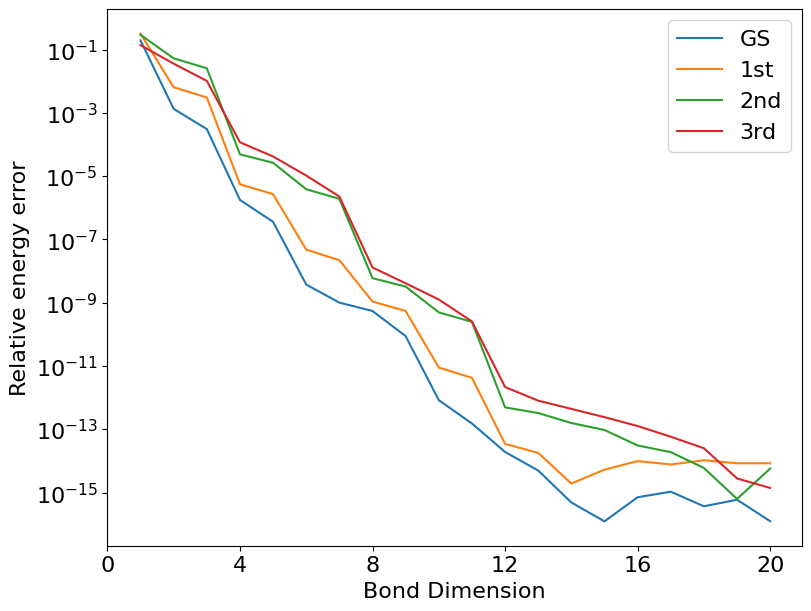

In [98]:
plt.figure(figsize=(8, 6),dpi = 100,constrained_layout=True)
plt.plot(bond_dim_list,opt_gs_err)
plt.plot(bond_dim_list,opt_1st_err)
plt.plot(bond_dim_list,opt_2nd_err)
plt.plot(bond_dim_list,opt_3rd_err)
plt.legend(["GS","1st","2nd","3rd","4th"],fontsize=16)
plt.xlabel("Bond Dimension", fontsize=16)
plt.ylabel("Relative energy error", fontsize=16)
ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)
xticks = [i for i in range(0,21,4)]  # 10^0 to 10^-10
plt.xticks(xticks)
plt.yscale("log")

plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\ising_ed.pdf",bbox_inches='tight',
        pad_inches=0.05)
plt.show()

In [73]:
e_ising[-1]

array([-20.9908, -20.9495, -19.6351, -19.3765, -18.6299, -17.929 ,
       -17.6503, -17.5174, -16.5403, -15.7267, -14.5883, -14.3284,
       -13.2922, -12.4347, -11.0873, -10.4729,  -9.4574,  -8.6303,
        -7.6945,  -6.8818,  -5.9682,  -5.4173,  -4.9829,  -4.447 ,
        -3.8791,  -3.2698,  -2.8209,  -2.7114,  -2.327 ,  -1.7166,
        -1.0455,  -0.5579,  -0.1018,  -0.0074,  -0.0012,  -0.0001,
        -0.    ,  -0.    ,  -0.    ,  -0.    ,  -0.    ,  -0.    ,
        -0.    ,  -0.    ,   0.    ,   0.    ,   0.    ,   0.    ,
         0.    ,   0.    ,   0.    ,   0.    ,   0.    ,   0.    ,
         0.    ,   0.0001,   0.0002,   0.0011,   0.0024,   0.0094,
         0.0405,   0.0962,   0.3231,   0.7161,   1.2415,   2.0586,
         3.1428,   3.825 ,   5.0096,   5.1756,   5.8595,   6.2501,
         7.0017,   8.0274,   9.34  ,  10.5957,  12.1057,  12.6433,
        13.4703,  13.7722,  14.5349,  16.1095,  17.7011,  18.4709,
        19.5984,  20.4552,  20.8298,  22.1688,  22.9565,  24.0

In [75]:
eigenvalues

array([-20.9587, -19.5936, -19.4571, -19.264 , -19.041 , -18.8019,
       -18.556 , -18.3765, -18.2758, -18.2389])

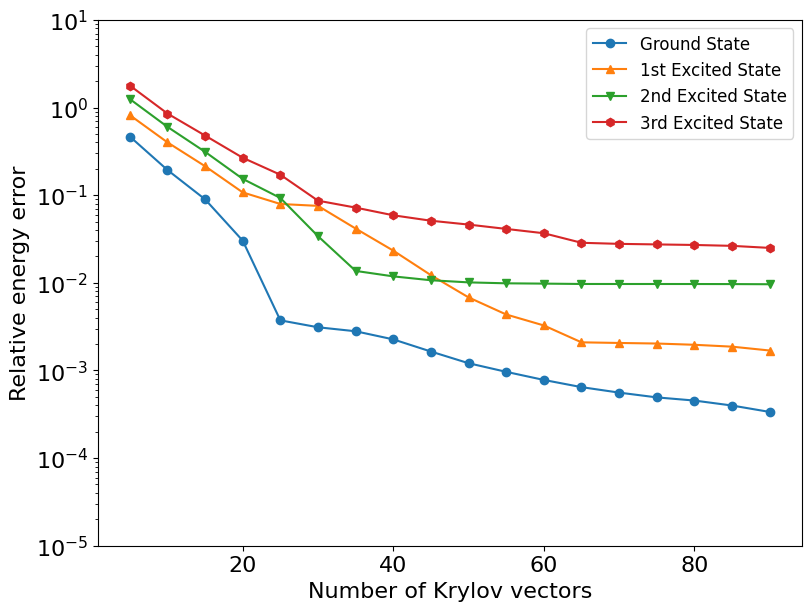

In [97]:
# Build the y-values for each of the five difference
y0 = [np.abs((e_ising[i][0] - eigenvalues[0]))/np.abs(eigenvalues[0]) for i in range(18)]
y1 = [np.abs((e_ising[i][1] - eigenvalues[0]))/np.abs(eigenvalues[0]) for i in range(18)]
y2 = [np.abs((e_ising[i][2] - eigenvalues[1]))/np.abs(eigenvalues[1]) for i in range(18)]
y3 = [np.abs((e_ising[i][3] - eigenvalues[2]))/np.abs(eigenvalues[2]) for i in range(18)]
y4 = [np.abs((e_ising[i][4] - eigenvalues[3]))/np.abs(eigenvalues[3]) for i in range(18)]


plt.figure(figsize=(8, 6),dpi = 100,constrained_layout=True)
N_list = np.linspace(5, 90, 18)
# Plot each difference vs. xx
plt.plot(N_list, y0, 'o-', label="Ground State")
plt.plot(N_list, y1, '^-', label="1st Excited State")
plt.plot(N_list, y2, 'v-', label="2nd Excited State")
plt.plot(N_list, y3, 'h-', label="3rd Excited State")



plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Relative energy error", fontsize=16)


plt.ylim(1e-5, 1e1)

ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)

# Add horizontal line at 1e-7


# Optional: force y-axis ticks at each 10^-x
yticks = [10**(-i) for i in range(1,6,2)]  # 10^0 to 10^-10
plt.yticks(yticks)

ax = plt.gca() # Get current axes
ax.tick_params(axis='both', which='major', labelsize=16)
plt.yscale('log')

plt.legend(fontsize=12)
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\ising_plain.pdf",bbox_inches='tight',
        pad_inches=0.05)
plt.show()


In [81]:
N_Krylov = 30
max_bond_Krylov = 12
trunc_tol = 1e-10
foldername = f"test_irlm"
generate_krylov_space(N_Krylov+1, mpo_ising, v, max_bond_Krylov, trunc_tol, foldername)
k = 10
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov, foldername, mpo_ising)
W = get_W(N_Krylov, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
e,v_ritz = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, N_Krylov, mpo_ising)
e_trl = [e[:4]]
v = v_ritz[:k]
filename = foldername + f"/Krylov_vec{N_Krylov}.pkl"
with open(filename, 'rb') as file:
    temp1 = pickle.load(file)
v.append(temp1)
max_restart_num = 10

for count in range(max_restart_num):
    generate_restart_with_ritz(v, N_Krylov+1, mpo_ising, max_bond_Krylov, trunc_tol, foldername)
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov, foldername, mpo_ising)
    W = get_W(N_Krylov, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    coeff = coeff[:N_Krylov,:N_Krylov]
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    e,v_ritz = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, k, mpo_ising)

    e_trl.append(e[:4])
    v = v_ritz[:k]
    with open(filename, 'rb') as file:
        temp1 = pickle.load(file)
    v.append(temp1)
    print("restart "+ str(count))
  

[1, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 1]
2
[1, 2, 4, 5, 5, 5, 5, 5, 5, 5, 4, 2, 1]
3
[1, 2, 4, 7, 7, 7, 7, 7, 7, 7, 4, 2, 1]
4
[1, 2, 4, 8, 9, 9, 9, 9, 9, 8, 4, 2, 1]
5
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
6
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
7
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
8
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
9
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
10
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
11
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
12
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
13
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
14
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
15
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
16
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
17
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
18
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
19
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
20
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
21
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
22
[1, 2, 4, 8, 12, 12,

c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


12
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
13
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
14
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
15
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
16
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
17
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
18
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
19
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
20
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
21
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
22
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
23
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
24
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
25
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
26
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
27
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
28
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
29
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
30
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
restart 0
12
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
13
[1, 2, 4, 8, 12, 12, 12, 12

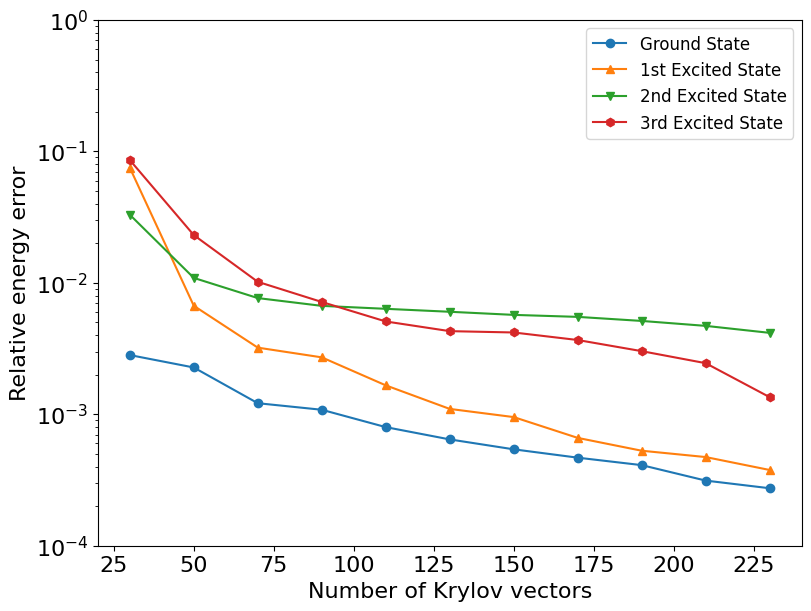

In [96]:
# Build the y-values for each of the five difference
y0 = [np.abs((e_trl[i][0] - eigenvalues[0]))/np.abs(eigenvalues[0]) for i in range(11)]
y1 = [np.abs((e_trl[i][1] - eigenvalues[0]))/np.abs(eigenvalues[0]) for i in range(11)]
y2 = [np.abs((e_trl[i][2] - eigenvalues[1]))/np.abs(eigenvalues[1]) for i in range(11)]
y3 = [np.abs((e_trl[i][3] - eigenvalues[2]))/np.abs(eigenvalues[2]) for i in range(11)]





N_list = np.linspace(30, 30+20*10, 11)



plt.figure(figsize=(8, 6),dpi = 100,constrained_layout=True)

# Plot each difference vs. xx
plt.plot(N_list, y0, 'o-', label="Ground State")
plt.plot(N_list, y1, '^-', label="1st Excited State")
plt.plot(N_list, y2, 'v-', label="2nd Excited State")
plt.plot(N_list, y3, 'h-', label="3rd Excited State")



plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Relative energy error", fontsize=16)


plt.ylim(1e-4, 1e0)

ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)

# Add horizontal line at 1e-7


# Optional: force y-axis ticks at each 10^-x
yticks = [10**(-i) for i in range(1,4,2)]  # 10^0 to 10^-10
plt.yticks(yticks)

ax = plt.gca() # Get current axes
ax.tick_params(axis='both', which='major', labelsize=16)
plt.yscale('log')

plt.legend(fontsize=12)
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\ising_trl.pdf",bbox_inches='tight',
        pad_inches=0.05)
plt.show()


In [87]:
eigenvalues

array([-20.9587, -19.5936, -19.4571, -19.264 , -19.041 , -18.8019,
       -18.556 , -18.3765, -18.2758, -18.2389])

In [110]:
N_Krylov = 100
max_bond_Krylov = 128
#max_bond_Krylov = 75
trunc_tol = 1e-10
foldername = f"fidelity_test_1"
generate_krylov_space(N_Krylov, mpo_ising, v, max_bond_Krylov, trunc_tol, foldername) 

[1, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 1]
2
[1, 2, 4, 5, 5, 5, 5, 5, 5, 5, 4, 2, 1]
3
[1, 2, 4, 7, 7, 7, 7, 7, 7, 7, 4, 2, 1]
4
[1, 2, 4, 8, 9, 9, 9, 9, 9, 8, 4, 2, 1]
5
[1, 2, 4, 8, 12, 12, 12, 12, 12, 8, 4, 2, 1]
6
[1, 2, 4, 8, 14, 16, 16, 16, 15, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 18, 19, 20, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 21, 22, 22, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 24, 25, 24, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 26, 27, 26, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 28, 29, 27, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 29, 32, 29, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 30, 34, 30, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 30, 36, 32, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 31, 38, 32, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 31, 40, 32, 16, 8, 4, 2, 1]
17
[1, 2, 4, 8, 16, 31, 42, 32, 16, 8, 4, 2, 1]
18
[1, 2, 4, 8, 16, 31, 43, 32, 16, 8, 4, 2, 1]
19
[1, 2, 4, 8, 16, 32, 46, 32, 16, 8, 4, 2, 1]
20
[1, 2, 4, 8, 16, 32, 47, 32, 16, 8, 4, 2, 1]
21
[1, 2, 4, 8, 16, 32, 48, 32, 16, 8, 4, 2, 1]
22
[1, 2, 4, 8, 16, 32,

In [111]:
fidelity_list = []
for i in range(100):
    filename1 = f"fidelity_test_1" + f"/Krylov_vec{i}.pkl"
    with open(filename1, 'rb') as file:
        temp1 = pickle.load(file)
    filename2 = f"test" + f"/Krylov_vec{i}.pkl"
    with open(filename2, 'rb') as file:
        temp2 = pickle.load(file)
    fidelity = np.abs(vdot(temp1, temp2))**2
    fidelity_list.append(fidelity)
    

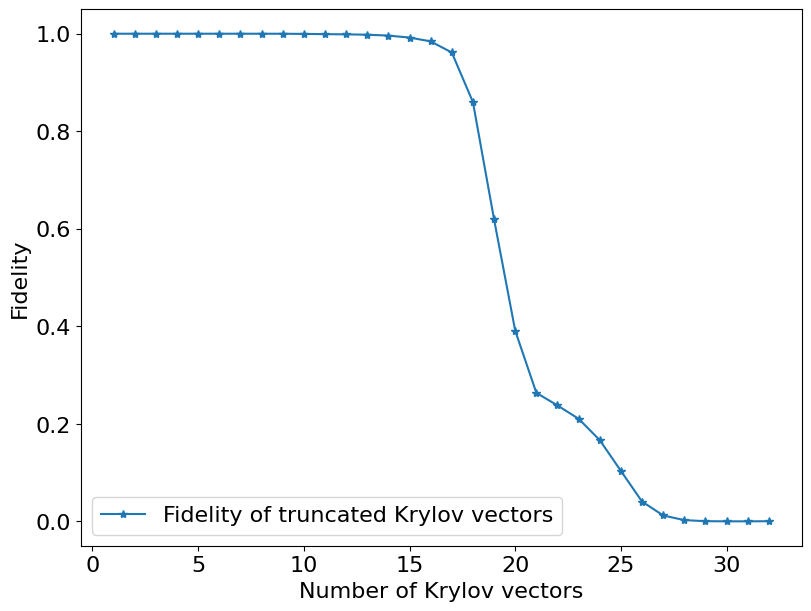

In [130]:

N_list = np.linspace(1, 32, 32)



plt.figure(figsize=(8, 6),dpi = 100,constrained_layout=True)

# Plot each difference vs. xx
plt.plot(N_list, fidelity_list[:32],'*-', label="Fidelity of truncated Krylov vectors")


plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Fidelity", fontsize=16)


ax = plt.gca() # Get current axes
ax.tick_params(axis='both', which='major', labelsize=16)

plt.legend(fontsize=16)
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\ising_fidelity.pdf",bbox_inches='tight',
        pad_inches=0.05)
plt.show()


### Heisenberg XXZ Model


In [3]:
### Generate the Heisenberg MPO
mpo_ref = ptn.heisenberg_xxz_mpo(L = 12, J= -4, D=-4, h= 2)
#mpo_ref = ptn.fermi_hubbard_mpo(L = 7, U=1, t=1, mu=0)
print(mpo_ref.bond_dims)

### Convert the MPO to a matrix for testing exact eigenvalue 
matrix = mpo_ref.as_matrix(sparse_format=True)
np.shape(matrix)
eigenvalues, vecs = eigsh(matrix, k=20, which='SA', return_eigenvectors=True)


[1, 4, 5, 5, 5, 5, 5, 5, 5, 5, 5, 4, 1]


In [19]:
gs_vec = copy.deepcopy(vecs.T[1])
gs_mps = ptn.MPS.from_vector(2,10,gs_vec)
gs_mps.compress_no_normalization_max_bond(tol=0,max_bond=30)
gs_mps.orthonormalize("left")
gs_mps.orthonormalize("right")
gs_mps.orthonormalize("left")
operator_average(gs_mps, mpo_ref) - eigenvalues[1]

np.complex128(-1.3322676295501878e-14+2.914335439641036e-16j)

In [22]:
opt_gs_err = []
opt_1st_err = []
opt_2nd_err = []
opt_3rd_err = []
opt_4th_err = []
#bond_dim_list = [1,6,10,20,30,40,50,60,70,80,90,100,110,120,130,140,150,160,170,180,186]
bond_dim_list = [1,2,3,4,5,6,7,8,9,10]
for i in bond_dim_list:
    gs_vec = copy.deepcopy(vecs.T[0])
    ex1st_vec = copy.deepcopy(vecs.T[1])
    ex2nd_vec = copy.deepcopy(vecs.T[2])
    ex3rd_vec = copy.deepcopy(vecs.T[3])
    ex4th_vec = copy.deepcopy(vecs.T[4])
    gs_mps = ptn.MPS.from_vector(2,12,gs_vec)
    ex1st_mps = ptn.MPS.from_vector(2,12,ex1st_vec)
    ex2nd_mps = ptn.MPS.from_vector(2,12,ex2nd_vec)
    ex3rd_mps = ptn.MPS.from_vector(2,12,ex3rd_vec)
    ex4th_mps = ptn.MPS.from_vector(2,12,ex4th_vec)
    gs_mps.orthonormalize("right")
    ex1st_mps.orthonormalize("right")
    ex2nd_mps.orthonormalize("right")
    ex3rd_mps.orthonormalize("right")
    ex4th_mps.orthonormalize("right")
    gs_mps.compress_direct_svd_left_max_bond(tol=0,max_bond=i)
    gs_mps.orthonormalize("right")
    gs_mps.orthonormalize("left")
    ex1st_mps.compress_direct_svd_left_max_bond(tol=0,max_bond=i)
    ex1st_mps.orthonormalize("right")
    ex1st_mps.orthonormalize("left")
    ex2nd_mps.compress_direct_svd_left_max_bond(tol=0,max_bond=i)
    ex2nd_mps.orthonormalize("right")
    ex2nd_mps.orthonormalize("left")
    ex3rd_mps.compress_direct_svd_left_max_bond(tol=0,max_bond=i)
    ex3rd_mps.orthonormalize("right")
    ex3rd_mps.orthonormalize("left")
    ex4th_mps.compress_direct_svd_left_max_bond(tol=0,max_bond=i)
    ex4th_mps.orthonormalize("right")
    ex4th_mps.orthonormalize("left")

    opt_gs_err.append(np.linalg.norm(operator_average(gs_mps, mpo_ref) - eigenvalues[0]))
    opt_1st_err.append(np.linalg.norm(operator_average(ex1st_mps, mpo_ref) - eigenvalues[1]))
    opt_2nd_err.append(np.linalg.norm(operator_average(ex2nd_mps, mpo_ref) - eigenvalues[2]))
    opt_3rd_err.append(np.linalg.norm(operator_average(ex3rd_mps, mpo_ref) - eigenvalues[3]))
    opt_4th_err.append(np.linalg.norm(operator_average(ex4th_mps, mpo_ref) - eigenvalues[4]))

###(1.8053718520150142e-09+0j) for 30

In [100]:
eigenvalues

array([-5.7635, -5.6735, -5.596 , -5.4735, -5.4488, -5.3663, -5.2928,
       -5.2488, -5.238 , -5.2322, -5.1848, -5.1474, -5.1469, -5.1357,
       -5.0688, -5.052 , -5.0242, -5.038 , -5.0336, -5.0322])

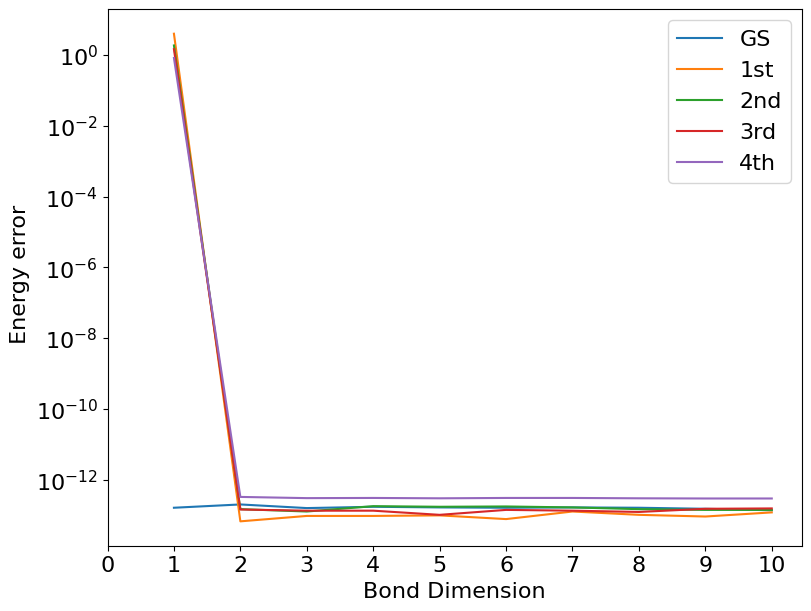

In [25]:
plt.figure(figsize=(8, 6),dpi = 100,constrained_layout=True)
plt.plot(bond_dim_list,opt_gs_err)
plt.plot(bond_dim_list,opt_1st_err)
plt.plot(bond_dim_list,opt_2nd_err)
plt.plot(bond_dim_list,opt_3rd_err)
plt.plot(bond_dim_list,opt_4th_err)
plt.legend(["GS","1st","2nd","3rd","4th"],fontsize=16)
plt.xlabel("Bond Dimension", fontsize=16)
plt.ylabel(" Energy error", fontsize=16)
ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)
xticks = [i for i in range(0,11,1)]  # 10^0 to 10^-10
plt.xticks(xticks)
plt.yscale("log")

plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\hei_ed.pdf",bbox_inches='tight',
        pad_inches=0.05)
plt.show()

In [6]:
import random

def generate_equal_zeros_ones(n: int) -> list[int]:
    """
    Generate a list of length n containing the same number of 0s and 1s.
    
    Args:
        n: The desired length of the list. Must be even.
        
    Returns:
        A list of length n with n/2 zeros and n/2 ones in random order.
        
    Raises:
        ValueError: If n is not even.
    """
    if n % 2 != 0:
        raise ValueError("List length must be even to have equal number of 0s and 1s.")
    
    half = n // 2
    result = [0] * (half+1) + [1] * (half-1)
    random.shuffle(result)
    return result

list1 = generate_equal_zeros_ones(12)
list2 = generate_equal_zeros_ones(12)
list3 = generate_equal_zeros_ones(12)
list4 = generate_equal_zeros_ones(12)
list5 = generate_equal_zeros_ones(12)



HFS = generate_single_state_spin(12, list1)
HFS.orthonormalize('right')
HFS1 = generate_single_state_spin(12, list2)
HFS1.orthonormalize('right')
HFS2 = generate_single_state_spin(12, list3)
HFS2.orthonormalize('right')
HFS3 = generate_single_state_spin(12, list4)
HFS3.orthonormalize('right')
HFS4 = generate_single_state_spin(12, list5)
HFS4.orthonormalize('right')
HFS2 = add_mps(HFS, HFS1)
HFS2.orthonormalize('right')



np.float64(1.4142135623730951)

### Full Lanczos (No Restart)

In [ ]:
### Here we have no truncation, for testing the eigenvalues
N_Krylov = 100
H = mpo_ref
psi_original = copy.deepcopy(HFS2)
max_bond_Krylov = 2
#max_bond_Krylov = 75
trunc_tol = 0
foldername = f"test"
N_list = []
foldername = f"test"
generate_krylov_space(N_Krylov, H, HFS2, max_bond_Krylov, trunc_tol, foldername) 

N_use = 100
# C = coeff_canonical_orthogonalization(N_use, foldername)
# vector_list = generate_re_ortho_space_with_coeff(N_use, C, foldername)
#vector_list = generate_re_ortho_space(N_use, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, mpo_ref)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
e_real = np.linalg.eigvalsh(H_reduced)
e_real

[1, 2, 4, 5, 6, 8, 8, 8, 6, 7, 4, 4, 5, 5, 3, 2, 1]
2
[1, 2, 4, 8, 16, 29, 49, 50, 37, 42, 25, 18, 14, 8, 4, 2, 1]
3
[1, 2, 4, 8, 16, 32, 63, 122, 174, 108, 54, 30, 16, 8, 4, 2, 1]
4
[1, 2, 4, 8, 16, 32, 64, 127, 186, 128, 64, 32, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 32, 64, 127, 186, 128, 64, 32, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 32, 64, 127, 186, 128, 64, 32, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 32, 64, 127, 186, 128, 64, 32, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 32, 64, 128, 186, 128, 64, 32, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 32, 64, 128, 186, 128, 64, 32, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 32, 64, 128, 186, 128, 64, 32, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 32, 64, 128, 186, 128, 64, 32, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 32, 64, 128, 186, 128, 64, 32, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 32, 64, 128, 186, 128, 64, 32, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 32, 64, 128, 186, 128, 64, 32, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 32, 64, 128, 186, 128, 64, 32, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 3

KeyboardInterrupt: 

In [7]:
### Here we test how bond dimension affects the eigenvalues accuracy
N_Krylov = 100
H = mpo_ref
bond_dim_list = [20,30,40,50,60,70,80,90,100,110,120,130,140,150,160,170,180,186]
bond_test = []

for max_bond_Krylov in bond_dim_list:
    generate_krylov_space(N_Krylov, H, HFS, max_bond_Krylov, trunc_tol, foldername) 
    N_use = 100
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, mpo_ref)
    W = get_W(N_use, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    e_real = np.linalg.eigvalsh(H_reduced)
    bond_test.append(e_real)



[1, 1, 2, 2, 2, 2, 2, 3, 4, 4, 4, 4, 3, 3, 3, 2, 1]
2
[1, 2, 3, 5, 6, 6, 8, 12, 20, 20, 20, 17, 13, 7, 4, 2, 1]
3
[1, 2, 4, 7, 10, 20, 20, 20, 20, 20, 20, 20, 15, 8, 4, 2, 1]
4
[1, 2, 4, 7, 14, 20, 20, 20, 20, 20, 20, 20, 15, 8, 4, 2, 1]
5
[1, 2, 4, 8, 15, 20, 20, 20, 20, 20, 20, 20, 15, 8, 4, 2, 1]
6
[1, 2, 4, 8, 15, 20, 20, 20, 20, 20, 20, 20, 15, 8, 4, 2, 1]
7
[1, 2, 4, 8, 15, 20, 20, 20, 20, 20, 20, 20, 15, 8, 4, 2, 1]
8
[1, 2, 4, 8, 15, 20, 20, 20, 20, 20, 20, 20, 15, 8, 4, 2, 1]
9
[1, 2, 4, 8, 15, 20, 20, 20, 20, 20, 20, 20, 15, 8, 4, 2, 1]
10
[1, 2, 4, 8, 15, 20, 20, 20, 20, 20, 20, 20, 15, 8, 4, 2, 1]
11
[1, 2, 4, 8, 15, 20, 20, 20, 20, 20, 20, 20, 15, 8, 4, 2, 1]
12
[1, 2, 4, 8, 15, 20, 20, 20, 20, 20, 20, 20, 15, 8, 4, 2, 1]
13
[1, 2, 4, 8, 15, 20, 20, 20, 20, 20, 20, 20, 15, 8, 4, 2, 1]
14
[1, 2, 4, 8, 15, 20, 20, 20, 20, 20, 20, 20, 15, 8, 4, 2, 1]
15
[1, 2, 4, 8, 15, 20, 20, 20, 20, 20, 20, 20, 15, 8, 4, 2, 1]
16
[1, 2, 4, 8, 15, 20, 20, 20, 20, 20, 20, 20, 15, 8, 4, 2, 1]

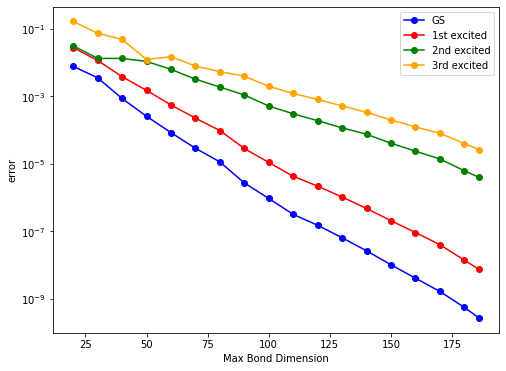

In [9]:
###Plot if no truncation is used, the eigenvalues should be the same as the classical Lanczos eigenvalues 
gs_elements = [arr[0] for arr in bond_test]  
first_ex_elements = [arr[1] for arr in bond_test]
second_ex_elements = [arr[2] for arr in bond_test]
third_ex_elements = [arr[3] for arr in bond_test]



plt.figure(figsize=(8, 6))
plt.plot(bond_dim_list, gs_elements-eigenvalues[-1], 'o-', color='blue')
plt.plot(bond_dim_list, first_ex_elements-eigenvalues[-3], 'o-', color='red')
plt.plot(bond_dim_list, second_ex_elements-eigenvalues[-6], 'o-', color='green')
plt.plot(bond_dim_list, third_ex_elements-eigenvalues[-7], 'o-', color='orange')

plt.legend(['GS', '1st excited', '2nd excited', '3rd excited'])


plt.yscale('log')
plt.xlabel('Max Bond Dimension')
plt.ylabel('error')
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\hei_real.pdf")
plt.show()


In [7]:
N_Krylov = 100
psi_original = copy.deepcopy(HFS2)
max_bond_Krylov = 2
#max_bond_Krylov = 75
trunc_tol = 0
foldername = f"test"
e_heisenberg = [] 
H = mpo_ref
#HFS1 = generate_single_state(7, [3, 3, 3, 3, 3, 0, 0])
N_list = []
foldername = f"test"
generate_krylov_space(N_Krylov, H, HFS2, max_bond_Krylov, trunc_tol, foldername) 

N_use = 100
# C = coeff_canonical_orthogonalization(N_use, foldername)
# vector_list = generate_re_ortho_space_with_coeff(N_use, C, foldername)
#vector_list = generate_re_ortho_space(N_use, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, H)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
for N in range(5, N_use+1, 5):
    N_list.append(N)
    H_part = H_reduced[:N, :N]
    e_rotate, v_rotate = np.linalg.eigh(H_part)
    e_heisenberg.append(e_rotate)



   


[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
2
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
3
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
4
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
5
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
6
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
7
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
8
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
9
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
10
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
11
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
12
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
13
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
14
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
15
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
16
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
17
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
18
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
19
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
20
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
21
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
22
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
23
[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
24
[1, 2, 2, 2, 2, 2, 

c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


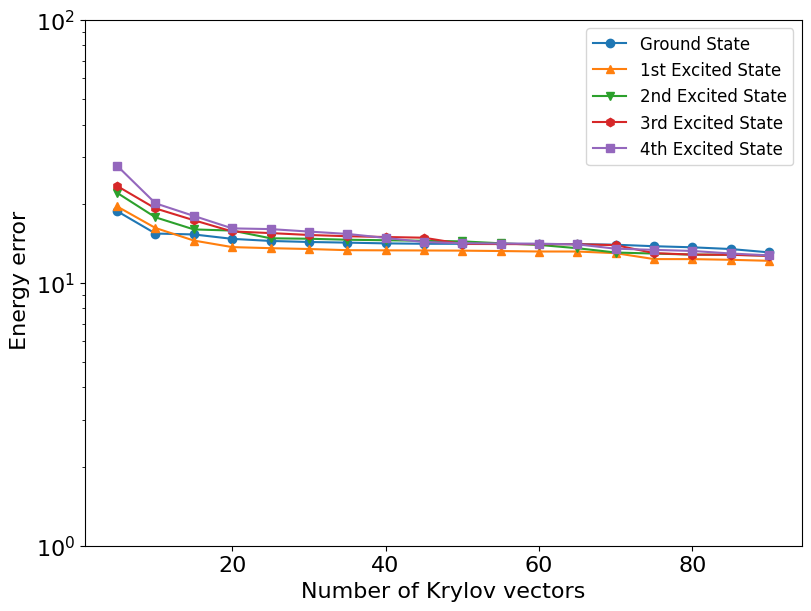

In [16]:
# Build the y-values for each of the five difference
y0 = [np.abs((e_heisenberg[i][0] - eigenvalues[0])) for i in range(18)]
y1 = [np.abs((e_heisenberg[i][1] - eigenvalues[1])) for i in range(18)]
y2 = [np.abs((e_heisenberg[i][2] - eigenvalues[2]))  for i in range(18)]
y3 = [np.abs((e_heisenberg[i][3] - eigenvalues[3]))  for i in range(18)]
y4 = [np.abs((e_heisenberg[i][4] - eigenvalues[4]))  for i in range(18)]


plt.figure(figsize=(8, 6),dpi = 100,constrained_layout=True)
N_list = np.linspace(5, 90, 18)
# Plot each difference vs. xx
plt.plot(N_list, y0, 'o-', label="Ground State")
plt.plot(N_list, y1, '^-', label="1st Excited State")
plt.plot(N_list, y2, 'v-', label="2nd Excited State")
plt.plot(N_list, y3, 'h-', label="3rd Excited State")
plt.plot(N_list, y4, 's-', label="4th Excited State")



plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel(" Energy error", fontsize=16)


plt.ylim(1e-0, 1e2)

ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)

# Add horizontal line at 1e-7


# Optional: force y-axis ticks at each 10^-x
yticks = [10**(-i) for i in range(0,1,2)]  # 10^0 to 10^-10
plt.yticks(yticks)

ax = plt.gca() # Get current axes
ax.tick_params(axis='both', which='major', labelsize=16)
plt.yscale('log')

plt.legend(fontsize=12)
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\hei_plain_compare.pdf",bbox_inches='tight',
        pad_inches=0.05)
plt.show()


### Applying H on eigenvector

In [141]:
psi0 = copy.deepcopy(v_ritz[0])
psi1 = copy.deepcopy(v_ritz[1])
psi2 = copy.deepcopy(v_ritz[2])
psi3 = copy.deepcopy(v_ritz[3])
psi4 = copy.deepcopy(v_ritz[4])
e0 = []
for i in range(300):
    Hpsi = apply_operator_and_compress(H,psi0,0,30)
    Hpsi.orthonormalize('right')
    e0.append(operator_average(Hpsi,H)-eigenvalues[1])
    psi0 = copy.deepcopy(Hpsi)
e_gs_H = operator_average(Hpsi, H) 


In [142]:
e1 = []
for i in range(300):
    gs = copy.deepcopy(psi0)
    Hpsi = apply_operator(H,psi1)
    temp = vdot(psi0, psi1)
    gs.A[0] =  -temp * gs.A[0] * e_gs_H
    Hpsi = add_mps_and_compress(Hpsi,gs,0,30)  
    Hpsi.orthonormalize('right')
    e1.append(operator_average(Hpsi,H)-eigenvalues[4])
    psi1 = copy.deepcopy(Hpsi)
e_1st_H = operator_average(Hpsi, H)

In [143]:
e2 = []
for i in range(300):
    gs = copy.deepcopy(psi0)
    ex_1 = copy.deepcopy(psi1)
    Hpsi = apply_operator(H,psi2)
    temp1 = vdot(psi0, psi2)
    temp2 = vdot(psi1, psi2)
    gs.A[0] =  -temp1 * gs.A[0] * e_gs_H 
    ex_1.A[0] = -temp2 * ex_1.A[0] * e_1st_H
    Hpsi = add_mps_and_compress(Hpsi,gs,0,30)
    Hpsi = add_mps_and_compress(Hpsi,ex_1,0,30)  
    Hpsi.orthonormalize('right')
    e2.append(operator_average(Hpsi,H)-eigenvalues[8])
    psi2 = copy.deepcopy(Hpsi)
e_2nd_H = operator_average(Hpsi, H)

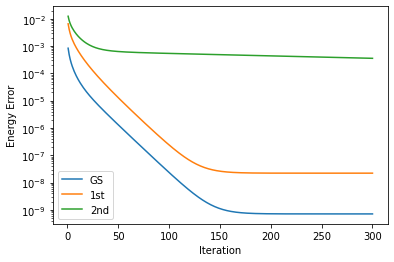

In [150]:
plt.plot(range(1,301),e0)
plt.plot(range(1,301),e1)
plt.plot(range(1,301),e2)
plt.legend(["GS","1st","2nd"])
plt.xlabel("Iteration")
plt.ylabel("Energy Error")
plt.yscale('log')

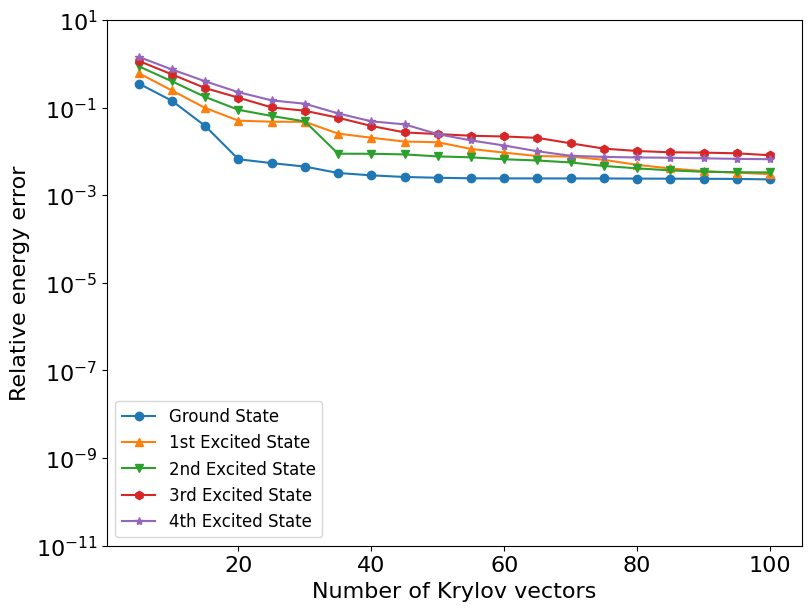

In [131]:
# Build the y-values for each of the five difference
y0 = [(e_heisenberg[i][0] - eigenvalues[1])/np.abs(eigenvalues[1]) for i in range(20)]
y1 = [(e_heisenberg[i][1] - eigenvalues[4])/np.abs(eigenvalues[4]) for i in range(20)]
y2 = [(e_heisenberg[i][2] - eigenvalues[8])/np.abs(eigenvalues[8]) for i in range(20)]
y3 = [(e_heisenberg[i][3] - eigenvalues[9])/np.abs(eigenvalues[9]) for i in range(20)]
y4 = [(e_heisenberg[i][4] - eigenvalues[13])/np.abs(eigenvalues[13]) for i in range(20)]


plt.figure(figsize=(8, 6),dpi = 100,constrained_layout=True)
N_list = np.linspace(5, 100, 20)
# Plot each difference vs. xx
plt.plot(N_list, y0, 'o-', label="Ground State")
plt.plot(N_list, y1, '^-', label="1st Excited State")
plt.plot(N_list, y2, 'v-', label="2nd Excited State")
plt.plot(N_list, y3, 'h-', label="3rd Excited State")
plt.plot(N_list, y4, '*-', label="4th Excited State")


plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Relative energy error", fontsize=16)


plt.ylim(1e-11, 1e1)

ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)

# Add horizontal line at 1e-7


# Optional: force y-axis ticks at each 10^-x
yticks = [10**(-i) for i in range(1,12,2)]  # 10^0 to 10^-10
plt.yticks(yticks)

ax = plt.gca() # Get current axes
ax.tick_params(axis='both', which='major', labelsize=16)
plt.yscale('log')

plt.legend(fontsize=12)
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\hei_plain.pdf",bbox_inches='tight',
        pad_inches=0.05)
plt.show()


### Explicitly Restart
The idea here is straightforward: we run the Lanczos algorithm, compute the lowest Ritz vector, and use it as the initial state. This will converge to the actual eigenvector. After convergence is achieved (or after reaching the specified number of restarts), we move on to the second-lowest Ritz vector, orthogonalize it against the previously found eigenvector, and repeat the process iteratively.

In [102]:
N_Krylov = 30
max_bond_Krylov = 32
trunc_tol = 0
foldername = f"TRL_1"
H = mpo_ref
generate_krylov_space(N_Krylov, H, HFS2, max_bond_Krylov, trunc_tol, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov, foldername, mpo_ref)
W = get_W(N_Krylov, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
k = 1
e,v = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, 5, H)
e_rs = []
err_var_rs = []
fidelity_rs = []

real_state = [vecs.T[1],vecs.T[4],vecs.T[8],vecs.T[9],vecs.T[13]]
e_rs.append(np.array(e))
v = v[:k]
N_Krylov_restart =  10
x_list = [30]
j = 0
res_num = 12
max_restart_num = 5*res_num
count = 0
while count < max_restart_num:
    generate_restart_with_ritz(v, N_Krylov_restart, H, max_bond_Krylov, trunc_tol, foldername)
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov_restart, foldername, mpo_ref)
    W = get_W(N_Krylov_restart, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    # Note: solve_ritz_vecs requested 5 vectors, ensure this is intended
    e_ritz, v_ritz = solve_ritz_vecs(foldername, H_reduced, N_Krylov_restart, coeff, max_bond_Krylov, 5, mpo_ref)
    e_rs.append(np.array(e_ritz))
    x_list.append(x_list[-1]+9)
    err_temp = []
    fidelity_temp = []
    for i in range(l):
        v_test = v_ritz[i]
        temp1 = apply_operator(H, v_test)  
        temp2 = add_mps(temp1,v_test,-e_rs[-1][i])
        err_temp.append(vdot(temp2,temp2))
    err_var_rs.append(np.array(err_temp))

    for i in range(l):
        ritz_state = v_ritz[i].as_vector() 
        fidelity_temp.append(1-np.abs(np.dot(real_state[i],ritz_state))**2)
    fidelity_rs.append(np.array(fidelity_temp))

    if j == res_num: 
        print("Now restart"+ str(k+1) + "Ritz vector(s)")
        k = k+1
        j = 0
        N_Krylov_restart = N_Krylov_restart + 1
    v = v_ritz[:k] 
    count += 1
    j += 1



   

    print("Now restart"+ str(count) + "times")

[1, 2, 4, 6, 7, 8, 8, 8, 6, 8, 8, 7, 5, 4, 2, 1, 1]
2
[1, 2, 4, 8, 15, 29, 32, 32, 32, 32, 32, 25, 14, 8, 4, 2, 1]
3
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 32, 16, 8, 4, 2, 1]
4
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2,

c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


2
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
3
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
4
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
Now restart1times
2
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
3
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
4
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32

In [105]:
count = 0
while count < 5:
    generate_restart_with_ritz(v, N_Krylov_restart, H, max_bond_Krylov, trunc_tol, foldername)
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov_restart, foldername, mpo_ref)
    W = get_W(N_Krylov_restart, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    # Note: solve_ritz_vecs requested 5 vectors, ensure this is intended
    e_ritz, v_ritz = solve_ritz_vecs(foldername, H_reduced, N_Krylov_restart, coeff, max_bond_Krylov, 5, mpo_ref)
    e_rs.append(np.array(e_ritz))
    x_list.append(x_list[-1]+9)
    err_temp = []
    fidelity_temp = []
    for i in range(l):
        v_test = v_ritz[i]
        temp1 = apply_operator(H, v_test)  
        temp2 = add_mps(temp1,v_test,-e_rs[-1][i])
        err_temp.append(vdot(temp2,temp2))
    err_var_rs.append(np.array(err_temp))

    for i in range(l):
        ritz_state = v_ritz[i].as_vector() 
        fidelity_temp.append(1-np.abs(np.dot(real_state[i],ritz_state))**2)
    fidelity_rs.append(np.array(fidelity_temp))

    v = v_ritz[:k] 
    count += 1
    j += 1



   

    print("Now restart"+ str(count) + "times")

6
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 32, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]


c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


Now restart1times
6
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
Now restart2times
6
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
13
[1, 2, 4,

c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
C:\Users\Zhangyu\AppData\Local\Temp/ipykernel_5616/1661110081.py:36: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


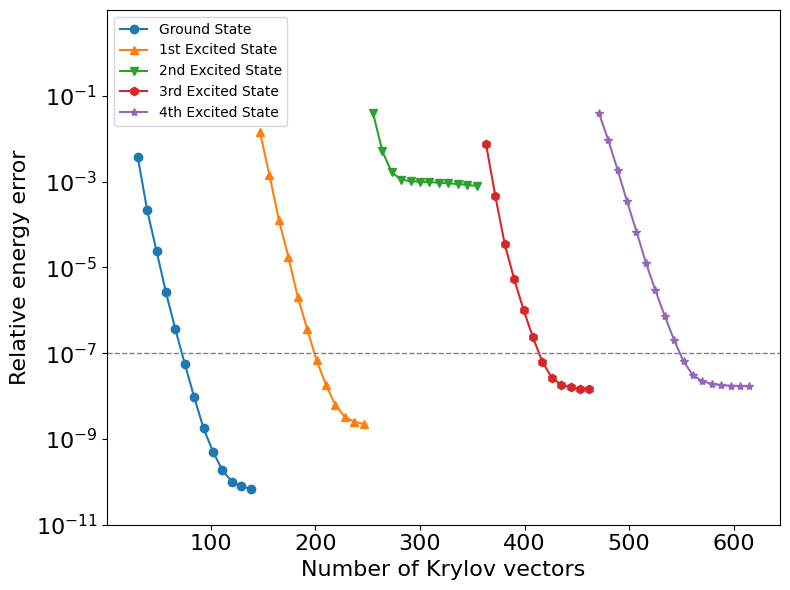

In [126]:
from matplotlib.ticker import FuncFormatter
y0 = [(e_rs[i][0] - eigenvalues[1])/np.abs(eigenvalues[1]) for i in range(max_restart_num+1)]
y1 = [(e_rs[i][1] - eigenvalues[4])/np.abs(eigenvalues[4]) for i in range(max_restart_num+1)]
y2 = [(e_rs[i][2] - eigenvalues[8])/np.abs(eigenvalues[8]) for i in range(max_restart_num+1)]
y3 = [(e_rs[i][3] - eigenvalues[9])/np.abs(eigenvalues[9]) for i in range(max_restart_num+1)]
y4 = [(e_rs[i][4] - eigenvalues[13])/np.abs(eigenvalues[13]) for i in range(max_restart_num+6)]

plt.figure(figsize=(8, 6),dpi = 100,constrained_layout=True)
# Plot each segment
plt.plot(x_list[0:res_num+1], y0[0:res_num+1], 'o-', label="Ground State")
plt.plot(x_list[res_num+1:2*res_num+1], y1[res_num+1:2*res_num+1], '^-', label="1st Excited State")
plt.plot(x_list[2*res_num+1:3*res_num+1], y2[2*res_num+1:3*res_num+1], 'v-', label="2nd Excited State")
plt.plot(x_list[3*res_num+1:4*res_num+1], y3[3*res_num+1:4*res_num+1], 'h-', label="3rd Excited State")
plt.plot(x_list[4*res_num+1:5*res_num+6], y4[4*res_num+1:5*res_num+6], '*-', label="4th Excited State")

# Log scale and axis formatting
plt.yscale('log')
plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Relative energy error", fontsize=16)
plt.ylim(1e-11, 1e1)

ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)

# Add horizontal line at 1e-7
plt.axhline(y=1e-7, color='gray', linestyle='--', linewidth=1)

# Optional: force y-axis ticks at each 10^-x
yticks = [10**(-i) for i in range(1,12,2)]  # 10^0 to 10^-10
plt.yticks(yticks)
formatter = FuncFormatter(lambda y, _: f"$10^{{{int(np.log10(y))}}}$")
ax.yaxis.set_major_formatter(formatter)

plt.legend(fontsize=10)

plt.tight_layout()

plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\hei_erl.pdf",bbox_inches='tight',
        pad_inches=0.05)
plt.show()


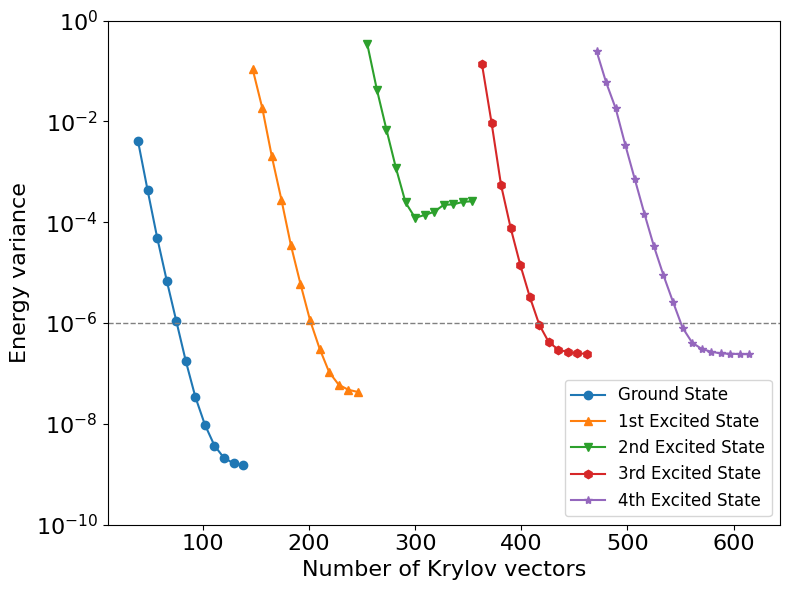

In [20]:
y_var_0 = [err_var_rs[i][0]  for i in range(max_restart_num)]
y_var_1 = [err_var_rs[i][1]  for i in range(max_restart_num)]
y_var_2 = [err_var_rs[i][2]  for i in range(max_restart_num)]
y_var_3 = [err_var_rs[i][3] for i in range(max_restart_num)]
y_var_4 = [err_var_rs[i][4]  for i in range(max_restart_num+5)]
# Plot each segment
plt.figure(figsize=(8, 6),dpi = 100)
plt.plot(x_list[1:res_num+1], y_var_0[0:res_num], 'o-', label="Ground State")
plt.plot(x_list[res_num+1:2*res_num+1], y_var_1[res_num:2*res_num], '^-', label="1st Excited State")
plt.plot(x_list[2*res_num+1:3*res_num+1], y_var_2[2*res_num:3*res_num], 'v-', label="2nd Excited State")
plt.plot(x_list[3*res_num+1:4*res_num+1], y_var_3[3*res_num:4*res_num], 'h-', label="3rd Excited State")
plt.plot(x_list[4*res_num+1:5*res_num+6], y_var_4[4*res_num:5*res_num+5], '*-', label="4th Excited State")


# Log scale and axis formatting
plt.yscale('log')
plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Energy variance", fontsize=16)
plt.ylim(1e-10, 1e0)

ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)

# Add horizontal line at 1e-7
plt.axhline(y=1e-6, color='gray', linestyle='--', linewidth=1)

# Optional: force y-axis ticks at each 10^-x
yticks = [10**(-i) for i in range(0,11,2)]  # 10^0 to 10^-10
plt.yticks(yticks)
formatter = FuncFormatter(lambda y, _: f"$10^{{{int(np.log10(y))}}}$")
ax.yaxis.set_major_formatter(formatter)


plt.legend(fontsize=12)
plt.tight_layout()

plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\hei_variance.pdf")
plt.show()

c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


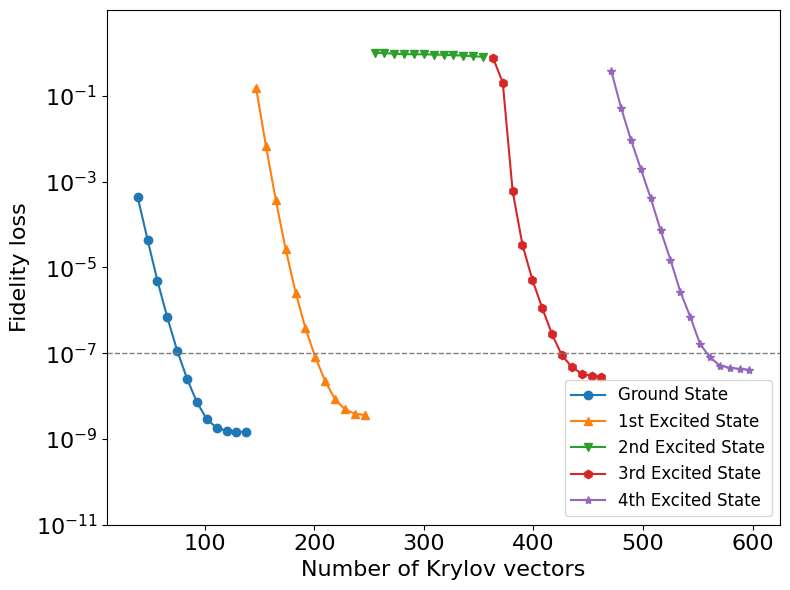

In [617]:
plt.figure(figsize=(8, 6),dpi=100)
y_fd_0 = [fidelity_rs[i][0]  for i in range(max_restart_num)]
y_fd_1 = [fidelity_rs[i][1]  for i in range(max_restart_num)]
y_fd_2 = [fidelity_rs[i][2]  for i in range(max_restart_num)]
y_fd_3 = [fidelity_rs[i][3] for i in range(max_restart_num)]
y_fd_4 = [fidelity_rs[i][4]  for i in range(max_restart_num+5)]
# Plot each segment
plt.plot(x_list[1:res_num+1], y_var_0[0:res_num], 'o-', label="Ground State")
plt.plot(x_list[res_num+1:2*res_num+1], y_fd_1[res_num:2*res_num], '^-', label="1st Excited State")
plt.plot(x_list[2*res_num+1:3*res_num+1], y_fd_2[2*res_num:3*res_num], 'v-', label="2nd Excited State")
plt.plot(x_list[3*res_num+1:4*res_num+1], y_fd_3[3*res_num:4*res_num], 'h-', label="3rd Excited State")
plt.plot(x_list[4*res_num+1:5*res_num+4], y_fd_4[4*res_num:5*res_num+3], '*-', label="4th Excited State")

# Log scale and axis formatting
plt.yscale('log')
plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Fidelity loss", fontsize=16)
plt.ylim(1e-11, 1e1)

ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)

# Add horizontal line at 1e-7
plt.axhline(y=1e-7, color='gray', linestyle='--', linewidth=1)

# Optional: force y-axis ticks at each 10^-x
yticks = [10**(-i) for i in range(1,13,2)]  # 10^0 to 10^-10
plt.yticks(yticks)
formatter = FuncFormatter(lambda y, _: f"$10^{{{int(np.log10(y))}}}$")
ax.yaxis.set_major_formatter(formatter)


plt.legend(fontsize=12)
plt.tight_layout()

plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\hei_fidelity.pdf")
plt.show()

### ERL(Linear Combination)

In [211]:
N_Krylov = 30
max_bond_Krylov = 32
trunc_tol = 0
foldername = f"restart_1"
H = mpo_ref
generate_krylov_space(N_Krylov, H, HFS2, max_bond_Krylov, trunc_tol, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov, foldername, mpo_ref)
W = get_W(N_Krylov, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
k = 5
e,v = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, 5, H)
e_er = []
err_var = []



e_er.append(np.array(e))
v = v[:k]
x_list = [30]
res_num = 50
count = 0
v0 = copy.deepcopy(v[0])
for i in range(1,k): 
    v0 = add_mps_and_compress(v0,v[i],0,max_bond_Krylov)
    v0.orthonormalize('right')



while count < res_num:
    generate_krylov_space(N_Krylov, H, v0, max_bond_Krylov, trunc_tol, foldername)
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov, foldername, mpo_ref)
    W = get_W(N_Krylov, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    # Note: solve_ritz_vecs requested 5 vectors, ensure this is intended
    e_ritz, v_ritz = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, 5, mpo_ref)
    e_er.append(np.array(e_ritz))
    x_list.append(x_list[-1]+N_Krylov)
    v = v_ritz[:k] 
    v0 = copy.deepcopy(v_ritz[0])
    for i in range(1,k): 
        v0 = add_mps_and_compress(v0,v_ritz[i],0,max_bond_Krylov)
        v0.orthonormalize('right')
    count += 1

    




   

    print("Now restart"+ str(count) + "times")

[1, 1, 2, 2, 2, 2, 2, 3, 4, 4, 4, 3, 2, 2, 2, 2, 1]
2
[1, 2, 3, 5, 6, 6, 7, 12, 21, 22, 15, 9, 5, 4, 3, 2, 1]
3
[1, 2, 4, 7, 10, 19, 27, 32, 32, 32, 32, 24, 13, 8, 4, 2, 1]
4
[1, 2, 4, 7, 14, 25, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 15, 26, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 15, 26, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 15, 28, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 29, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
1

c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
2
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
3
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
4
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 28, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 28, 16,

c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


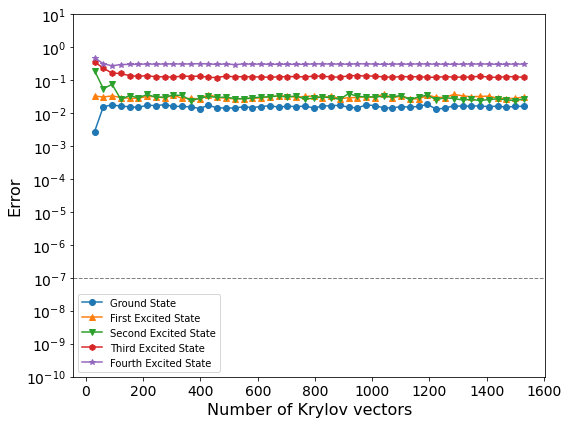

In [213]:
xx = np.linspace(30,30+30*50,50)
y0 = [e_er[i][0] - eigenvalues[1] for i in range(res_num)]
y1 = [e_er[i][1] - eigenvalues[4] for i in range(res_num)]
y2 = [e_er[i][2] - eigenvalues[8] for i in range(res_num)]
y3 = [e_er[i][3] - eigenvalues[9] for i in range(res_num)]
y4 = [e_er[i][4] - eigenvalues[11] for i in range(res_num)]

plt.figure(figsize=(8, 6))

# Plot each segment
plt.plot(xx, y0, 'o-', label="Ground State")
plt.plot(xx, y1, '^-', label="First Excited State")
plt.plot(xx, y2, 'v-', label="Second Excited State")
plt.plot(xx, y3, 'h-', label="Third Excited State")
plt.plot(xx, y4, '*-', label="Fourth Excited State")

# Log scale and axis formatting
plt.yscale('log')
plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Error", fontsize=16)
plt.ylim(1e-10, 1e0)

ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=14)

# Add horizontal line at 1e-7
plt.axhline(y=1e-7, color='gray', linestyle='--', linewidth=1)

# Optional: force y-axis ticks at each 10^-x
yticks = [10**(-i) for i in range(-1,11)]  # 10^0 to 10^-10
plt.yticks(yticks)
formatter = FuncFormatter(lambda y, _: f"$10^{{{int(np.log10(y))}}}$")
ax.yaxis.set_major_formatter(formatter)


plt.legend()
plt.tight_layout()

plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\hei_ritzcombination.pdf")
plt.show()


c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


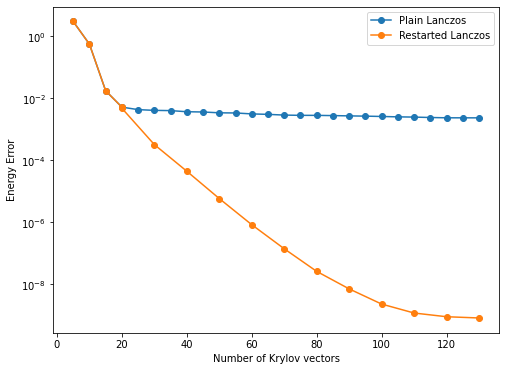

In [16]:
y0_rs = [e_rs[i][0] - eigenvalues[1] for i in range(61)]

y0 = [e_heisenberg[i][0] - eigenvalues[1] for i in range(26)]



plt.figure(figsize=(8, 6))
N_list = np.linspace(5, 130, 26)
# Plot each difference vs. xx
plt.plot(N_list, y0, 'o-', label="Plain Lanczos")

xx1 = N_list[0:4]
xx2 = x_list[0:12]
x= np.concatenate((xx1,np.array(xx2)))
yy1 = y0[0:4]
yy2 = y0_rs[0:12]
y = np.concatenate((yy1,np.array(yy2)))
plt.plot(x,y, 'o-', label="Restarted Lanczos")

plt.yscale('log')

plt.xlabel("Number of Krylov vectors")
plt.ylabel("Energy Error")

plt.legend()
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\compare_rs.pdf")
plt.show()


c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


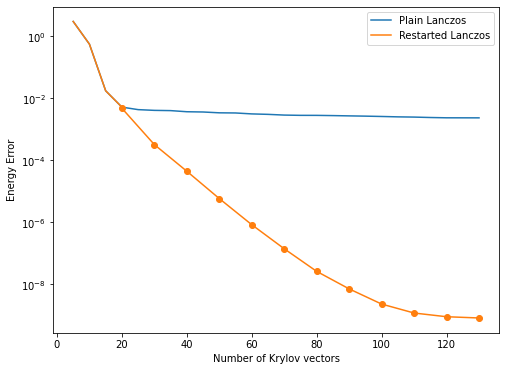

In [19]:
y0_rs = [e_rs[i][0] - eigenvalues[1] for i in range(61)] # Unchanged
y0 = [e_heisenberg[i][0] - eigenvalues[1] for i in range(26)] # Unchanged

plt.figure(figsize=(8, 6)) # Unchanged
N_list = np.linspace(5, 130, 26) # Unchanged

# --- Modifications Start Here ---

# 1. Plot Plain Lanczos: Changed 'o-' to '-'
plt.plot(N_list, y0, '-', label="Plain Lanczos") # MODIFIED STYLE

# Your original way to define components for the restarted plot (unchanged)
xx1 = N_list[0:4]
# NOTE: x_list must be defined before this point in your full script
xx2 = x_list[0:12]
# x= np.concatenate((xx1,np.array(xx2))) # This combined array is no longer plotted directly
yy1 = y0[0:4]
yy2 = y0_rs[0:12]
# y = np.concatenate((yy1,np.array(yy2))) # This combined array is no longer plotted directly

# 2. Plot Restarted Lanczos: Split into two plot calls for different styles
# Get the color of the plain plot to determine the next default color (usually orange)
# Simple approach: assume the second color is 'tab:orange'
restarted_color = 'tab:orange'

# Plot Part 1 (first 4 points, corresponds to N<=20): Line only
plt.plot(xx1, yy1, '-', label="Restarted Lanczos", color=restarted_color) # MODIFIED: Plot part 1, style '-', added color

# Plot Part 2 (next 12 points, corresponds to N>20): Line and markers '.'
plt.plot(xx2, yy2, 'o-', color=restarted_color) # MODIFIED: Plot part 2, style '.-', same color, no label

# --- Modifications End Here ---

plt.yscale('log') # Unchanged

plt.xlabel("Number of Krylov vectors") # Unchanged
plt.ylabel("Energy Error") # Unchanged

plt.legend() # Unchanged
# Ensure the path is correct and directory exists if saving
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\compare_rs.pdf") # Unchanged (but commented out for general execution)


### Thick Restart Lanczos

refer to https://sdm.lbl.gov/~kewu/ps/trlan-siam.pdf .

In [17]:
def solve_ritz_vecs_generalized(folder_containing_Krylov, P, W, n, max_bond, num_ritz, mpo_ref):
    """
    Constructs the Ritz vector MPSs using the stable generalized eigenvalue method.

    Args:
        folder_containing_Krylov (str): Foldername which contains Krylov vectors.
        P (np.ndarray): The projected Hamiltonian in the non-orthogonal basis (<v_i|H|v_j>).
        W (np.ndarray): The Gram matrix of the non-orthogonal basis (<v_i|v_j>).
        n (int): The current size of the Krylov subspace to use.
        max_bond (int): The max_bond used to represent the Ritz vector.
        num_ritz (int): The number of Ritz vectors to calculate.
        mpo_ref (MPO): MPO used to calculate the final energy expectation value.

    Returns:
        test_energy (list): The list of calculated Ritz values (energies).
        krylov_vec (list): A list of the explicitly constructed Ritz vector MPS objects.
    """
    # Step 1: Solve the generalized eigenvalue problem. This is the core change.
    # We solve P*v = e*W*v. The columns of 'v' are the coefficients we need.
    try:
        # We only need the first 'n' vectors from the basis
        e, v = scipy.linalg.eigh(P[:n, :n], W[:n, :n])
    except np.linalg.LinAlgError:
        print("Error: Generalized eigenvalue problem did not converge. W may be singular.")
        return [], []

    ritz_vecs = []
    ritz_vals = []

    print(f"\n--- Constructing {num_ritz} Ritz Vectors from a basis of size {n} ---")

    # Step 2: Loop to construct each of the desired Ritz vectors
    for count in range(num_ritz):
        
        # The k-th column of v gives the coefficients for the k-th Ritz vector.
        # There is no need to multiply by a 'coeff' matrix.
        C_ritz = v[:, count]
        
        # Step 3: Explicitly construct the Ritz vector MPS by summing the basis vectors.
        # NOTE: This part is still computationally expensive and introduces truncation error,
        # but it is necessary if you need the explicit MPS object.
        
        # Load the first basis vector to start the sum
        filename = folder_containing_Krylov + f"/Krylov_vec{0}.pkl"
        with open(filename, 'rb') as file:
            # Use deepcopy to avoid modifying the stored vectors
            ritz_vec = copy.deepcopy(pickle.load(file))
        ritz_vec.A[0] = C_ritz[0] * ritz_vec.A[0]
        
        # Add the remaining weighted basis vectors
        for i in range(1, n):
            filename = folder_containing_Krylov + f"/Krylov_vec{i}.pkl"
            with open(filename, 'rb') as file:
                temp = copy.deepcopy(pickle.load(file))
            
            temp.A[0] = C_ritz[i] * temp.A[0]
            
            # This is the expensive summation and compression step
            ritz_vec = add_mps_and_compress(ritz_vec, temp, 0, 10 * max_bond)

        # Final compression to the target bond dimension
        ritz_vec.compress_direct_svd_right_max_bond(0, max_bond)
        ritz_vec.orthonormalize('right')
        
        # Calculate the expectation value to verify the energy
        e_ritz = operator_average(ritz_vec, mpo_ref)
        
        ritz_vecs.append(ritz_vec)
        # The eigenvalue from the small matrix problem is the more accurate one
        ritz_vals.append(e[count])
        
        print(f"Constructed Ritz vector {count}. Ritz value: {e[count]:.12f}, <H>: {e_ritz:.12f}")

    return ritz_vals, ritz_vecs

In [ ]:
from pytenet.Lanczos import ortho_to_list
def generate_thick_krylov(mps_block,error_block,N_Krylov, H, max_bond_Krylov, trunc_tol, foldername):  
    '''  
    generate orthogonalized Krylov space, and store in disk.

    mps_block: the block of selected ritz vectors, calculated from previous Lanczos loop.
    
    N_Krylov: the size of Krylov space.
    
    H: MPO.
    
    max_bond_Krylov: maximum bond dimension for Krylov vectors.

    trunc_tol: truncation tolerance for Krylov vectors.

    foldername: one must input a foldername where the Krylov vectors are stored in.


    '''
    
    # store the all blocked vectors in disk
    k = copy.deepcopy(len(mps_block))
    mps_block = mps_block+ error_block
    l = copy.deepcopy(len(mps_block))
    for j in range (l):
        filename = foldername + f"/Krylov_vec{j}.pkl"
        with open(filename, 'wb') as file:
            pickle.dump(copy.deepcopy(mps_block[j]), file)
    
    for i in range (N_Krylov):
        
        #show how many Krylov vectors are achieved     
        print(i+l)    
        # if i % 5 == 0:
        #     print("implemented:", i)
        
        #first calculate H \v_i
        #this_state = apply_operator_and_compress(H, copy.deepcopy(ritz_list[i]), trunc_tol, max_bond_Krylov)

        this_state = apply_operator(H, copy.deepcopy(mps_block[i+k]))
        this_state.orthonormalize('right')
        this_state = ortho_to_list(mps_block[-2*k+1:], this_state, max_bond_Krylov, trunc_tol)     

        mps_block.append(this_state)
        print(this_state.bond_dims)
        # store orthogonalized H \v_i in disk.
        filename = foldername + f"/Krylov_vec{i+l}.pkl"
        with open(filename, 'wb') as file:
            pickle.dump(this_state, file)

In [28]:
from pytenet.mps import create_random_mps
mpo_ref =  ptn.heisenberg_xxz_mpo(L = 10, J= -4, D = -4, h= 2)
mpo_ref.zero_qnumbers()
mat = mpo_ref.as_matrix()
realeig, real_vec = np.linalg.eigh(mat)
    #realeig = np.sort(realeig)
rng_master = np.random.default_rng(1234)

N_Krylov = 30
max_bond_Krylov = 6

HFS = create_random_mps([ 1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1], 'right', rng=rng_master)
#max_bond_Krylov = 75
trunc_tol = 1e-12
foldername = f"test_irlm"
generate_krylov_space(N_Krylov, mpo_ref, HFS, max_bond_Krylov, trunc_tol, foldername)
k = 5
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov, foldername, mpo_ref)
W = get_W(N_Krylov, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
e,v_ritz = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, k, mpo_ref)
#e,v_ritz = solve_ritz_vecs_generalized(foldername, H_reduced_non_rotho,W, N_Krylov, max_bond_Krylov, k, mpo_ref)
R_block = []
for j_k in range(k):
    ritz_val = e[j_k]
    ritz_vec = v_ritz[j_k]
    H_phi = apply_operator_and_compress(mpo_ref, ritz_vec, trunc_tol, max_bond_Krylov)
    lambda_phi = copy.deepcopy(ritz_vec)
    lambda_phi.A[0] *= -ritz_val
    residual_vec = add_mps_and_compress(H_phi, lambda_phi, trunc_tol, max_bond_Krylov)
    residual_vec.orthonormalize('right')
    R_block.append(residual_vec)

max_restart_num = 20

for count in range(max_restart_num):
    generate_thick_krylov(v_ritz,R_block, N_Krylov, mpo_ref, max_bond_Krylov, trunc_tol, foldername)
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov, foldername, mpo_ref)
    W = get_W(N_Krylov, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    coeff = coeff[:N_Krylov,:N_Krylov]
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    e,v_ritz = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, k, mpo_ref)
    #e,v_ritz = solve_ritz_vecs_generalized(foldername, H_reduced_non_rotho,W, N_Krylov, max_bond_Krylov, k, mpo_ref)

    R_block = []
    for j_k in range(k):
        ritz_val = e[j_k]
        ritz_vec = v_ritz[j_k]
        H_phi = apply_operator_and_compress(mpo_ref, ritz_vec, trunc_tol, max_bond_Krylov)
        lambda_phi = copy.deepcopy(ritz_vec)
        lambda_phi.A[0] *= -ritz_val
        residual_vec = add_mps_and_compress(H_phi, lambda_phi, trunc_tol, max_bond_Krylov)
        residual_vec.orthonormalize('right')
        R_block.append(residual_vec)
    print(e[:5])
  

[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
2
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
3
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
4
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
5
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
6
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
7
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
8
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
9
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
10
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
11
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
12
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
13
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
14
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
15
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
16
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
17
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
18
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
19
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
20
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
21
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
22
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
23
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
24
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
25
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
26
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
27
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
28
[1, 2, 4,

c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


10
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
11
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
12
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
13
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
14
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
15
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
16
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
17
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
18
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
19
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
20
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
21
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
22
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
23
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
24
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
25
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
26
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
27
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
28
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
29
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
30
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
31
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
32
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
33
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
34
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
35
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
36
[1, 2, 4, 6, 6, 6, 6, 6, 4, 2, 1]
3

In [34]:
W = get_W(N_Krylov, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
coeff = coeff[:N_Krylov,:N_Krylov]
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
e,v_ritz = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, k, mpo_ref)

c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


In [35]:
e1,v_ritz1 = solve_ritz_vecs_generalized(foldername, H_reduced_non_rotho,W, N_Krylov, max_bond_Krylov, k, mpo_ref)


--- Constructing 5 Ritz Vectors from a basis of size 30 ---
Constructed Ritz vector 0. Ritz value: -19.000000000000, <H>: -19.000000000000+0.000000000000j
Constructed Ritz vector 1. Ritz value: -19.000000000000, <H>: -19.000000000000-0.000000000000j
Constructed Ritz vector 2. Ritz value: -16.999999999989, <H>: -16.999999999989-0.000000000000j
Constructed Ritz vector 3. Ritz value: -16.999999995697, <H>: -16.999999995934-0.000000000000j
Constructed Ritz vector 4. Ritz value: -16.804226065131, <H>: -16.804226065132+0.000000000000j


c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


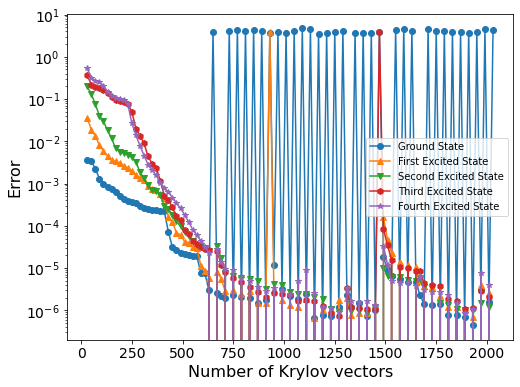

In [210]:
xx = np.linspace(30,30+20*100, 101)

y0 = [e_trl[i][0] - eigenvalues[1] for i in range(101)] # Using index 0 instead of 1
y1 = [e_trl[i][1] - eigenvalues[4] for i in range(101)] # Using index 1 instead of 4
y2 = [e_trl[i][2] - eigenvalues[8] for i in range(101)] # Using index 2 instead of 8
y3 = [e_trl[i][3] - eigenvalues[9] for i in range(101)] # Using index 3 instead of 9
y4 = [e_trl[i][4] - eigenvalues[11] for i in range(101)] # Using index 4 instead of 11



plt.figure(figsize=(8, 6))



# Let's plot the full range as an example, assuming x_list is just 0 to 60
plt.plot(xx, y0, 'o-', label="Ground State")
plt.plot(xx, y1, '^-', label="First Excited State")
plt.plot(xx, y2, 'v-', label="Second Excited State")
plt.plot(xx, y3, 'h-', label="Third Excited State")
plt.plot(xx, y4, '*-', label="Fourth Excited State")


plt.yscale('log')

plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Error", fontsize=16)


ax = plt.gca() 
ax.tick_params(axis='both', which='major', labelsize=14) 
plt.legend()

plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\hei_trl.pdf")
plt.show()








### Restarted Blocked Lanczos

Here we use block Lanczos and during each restart we replace the mpss in block by selected ritz vectors

In [18]:
N_Krylov = 30
max_bond_Krylov = 32
e_band = []
#HFS1 = generate_single_state(7, [3, 3, 3, 3, 3, 0, 0])
N_list = [0]
foldername = f"test_gs"
l = 5
trunc_tol = 10e-14
generate_krylov_space(N_Krylov, mpo_ref, HFS2, max_bond_Krylov, trunc_tol, foldername)
N_use = 30
# C = coeff_canonical_orthogonalization(N_use, foldername)
# vector_list = generate_re_ortho_space_with_coeff(N_use, C, foldername)
#vector_list = generate_re_ortho_space(N_use, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, mpo_ref)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
e0,initial_block = solve_ritz_vecs(foldername, H_reduced, N_use, coeff, max_bond_Krylov, 7, mpo_ref)
initial_block = initial_block[:l]
e_band.append(np.array(e0))

[1, 2, 4, 5, 4, 5, 4, 4, 5, 6, 5, 6, 5, 4, 3, 2, 1]
2
[1, 2, 4, 7, 9, 8, 7, 7, 9, 10, 10, 10, 9, 6, 4, 2, 1]
3
[1, 2, 4, 7, 12, 13, 11, 12, 13, 14, 18, 14, 12, 7, 4, 2, 1]
4
[1, 2, 4, 8, 13, 20, 18, 17, 18, 21, 26, 21, 14, 8, 4, 2, 1]
5
[1, 2, 4, 8, 15, 24, 26, 25, 26, 29, 32, 24, 14, 8, 4, 2, 1]
6
[1, 2, 4, 8, 15, 26, 32, 32, 32, 32, 32, 27, 14, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 29, 15, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
17

In [19]:
num_op = 4
N_Krylov = l * num_op 
num_restart = 1
lock_idx = 0    
lock_thresh = 10e-10
H = mpo_ref
fidelity_band = []
err_var = []
for res in range(num_restart):
    generate_band_krylov(initial_block, N_Krylov, H, max_bond_Krylov, trunc_tol, foldername,lock_idx)
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov+l, foldername, H)
    W = get_W(N_Krylov+l, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    e,initial_block = solve_ritz_vecs(foldername, H_reduced, N_Krylov+l, coeff, max_bond_Krylov, 7, H)
    initial_block = initial_block[:l]
    e_band.append(np.array(e))
    err_temp = []
    fidelity_temp = []
    
    for i in range(l):
        v_test = initial_block[i]
        temp1 = apply_operator(H, v_test)  
        temp2 = add_mps(temp1,v_test,-e_band[-1][i])
        err_temp.append(vdot(temp2,temp2))
    err_var.append(np.array(err_temp))


    #for i in range(l):
    #    ritz_state = initial_block[i].as_vector() 
    #    fidelity_temp.append(1-np.abs(np.dot(real_state[i],ritz_state))**2)
    #fidelity_band.append(np.array(fidelity_temp))

    test = initial_block[lock_idx]
    temp1 = apply_operator(H, test)  
    temp2 = add_mps(temp1,test,-e_band[-1][lock_idx])

    if vdot(temp2,temp2) < lock_thresh:
        lock_idx = lock_idx + 1
        N_Krylov = (l-lock_idx) * num_op
    if lock_idx == l :
        break

    print(f"restart {res} completed")

5
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 29, 32, 32, 32, 32, 32, 29, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 30, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 29, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
17
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 31, 16, 8, 4, 2, 1]
18
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
19
[1, 2, 4, 8, 16, 29, 32, 32, 32, 32, 32, 30, 16, 8, 4, 2, 1]
20
[1, 2, 4, 8, 16, 31, 32, 32, 32, 32, 32, 3

op = 1:[array([0.0019+0.j, 0.0161+0.j, 0.0164+0.j, 0.0329+0.j, 0.0327+0.j])]
op = 2:[array([0.0009+0.j, 0.0089+0.j, 0.0094+0.j, 0.0231+0.j, 0.0281+0.j])]
op = 3:[array([0.0006+0.j, 0.0069+0.j, 0.0075+0.j, 0.0239+0.j, 0.0377+0.j])]
op = 4:[array([0.0005+0.j, 0.006 +0.j, 0.0067+0.j, 0.0294+0.j, 0.0721+0.j])]


c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


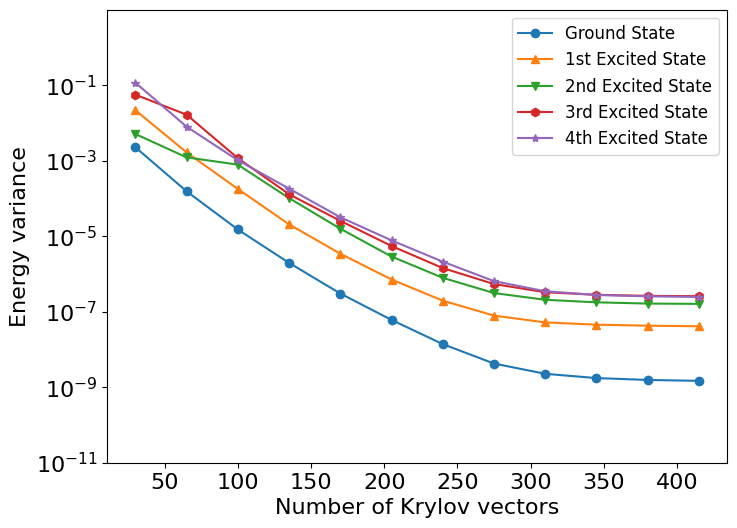

In [132]:
xx = np.linspace(30, 30 + 35 * 11, 12)
y0 = [err_var[i][0] for i in range(12)]
y1 = [err_var[i][1] for i in range(12)]
y2 = [err_var[i][2] for i in range(12)]
y3 = [err_var[i][3] for i in range(12)]
y4 = [err_var[i][4] for i in range(12)]

plt.figure(figsize=(8, 6),dpi=100)

plt.plot(xx, y0, 'o-', label="Ground State")
plt.plot(xx, y1, '^-', label="1st Excited State")
plt.plot(xx, y2, 'v-', label="2nd Excited State")
plt.plot(xx, y3, 'h-', label="3rd Excited State")
plt.plot(xx, y4, '*-', label="4th Excited State")

plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Energy variance", fontsize=16)









plt.ylim(1e-11, 1e1)

ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)

# Add horizontal grid line at 1e-7

# Set log scale
ax.set_yscale('log')


# Force ticks at every 10^-x
ticks = [10**(-i) for i in range(1,12,2)]  # 10^0 to 10^-10
ax.set_yticks(ticks)

# Format them nicely: 10^0, 10^-1, etc.
formatter = FuncFormatter(lambda y, _: f'$10^{{{int(np.log10(y))}}}$' if y in ticks else '')
ax.yaxis.set_major_formatter(formatter)

plt.legend(fontsize = 12)
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\hei_mrl_var.pdf",bbox_inches='tight',
        pad_inches=0.05)
plt.show()


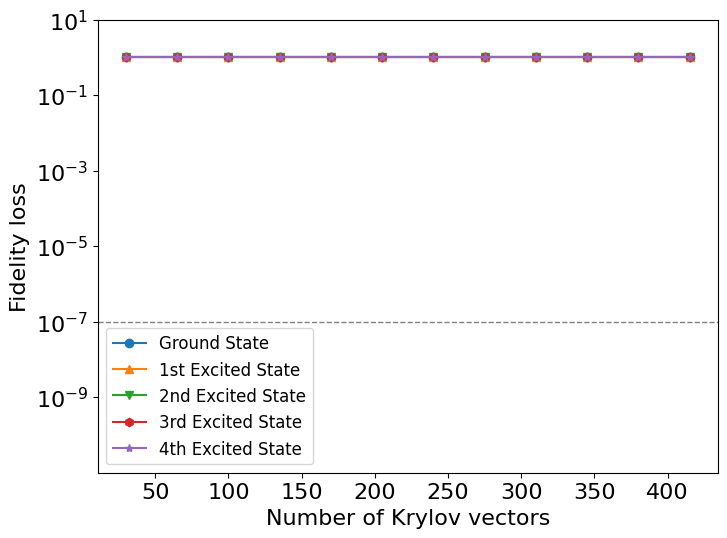

In [953]:
xx = np.linspace(30, 30 + 35 * 11, 12)
y0 = [fidelity_band[i][0] for i in range(12)]
y1 = [fidelity_band[i][1] for i in range(12)]
y2 = [fidelity_band[i][2] for i in range(12)]
y3 = [fidelity_band[i][3] for i in range(12)]
y4 = [fidelity_band[i][4] for i in range(12)]

plt.figure(figsize=(8, 6),dpi=100)

plt.plot(xx, y0, 'o-', label="Ground State")
plt.plot(xx, y1, '^-', label="1st Excited State")
plt.plot(xx, y2, 'v-', label="2nd Excited State")
plt.plot(xx, y3, 'h-', label="3rd Excited State")
plt.plot(xx, y4, '*-', label="4th Excited State")

plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Fidelity loss", fontsize=16)
plt.ylim(1e-11, 1e1)

ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)

# Add horizontal grid line at 1e-7
plt.axhline(y=1e-7, color='gray', linestyle='--', linewidth=1)

# Set log scale
ax.set_yscale('log')


# Force ticks at every 10^-x
ticks = [10**(-i) for i in range(-1,11,2)]  # 10^0 to 10^-10
ax.set_yticks(ticks)

# Format them nicely: 10^0, 10^-1, etc.
formatter = FuncFormatter(lambda y, _: f'$10^{{{int(np.log10(y))}}}$' if y in ticks else '')
ax.yaxis.set_major_formatter(formatter)

plt.legend(fontsize=12)
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\hei_band_fid.pdf")
plt.show()


c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


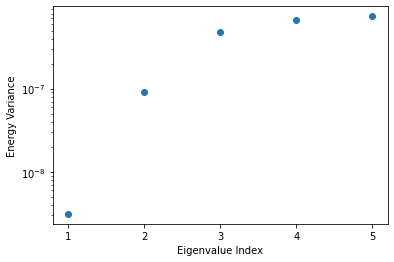

In [52]:
import matplotlib.ticker as mticker
err_var = []
for var_idx in range(5):
    v_test = initial_block[var_idx]
    temp1 = apply_operator(H, v_test)  
    temp2 = add_mps(temp1,v_test,-e_band[-1][var_idx])
    err_var.append(vdot(temp2,temp2))



fig, ax = plt.subplots()
ax.plot(range(1,6), err_var, 'o')

ax.set_xlabel("Eigenvalue Index")
ax.set_ylabel("Energy Variance")
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.yscale('log')
plt.show()

### Bose Hubbard Model

In [2]:
H2 = ptn.bose_hubbard_mpo(d = 2, L = 16, t = 1, U = 1, mu = 0)
matrix2 = H2.as_matrix( sparse_format=True)
np.shape(matrix2)
mpo_ref = H2

In [5]:
eigenvalues, vecs = eigsh(matrix2, k=20, which='SA', return_eigenvectors=True)
print(eigenvalues)

[-9.838  -9.6534 -9.4689 -9.2906 -9.6534 -9.2906 -9.1061 -8.9465 -8.9216
 -9.1061 -8.7433 -8.9465 -8.9216 -9.1061 -8.6327 -9.1061 -8.6327 -8.7619
 -8.7619 -8.7619]


In [8]:
gs_vec = copy.deepcopy(vecs.T[0])
gs_mps = ptn.MPS.from_vector(2,16,gs_vec)
gs_mps.orthonormalize("right")
gs_mps.compress_direct_svd_left_max_bond(tol=0,max_bond=30)
operator_average(gs_mps, mpo_ref) - eigenvalues[0]

np.complex128(2.3062938225848484e-09-5.551115123125783e-16j)

In [ ]:
opt_gs_err = []
opt_1st_err = []
opt_2nd_err = []
opt_3rd_err = []
opt_4th_err = []
bond_dim_list = [5,10,20,30,40,50,60,70,80,90,100,110,120,130,140,150,160,170,180,186]
for i in bond_dim_list:
    gs_vec = copy.deepcopy(vecs.T[0])
    ex1st_vec = copy.deepcopy(vecs.T[1])
    ex2nd_vec = copy.deepcopy(vecs.T[2])
    ex3rd_vec = copy.deepcopy(vecs.T[3])
    ex4th_vec = copy.deepcopy(vecs.T[4])
    gs_mps = ptn.MPS.from_vector(2,16,gs_vec)
    ex1st_mps = ptn.MPS.from_vector(2,16,ex1st_vec)
    ex2nd_mps = ptn.MPS.from_vector(2,16,ex2nd_vec)
    ex3rd_mps = ptn.MPS.from_vector(2,16,ex3rd_vec)
    ex4th_mps = ptn.MPS.from_vector(2,16,ex4th_vec)
    gs_mps.orthonormalize("right")
    ex1st_mps.orthonormalize("right")
    ex2nd_mps.orthonormalize("right")
    ex3rd_mps.orthonormalize("right")
    ex4th_mps.orthonormalize("right")
    gs_mps.compress_no_normalization_max_bond(tol=0,max_bond=i)

    gs_mps.orthonormalize("right")
    gs_mps.orthonormalize("left")

    ex1st_mps.compress_direct_svd_left_max_bond(tol=0,max_bond=i)
  
    ex2nd_mps.compress_no_normalization_max_bond(tol=0,max_bond=i)
    ex3rd_mps.compress_no_normalization_max_bond(tol=0,max_bond=i)
    ex4th_mps.compress_no_normalization_max_bond(tol=0,max_bond=i)
    opt_gs_err.append(np.linalg.norm(operator_average(gs_mps, mpo_ref) - eigenvalues[0]))
    opt_1st_err.append(np.linalg.norm(operator_average(ex1st_mps, mpo_ref) - eigenvalues[1]))
    opt_2nd_err.append(np.linalg.norm(operator_average(ex2nd_mps, mpo_ref) - eigenvalues[2]))
    opt_3rd_err.append(np.linalg.norm(operator_average(ex3rd_mps, mpo_ref) - eigenvalues[3]))
    opt_4th_err.append(np.linalg.norm(operator_average(ex4th_mps, mpo_ref) - eigenvalues[4]))

###(1.8053718520150142e-09+0j) for 30

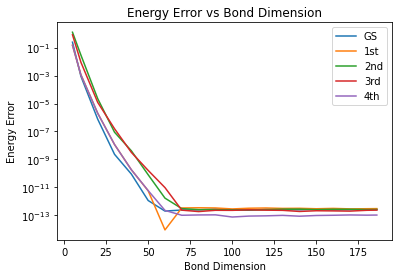

In [10]:
plt.plot(bond_dim_list,opt_gs_err)
plt.plot(bond_dim_list,opt_1st_err)
plt.plot(bond_dim_list,opt_2nd_err)
plt.plot(bond_dim_list,opt_3rd_err)
plt.plot(bond_dim_list,opt_4th_err)
plt.legend(["GS","1st","2nd","3rd","4th"])
plt.xlabel("Bond Dimension")
plt.ylabel("Energy Error")
plt.title("Energy Error vs Bond Dimension")
plt.yscale("log")

In [12]:
HFS_bose = generate_single_state_bose(16, [1, 1, 0, 1, 0, 0, 0,1,1, 1, 1, 0, 0, 0, 0,1 ],2)
HFS_bose1 = generate_single_state_bose(16, [0,0 , 1, 1, 1, 0, 0,1,1, 1, 1, 0, 0, 0, 0,1 ],2)
HFS_bose2 = generate_single_state_bose(16, [1, 1, 0, 1, 0, 0, 0,1,1, 1, 1, 0, 0, 0, 0,1 ],2)
HFS_bose3 = generate_single_state_bose(16, [1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0,0 ],2)
HFS_bose4 = generate_single_state_bose(16, [0, 0, 0, 0, 0, 0, 0, 0,1, 1, 1, 1, 1, 1, 1,1 ],2)
HFS_bose5 = generate_single_state_bose(16, [0,0 , 1, 1, 0, 0, 1,1,0, 0, 1, 1, 0, 0, 1,1 ],2)
HFS_bose.orthonormalize('right')




np.float64(1.0)

Plain Lanczos

In [40]:
N_Krylov = 100
psi_original = copy.deepcopy(HFS_bose)
max_bond_Krylov = 50
#max_bond_Krylov = 75
trunc_tol = 0
foldername = f"test"
e_bose = [] 

#HFS1 = generate_single_state(7, [3, 3, 3, 3, 3, 0, 0])
N_list = []
foldername = f"test"
generate_krylov_space(N_Krylov, H2, HFS_bose, max_bond_Krylov, trunc_tol, foldername) 

N_use = 100
# C = coeff_canonical_orthogonalization(N_use, foldername)
# vector_list = generate_re_ortho_space_with_coeff(N_use, C, foldername)
#vector_list = generate_re_ortho_space(N_use, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, H2)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
for N in range(5, N_use+1, 5):
    N_list.append(N)
    H_part = H_reduced[:N, :N]
    e_rotate, v_rotate = np.linalg.eigh(H_part)
    e_bose.append(e_rotate)


    
   


[1, 1, 2, 3, 3, 2, 2, 3, 2, 2, 2, 3, 2, 2, 2, 2, 1]
2
[1, 2, 3, 6, 10, 9, 9, 12, 8, 7, 9, 9, 5, 3, 3, 2, 1]
3
[1, 2, 4, 7, 13, 25, 39, 50, 41, 37, 29, 23, 12, 7, 4, 2, 1]
4
[1, 2, 4, 8, 16, 30, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 30, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 30, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
17


c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


In [88]:
### Here we have no truncation, for testing the eigenvalues
N_Krylov = 100
max_bond_Krylov = 300
#max_bond_Krylov = 75
trunc_tol = 0
foldername = f"test"
N_list = []
foldername = f"test"
generate_krylov_space(N_Krylov, H2, HFS_bose, max_bond_Krylov, trunc_tol, foldername) 

N_use = 100
# C = coeff_canonical_orthogonalization(N_use, foldername)
# vector_list = generate_re_ortho_space_with_coeff(N_use, C, foldername)
#vector_list = generate_re_ortho_space(N_use, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, mpo_ref)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
e_real = np.linalg.eigvalsh(H_reduced)
e_real

[1, 1, 2, 3, 3, 2, 2, 3, 2, 2, 2, 3, 2, 2, 2, 2, 1]
2
[1, 2, 3, 6, 10, 9, 9, 12, 8, 7, 9, 9, 5, 3, 3, 2, 1]
3
[1, 2, 4, 7, 13, 25, 39, 63, 41, 37, 29, 23, 12, 7, 4, 2, 1]
4
[1, 2, 4, 8, 16, 30, 60, 115, 183, 96, 56, 31, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 32, 63, 125, 244, 125, 63, 32, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 32, 64, 127, 253, 127, 64, 32, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 32, 64, 128, 254, 127, 64, 32, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 32, 64, 128, 255, 128, 64, 32, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 32, 64, 128, 255, 128, 64, 32, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 32, 64, 128,

array([-9.838 , -9.4689, -9.1061, -8.7619, -8.7433, -8.4481, -8.3991,
       -8.3742, -8.1754, -8.0849, -8.0306, -7.9531, -7.8014, -7.7046,
       -7.6344, -7.4917, -7.3483, -7.2231, -7.0536, -6.9265, -6.7395,
       -6.5964, -6.4181, -6.2424, -6.0353, -5.8736, -5.6581, -5.4575,
       -5.2597, -5.0289, -4.8265, -4.5965, -4.3755, -4.1498, -3.9206,
       -3.6726, -3.442 , -3.1916, -2.9432, -2.703 , -2.4541, -2.204 ,
       -1.9477, -1.6916, -1.4416, -1.1727, -0.9125, -0.6558, -0.3955,
       -0.1432,  0.1432,  0.3955,  0.6558,  0.9125,  1.1727,  1.4416,
        1.6916,  1.9477,  2.204 ,  2.4541,  2.703 ,  2.9432,  3.1916,
        3.442 ,  3.6725,  3.9206,  4.1498,  4.3754,  4.5965,  4.8265,
        5.0289,  5.2597,  5.4575,  5.6581,  5.8736,  6.0353,  6.2423,
        6.4181,  6.5964,  6.7395,  6.9264,  7.0535,  7.2231,  7.3483,
        7.4916,  7.6344,  7.7045,  7.8014,  7.9531,  8.0306,  8.0849,
        8.1754,  8.3742,  8.3991,  8.4481,  8.7433,  8.7619,  9.1061,
        9.4689,  9.8

In [117]:
eigenvalues[0]-e_real[0]
eigenvalues[2]-e_real[1]
eigenvalues[-5]-e_real[2]
eigenvalues[-1]-e_real[3]

np.float64(2.639666263348772e-12)

In [118]:
e,v = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, N_Krylov, H2)


In [138]:
numsweeps = 50
HFS_bose = generate_single_state_bose(16, [1, 1, 0, 1, 0, 0, 0,1,1, 1, 1, 0, 0, 0, 0,1 ],2)
en_sweeps = dmrg_twosite(H2,HFS_bose, numsweeps,25,0)

# value after last iteration
e0 = en_sweeps[-1]
en_sweeps

array([-9.1167, -9.815 , -9.8379, -9.838 , -9.838 , -9.838 , -9.838 ,
       -9.838 , -9.838 , -9.838 , -9.838 , -9.838 , -9.838 , -9.838 ,
       -9.838 , -9.838 , -9.838 , -9.838 , -9.838 , -9.838 , -9.838 ,
       -9.838 , -9.838 , -9.838 , -9.838 , -9.838 , -9.838 , -9.838 ,
       -9.838 , -9.838 , -9.838 , -9.838 , -9.838 , -9.838 , -9.838 ,
       -9.838 , -9.838 , -9.838 , -9.838 , -9.838 , -9.838 , -9.838 ,
       -9.838 , -9.838 , -9.838 , -9.838 , -9.838 , -9.838 , -9.838 ,
       -9.838 ])

In [139]:
HFS_bose.compress_no_normalization_max_bond(tol = 0,max_bond=50)
print(HFS_bose.bond_dims)
operator_average(HFS_bose,H2)-eigenvalues[0]

[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]


np.complex128(1.2256862191861728e-12+0j)

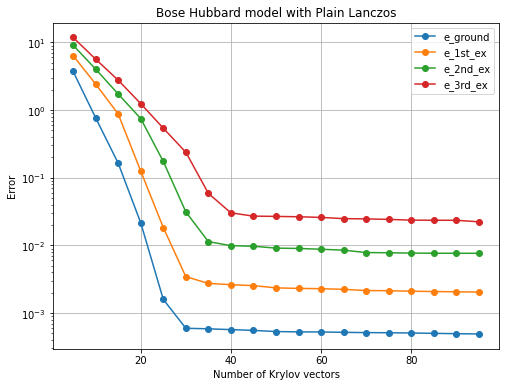

In [ ]:
# Build the y-values for each of the five difference
y0 = [e_bose[i][0] - eigenvalues[-1] for i in range(19)]
y1 = [e_bose[i][1] - eigenvalues[-4] for i in range(19)]
y2 = [e_bose[i][2] - eigenvalues[-7] for i in range(19)]
y3 = [e_bose[i][3] - eigenvalues[5] for i in range(19)]


plt.figure(figsize=(8, 6))
N_list = np.linspace(5, 95, 19)
# Plot each difference vs. xx
plt.plot(N_list, y0, 'o-', label="e_ground")
plt.plot(N_list, y1, 'o-', label="e_1st_ex")
plt.plot(N_list, y2, 'o-', label="e_2nd_ex")
plt.plot(N_list, y3, 'o-', label="e_3rd_ex")


plt.yscale('log')

plt.xlabel("Number of Krylov vectors")
plt.ylabel("Error")
plt.title("Bose Hubbard model with Plain Lanczos")
plt.legend()
plt.grid(True)
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\bose_plain.pdf")
plt.show()


Expcilitly Restart

In [ ]:
N_Krylov = 30
max_bond_Krylov = 50
trunc_tol = 0
foldername = f"TRL_1"

generate_krylov_space(N_Krylov, H2, HFS_bose, max_bond_Krylov, trunc_tol, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov, foldername, H2)
W = get_W(N_Krylov, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
k = 1
e,v = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, 5, H2)
e_rs = []
e_rs.append(np.array(e))
v = v[:k]
N_Krylov_restart = 10 
x_list = [30]
j = 0
max_restart_num = 56
count = 0
while count < max_restart_num:
    generate_restart_with_ritz(v, N_Krylov_restart, H2, max_bond_Krylov, trunc_tol, foldername)
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov_restart, foldername, H2)
    W = get_W(N_Krylov_restart, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    # Note: solve_ritz_vecs requested 5 vectors, ensure this is intended
    e_ritz, v_ritz = solve_ritz_vecs(foldername, H_reduced, N_Krylov_restart, coeff, max_bond_Krylov, 5, H2)
    e_rs.append(np.array(e_ritz))
    x_list.append(x_list[-1]+N_Krylov_restart)
    v = v_ritz[:k]
    if j == 13: 
        print("Now restart"+ str(k+1) + "Ritz vector(s)")
        k = k+1
        j = 0
        N_Krylov_restart = N_Krylov_restart + 1 
    count += 1
    j += 1
   

    print("Now restart"+ str(count) + "times")

[1, 1, 2, 3, 3, 2, 2, 3, 2, 2, 2, 3, 2, 2, 2, 2, 1]
2
[1, 2, 3, 6, 10, 9, 9, 12, 8, 7, 9, 9, 5, 3, 3, 2, 1]
3
[1, 2, 4, 7, 13, 25, 39, 50, 41, 37, 29, 23, 12, 7, 4, 2, 1]
4
[1, 2, 4, 8, 16, 30, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 30, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 30, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
17


c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


2
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
3
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
4
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
Now restart1times
2
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
3
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
4
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50

c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


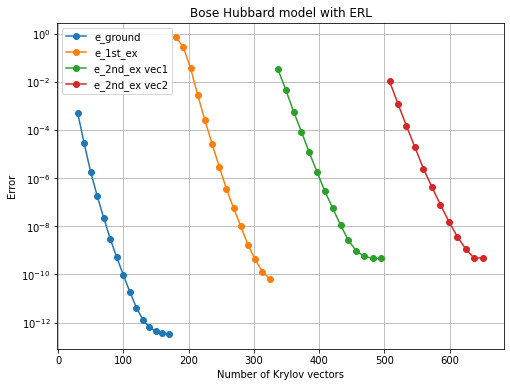

In [20]:
# Build the y-values for each of the five difference
y0 = [e_rs[i][0] - eigenvalues[0] for i in range(57)]
y1 = [e_rs[i][1] - eigenvalues[2] for i in range(57)]
y2 = [e_rs[i][2] - eigenvalues[6] for i in range(57)]
y3 = [e_rs[i][3] - eigenvalues[6] for i in range(57)]
y4 = [e_rs[i][4] - eigenvalues[-1] for i in range(57)]


plt.figure(figsize=(8, 6))


# Plot each difference vs. xx
plt.plot(x_list[0:15],y0[0:15], 'o-', label="e_ground")
plt.plot(x_list[15:29], y1[15:29], 'o-', label="e_1st_ex")
plt.plot(x_list[29:43], y2[29:43], 'o-', label="e_2nd_ex vec1")
plt.plot(x_list[43:55], y3[43:55], 'o-', label="e_2nd_ex vec2")



plt.yscale('log')

plt.xlabel("Number of Krylov vectors")
plt.ylabel("Error")
plt.title("Bose Hubbard model with ERL")
plt.legend()
plt.grid(True)
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\bose_erl.pdf")
plt.show()

TRL

In [10]:
N_Krylov = 30
max_bond_Krylov = 50
#max_bond_Krylov = 75
trunc_tol = 0
foldername = f"test_irlm"
generate_krylov_space(N_Krylov+1, H2, HFS_bose, max_bond_Krylov, trunc_tol, foldername)
k = 10
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov, foldername, mpo_ref)
W = get_W(N_Krylov, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
e,v_ritz = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, N_Krylov, H2)
e_trl = [e[:4]]
v = v_ritz[:k]
filename = foldername + f"/Krylov_vec{N_Krylov}.pkl"
with open(filename, 'rb') as file:
    temp1 = pickle.load(file)
v.append(temp1)
max_restart_num = 10

for count in range(max_restart_num):
    generate_restart_with_ritz(v, N_Krylov+1, H2, max_bond_Krylov, trunc_tol, foldername)
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov, foldername, mpo_ref)
    W = get_W(N_Krylov, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    coeff = coeff[:N_Krylov,:N_Krylov]
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    e,v_ritz = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, k, H2)

    e_trl.append(e[:4])
    v = v_ritz[:k]
    with open(filename, 'rb') as file:
        temp1 = pickle.load(file)
    v.append(temp1)
    print("restart "+ str(count))
  

[1, 1, 2, 3, 3, 2, 2, 3, 2, 2, 2, 3, 2, 2, 2, 2, 1]
2
[1, 2, 3, 6, 10, 9, 9, 12, 8, 7, 9, 9, 5, 3, 3, 2, 1]
3
[1, 2, 4, 7, 13, 25, 39, 50, 41, 37, 29, 23, 12, 7, 4, 2, 1]
4
[1, 2, 4, 8, 16, 30, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 30, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 30, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 31, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
17


c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


12
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
17
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
18
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
19
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
20
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
21
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
22
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
23
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
24
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
25
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
26
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
27
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 

c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


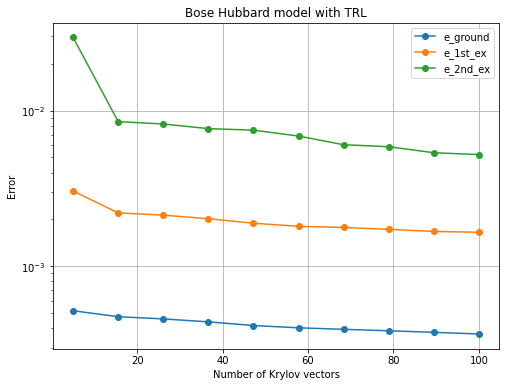

In [11]:
# Build the y-values for each of the five difference
y0 = [e_trl[i][0] - e_real[0] for i in range(10)]
y1 = [e_trl[i][1] - e_real[1] for i in range(10)]
y2 = [e_trl[i][2] - e_real[2] for i in range(10)]




plt.figure(figsize=(8, 6))
N_list = np.linspace(5, 100, 10)
# Plot each difference vs. xx
plt.plot(N_list, y0, 'o-', label="e_ground")
plt.plot(N_list, y1, 'o-', label="e_1st_ex")
plt.plot(N_list, y2, 'o-', label="e_2nd_ex")



plt.yscale('log')

plt.xlabel("Number of Krylov vectors")
plt.ylabel("Error")
plt.title("Bose Hubbard model with TRL")
plt.legend()
plt.grid(True)
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\bose_trl.pdf")
plt.show()


Restarted Block Lanczos

In [22]:
N_Krylov = 60
max_bond_Krylov = 50
e_band = []
#HFS1 = generate_single_state(7, [3, 3, 3, 3, 3, 0, 0])
N_list = [0]
foldername = f"test_gs"
l = 4
trunc_tol = 0
lock_idx = 0
initial_block = [HFS_bose1,HFS_bose2,HFS_bose3,HFS_bose4,HFS_bose5]
N_use = 60+l
generate_band_krylov(initial_block, N_Krylov, H2, max_bond_Krylov, trunc_tol, foldername,0)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, H2)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
e0,initial_block = solve_ritz_vecs(foldername, H_reduced, N_use, coeff, max_bond_Krylov, 5, H2)
initial_block = initial_block[:l]
e_band.append(np.array(e0))

5
[1, 1, 2, 2, 2, 3, 2, 3, 2, 2, 2, 3, 2, 2, 2, 2, 1]
6
[1, 1, 2, 3, 3, 2, 2, 3, 2, 2, 2, 3, 2, 2, 2, 2, 1]
7
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
8
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
9
[1, 1, 2, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 2, 1, 1]
10
[1, 2, 3, 6, 9, 15, 18, 23, 19, 16, 16, 14, 10, 6, 4, 2, 1]
11
[1, 2, 4, 8, 14, 21, 33, 45, 36, 30, 26, 22, 13, 8, 4, 2, 1]
12
[1, 1, 1, 1, 1, 1, 1, 2, 3, 2, 1, 1, 1, 1, 1, 1, 1]
13
[1, 1, 1, 1, 1, 1, 1, 2, 3, 2, 1, 1, 1, 1, 1, 1, 1]
14
[1, 2, 4, 8, 15, 25, 41, 50, 50, 50, 41, 26, 15, 8, 4, 2, 1]
15
[1, 2, 4, 8, 15, 26, 47, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 15, 29, 47, 50, 50, 50, 50, 30, 16, 8, 4, 2, 1]
17
[1, 1, 1, 1, 1, 1, 2, 3, 5, 3, 2, 1, 1, 1, 1, 1, 1]
18
[1, 1, 1, 2, 4, 7, 13, 24, 40, 50, 50, 30, 15, 8, 4, 2, 1]
19
[1, 2, 4, 8, 15, 30, 50, 50, 50, 50, 50, 31, 16, 8, 4, 2, 1]
20
[1, 2, 4, 8, 15, 30, 49, 49, 50, 50, 50, 30, 16, 8, 4, 2, 1]
21
[1, 2, 4, 8, 16, 30, 50, 50, 50, 50, 50, 30, 16, 8, 4

c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


In [23]:
num_op = 5
N_Krylov = l * num_op 
num_restart = 20
lock_idx = 0    

for res in range(num_restart):
    generate_band_krylov(initial_block, N_Krylov, H2, max_bond_Krylov, trunc_tol, foldername,0)
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov+l, foldername, H2)
    W = get_W(N_Krylov+l, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    e,initial_block = solve_ritz_vecs(foldername, H_reduced, N_Krylov+l, coeff, max_bond_Krylov, 5, H2)
    initial_block = initial_block[:l]
    e_band.append(np.array(e))
    #data_band = np.array([np.abs(arr) for arr in err_band])
    #if len(data_band) > 2 and data_band[-1,lock_idx] / data_band[-2,lock_idx] > 0.99:
    #    lock_idx += 1
    #    l -= 1
    #N_Krylov = l*num_op
    #xx1.append(xx1[-1]+N_Krylov)
    print(f"restart {res} completed")

4
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
17
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
18
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32, 16, 8, 4, 2, 1]
19
[1, 2, 4, 8, 16, 32, 50, 50, 50, 50, 50, 32

c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


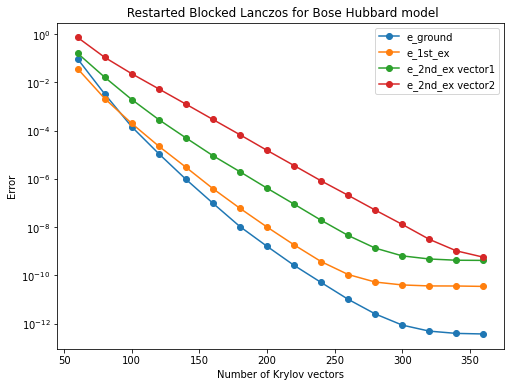

In [27]:
xx = np.linspace(60,60 + 20*15 , 16)

# Suppose err_band is a 2D list/array with shape (10, 5) or larger
# and you have defined your reference energies:
# e_ground, e_1st_ex, e_2nd_ex

# Build the y-values for each of the five differences
y0 = [e_band[i][0] - eigenvalues[0] for i in range(16)]
y1 = [e_band[i][1] - eigenvalues[2] for i in range(16)]
y2 = [e_band[i][2] - eigenvalues[6] for i in range(16)]
y3 = [e_band[i][3] - eigenvalues[6] for i in range(16)]
#y4 = [e_band[i][4] - eigenvalues[-15] for i in range(15)]


plt.figure(figsize=(8, 6))

# Plot each difference vs. xx
plt.plot(xx, y0, 'o-', label="e_ground")
plt.plot(xx, y1, 'o-', label="e_1st_ex")
plt.plot(xx, y2, 'o-', label="e_2nd_ex vector1")
plt.plot(xx, y3, 'o-', label="e_2nd_ex vector2")



plt.yscale('log')

plt.xlabel("Number of Krylov vectors")
plt.ylabel("Error")
plt.title(" Restarted Blocked Lanczos for Bose Hubbard model")
plt.legend()
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\bose_brl.pdf")
plt.show()


Here we found band lanczos can find degenerate eigen state, which is the same case as of classical matrix-vector lanczos.

### Fermi Hubbard Model

In [48]:
H3 = ptn.fermi_hubbard_mpo(L=8, t = 1, U = 4, mu = 0)
mpo_ref = H3
matrix3 = H3.as_matrix(sparse_format=True)
eigenvalues,vecs_fermi = eigsh(matrix3, k=20, which='SA', return_eigenvectors= True)
eigenvalues


###-13.7535, -13.481 , -13.1568, -13.0503, -12.8883

array([-12.2358, -11.9165, -11.9165, -11.9165, -11.4213, -11.5402,
       -11.5402, -11.5402, -11.1753, -11.0927, -11.2291, -11.2291,
       -11.2291, -11.2506, -11.1753, -11.1753, -11.2506, -11.2506,
       -11.2506, -11.0242])

In [62]:
from typing import List
import random   

def generate_spin_states_half_occupied(n: int) -> List[int]:
    """
    Generate a list of length n with entries in {0,1,2,3} encoding spin states:
      0 → unoccupied
      1 → spin up only
      2 → spin down only
      3 → both spin up and spin down (double occupancy)

    Constraints:
      - Net spin = 0 (total up events == total down events)
      - Half‐filling: exactly n/2 up‐spin events and n/2 down‐spin events

    Args:
        n: Desired length of the list. Must be even.

    Returns:
        A shuffled list of length n satisfying the above constraints.

    Raises:
        ValueError: If n is not even.
    """
    if n % 2 != 0:
        raise ValueError("List length must be even for half‐filling and net zero spin.")

    half = n // 2  # target number of up events and down events

    # Let c = number of doubly‐occupied sites (3) and also number of empty sites (0)
    # Then a = number of spin‐up‐only (1) = half - c
    #       b = number of spin‐down‐only (2) = half - c
    # total sites: a + b + c + c = 2*(half - c) + 2c = 2*half = n
    c = random.randint(0, half)
    a = half - c
    b = a
    zeros = c
    double_occ = c

    result = [1]*a + [2]*b + [3]*double_occ + [0]*zeros
    random.shuffle(result)
    return result

list_fermi0 = generate_spin_states_half_occupied(8)
list_fermi1 = generate_spin_states_half_occupied(8)
list_fermi2 = generate_spin_states_half_occupied(8)
list_fermi3 = generate_spin_states_half_occupied(8)
list_fermi4 = generate_spin_states_half_occupied(8)
list_fermi5 = generate_spin_states_half_occupied(8)

HFS_fermi0 = ptn.hartree_fock_mps.generate_single_state(8, list_fermi0)
HFS_fermi1 = ptn.hartree_fock_mps.generate_single_state(8,list_fermi1)
HFS_fermi2 = ptn.hartree_fock_mps.generate_single_state(8,list_fermi2)
HFS_fermi3 = ptn.hartree_fock_mps.generate_single_state(8,list_fermi3)
HFS_fermi4 = ptn.hartree_fock_mps.generate_single_state(8,list_fermi4)
HFS_fermi5 = ptn.hartree_fock_mps.generate_single_state(8,list_fermi5)

HFS  = add_mps(HFS_fermi0,HFS_fermi1)
HFS = add_mps(HFS,HFS_fermi2)
HFS = add_mps(HFS,HFS_fermi3)
HFS = add_mps(HFS,HFS_fermi4)
HFS = add_mps(HFS,HFS_fermi5)
HFS.orthonormalize('right')


numsweeps = 5
H_dmrg = ptn.fermi_hubbard_mpo(L=8, t = 1, U = 0, mu = 0)
dmrg_twosite(H_dmrg, HFS, numsweeps,25, 0)
HFS = HFS 
HFS.orthonormalize('right')

np.float64(1.0000000000000009)

In [9]:
### Here we have no truncation, for testing the eigenvalues
N_Krylov = 100
max_bond_Krylov = 500
#max_bond_Krylov = 75
trunc_tol = 0
N_list = []
foldername = f"test"
generate_krylov_space(N_Krylov, H3, HFS, max_bond_Krylov, trunc_tol, foldername) 

N_use = 75
# C = coeff_canonical_orthogonalization(N_use, foldername)
# vector_list = generate_re_ortho_space_with_coeff(N_use, C, foldername)
#vector_list = generate_re_ortho_space(N_use, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, mpo_ref)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
e_real = np.linalg.eigvalsh(H_reduced)
e_real


[1, 3, 3, 4, 3, 4, 3, 3, 1]
2
[1, 4, 11, 22, 27, 28, 14, 4, 1]
3
[1, 4, 16, 53, 161, 57, 16, 4, 1]
4
[1, 4, 16, 62, 230, 63, 16, 4, 1]
5
[1, 4, 16, 64, 249, 63, 16, 4, 1]
6
[1, 4, 16, 64, 252, 63, 16, 4, 1]
7
[1, 4, 16, 64, 252, 63, 16, 4, 1]
8
[1, 4, 16, 64, 252, 63, 16, 4, 1]
9
[1, 4, 16, 64, 255, 64, 16, 4, 1]
10
[1, 4, 16, 64, 255, 64, 16, 4, 1]
11
[1, 4, 16, 64, 255, 64, 16, 4, 1]
12
[1, 4, 16, 64, 255, 64, 16, 4, 1]
13
[1, 4, 16, 64, 255, 64, 16, 4, 1]
14
[1, 4, 16, 64, 255, 64, 16, 4, 1]
15
[1, 4, 16, 64, 256, 64, 16, 4, 1]
16
[1, 4, 16, 64, 256, 64, 16, 4, 1]
17
[1, 4, 16, 64, 256, 64, 16, 4, 1]
18
[1, 4, 16, 64, 256, 64, 16, 4, 1]
19
[1, 4, 16, 64, 256, 64, 16, 4, 1]
20
[1, 4, 16, 64, 256, 64, 16, 4, 1]
21
[1, 4, 16, 64, 256, 64, 16, 4, 1]
22
[1, 4, 16, 64, 256, 64, 16, 4, 1]
23
[1, 4, 16, 64, 256, 64, 16, 4, 1]
24
[1, 4, 16, 64, 256, 64, 16, 4, 1]
25
[1, 4, 16, 64, 256, 64, 16, 4, 1]
26
[1, 4, 16, 64, 256, 64, 16, 4, 1]
27
[1, 4, 16, 64, 256, 64, 16, 4, 1]
28
[1, 4, 16, 64, 2

array([-13.7535, -13.481 , -13.1568, -13.0503, -12.8883, -12.8349,
       -12.7125, -12.4267, -12.3084, -12.111 , -11.9058, -11.6165,
       -11.307 , -10.9908, -10.6666, -10.0961,  -9.8956,  -9.3618,
        -9.1126,  -8.6629,  -8.1809,  -7.8693,  -7.4169,  -6.9641,
        -6.5522,  -6.0679,  -5.6053,  -5.0917,  -4.5248,  -4.0424,
        -3.453 ,  -2.9132,  -2.4464,  -1.9035,  -1.4335,  -0.9093,
        -0.4196,   0.1194,   0.6099,   1.2134,   1.7499,   2.2897,
         2.7819,   3.3411,   3.8174,   4.3253,   4.7898,   5.2581,
         5.6925,   6.1455,   6.5527,   6.9842,   7.4341,   7.8128,
         8.2708,   8.6166,   8.9999,   9.4709,   9.7051,  10.2422,
        10.5275,  10.8485,  11.1224,  11.3919,  11.6483,  11.8279,
        12.0383,  12.1146,  12.3893,  12.5096,  12.5689,  12.7303,
        12.8368,  13.161 ,  13.4335])

Plain Lanczos

In [51]:
N_Krylov = 100
psi_original = copy.deepcopy(HFS)
max_bond_Krylov = 64
#max_bond_Krylov = 75
trunc_tol = 0
foldername = f"test"
e_fermi = [] 


N_list = []
foldername = f"test"
generate_krylov_space(N_Krylov, H3, HFS, max_bond_Krylov, trunc_tol, foldername) 

N_use = 100
# C = coeff_canonical_orthogonalization(N_use, foldername)
# vector_list = generate_re_ortho_space_with_coeff(N_use, C, foldername)
#vector_list = generate_re_ortho_space(N_use, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, H3)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
for N in range(5, N_use+1, 5):
    N_list.append(N)
    H_part = H_reduced[:N, :N]
    e_rotate, v_rotate = np.linalg.eigh(H_part)
    e_fermi.append(e_rotate)

[1, 4, 16, 64, 64, 64, 16, 4, 1]
2
[1, 4, 16, 64, 64, 64, 16, 4, 1]
3
[1, 4, 16, 64, 64, 64, 16, 4, 1]
4
[1, 4, 16, 64, 64, 64, 16, 4, 1]
5
[1, 4, 16, 64, 64, 64, 16, 4, 1]
6
[1, 4, 16, 64, 64, 64, 16, 4, 1]
7
[1, 4, 16, 64, 64, 64, 16, 4, 1]
8
[1, 4, 16, 64, 64, 64, 16, 4, 1]
9
[1, 4, 16, 64, 64, 64, 16, 4, 1]
10
[1, 4, 16, 64, 64, 64, 16, 4, 1]
11
[1, 4, 16, 64, 64, 64, 16, 4, 1]
12
[1, 4, 16, 64, 64, 64, 16, 4, 1]
13
[1, 4, 16, 64, 64, 64, 16, 4, 1]
14
[1, 4, 16, 64, 64, 64, 16, 4, 1]
15
[1, 4, 16, 64, 64, 64, 16, 4, 1]
16
[1, 4, 16, 64, 64, 64, 16, 4, 1]
17
[1, 4, 16, 64, 64, 64, 16, 4, 1]
18
[1, 4, 16, 64, 64, 64, 16, 4, 1]
19
[1, 4, 16, 64, 64, 64, 16, 4, 1]
20
[1, 4, 16, 64, 64, 64, 16, 4, 1]
21
[1, 4, 16, 64, 64, 64, 16, 4, 1]
22
[1, 4, 16, 64, 64, 64, 16, 4, 1]
23
[1, 4, 16, 64, 64, 64, 16, 4, 1]
24
[1, 4, 16, 64, 64, 64, 16, 4, 1]
25
[1, 4, 16, 64, 64, 64, 16, 4, 1]
26
[1, 4, 16, 64, 64, 64, 16, 4, 1]
27
[1, 4, 16, 64, 64, 64, 16, 4, 1]
28
[1, 4, 16, 64, 64, 64, 16, 4, 1]
29


c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


In [962]:
e_fermi[-1]

array([-12.2357, -11.9022, -11.4686, -11.4119, -11.0748, -10.9723,
       -10.8267, -10.6175, -10.4371, -10.1497, -10.0329,  -9.6876,
        -9.6812,  -9.3326,  -9.0668,  -8.8135,  -8.662 ,  -8.2621,
        -8.1831,  -7.8494,  -7.5516,  -7.1824,  -6.9942,  -6.7719,
        -6.522 ,  -6.1619,  -5.9032,  -5.6664,  -5.5679,  -5.37  ,
        -5.0778,  -4.8576,  -4.6752,  -4.5642,  -4.4047,  -4.19  ,
        -3.9684,  -3.8765,  -3.6233,  -3.4672,  -3.3936,  -3.1013,
        -2.7639,  -2.4033,  -2.0809,  -1.7166,  -1.3475,  -1.0069,
        -0.6581,  -0.3019,   0.0884,   0.4195,   0.7612,   1.1655,
         1.5287,   1.8812,   2.2142,   2.5818,   2.961 ,   3.2906,
         3.6008,   3.72  ,   3.9441,   3.958 ,   4.2506,   4.4436,
         4.487 ,   4.7256,   4.9995,   5.1036,   5.3671,   5.6571,
         5.9762,   6.2454,   6.6056,   6.974 ,   7.1105,   7.2349,
         7.573 ,   7.8524,   8.1078,   8.3575,   8.5915,   8.7986,
         8.9829,   9.2677,   9.4188,   9.5499,   9.869 ,  10.0

In [54]:
eigenvalues = np.sort(eigenvalues)
eigenvalues

array([-12.2358, -11.9165, -11.9165, -11.9165, -11.5402, -11.5402,
       -11.5402, -11.4213, -11.2506, -11.2506, -11.2506, -11.2506,
       -11.2291, -11.2291, -11.2291, -11.1753, -11.1753, -11.1753,
       -11.0927, -11.0242])

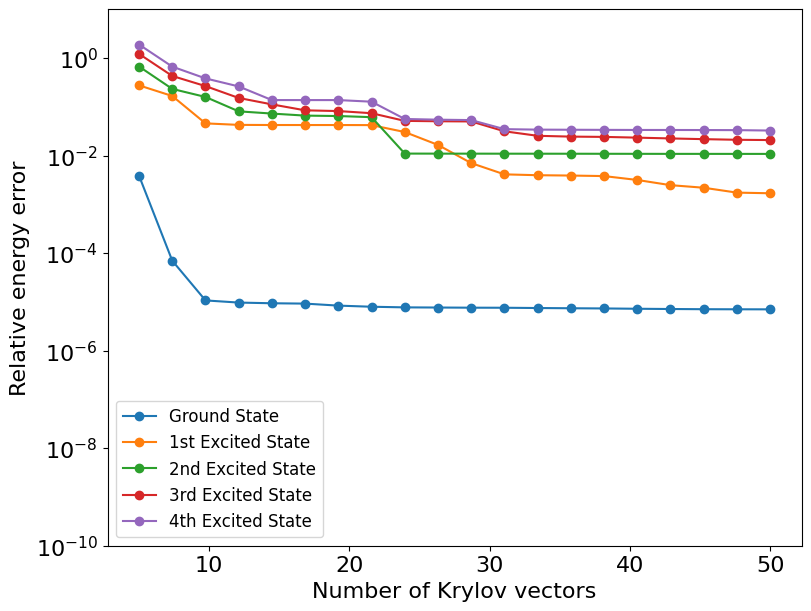

In [97]:
# Build the y-values for each of the five difference
y0 = [(e_fermi[i][0] - eigenvalues[0])/np.abs(eigenvalues[0]) for i in range(20)]
y1 = [(e_fermi[i][1] - eigenvalues[1])/np.abs(eigenvalues[1]) for i in range(20)]
y2 = [(e_fermi[i][2] - eigenvalues[5])/np.abs(eigenvalues[5]) for i in range(20)]
y3 = [(e_fermi[i][3] - eigenvalues[7])/np.abs(eigenvalues[7]) for i in range(20)]
y4 = [(e_fermi[i][4] - eigenvalues[12])/np.abs(eigenvalues[12]) for i in range(20)]


plt.figure(figsize=(8, 6),dpi = 100,constrained_layout=True)
N_list = np.linspace(5, 50, 20)
# Plot each difference vs. xx
plt.plot(N_list, y0, 'o-', label="Ground State")
plt.plot(N_list, y1, 'o-', label="1st Excited State")
plt.plot(N_list, y2, 'o-', label="2nd Excited State")
plt.plot(N_list, y3, 'o-', label="3rd Excited State")
plt.plot(N_list, y4, 'o-', label="4th Excited State")
plt.ylim(1e-10, 1e1)

ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)



# Optional: force y-axis ticks at each 10^-x
yticks = [10**(-i) for i in range(0,11,2)]  # 10^0 to 10^-10
ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)

plt.yscale('log')

plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Relative energy error" , fontsize=16)
plt.legend(fontsize=12)
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\fermi_plain.pdf",bbox_inches='tight',
        pad_inches=0.05)
plt.show()


### ERL

In [63]:
N_Krylov = 30
max_bond_Krylov = 64
trunc_tol = 0
foldername = f"TRL_1"
H = H3
mpo_ref = H3
generate_krylov_space(N_Krylov, H3, HFS, max_bond_Krylov, trunc_tol, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov, foldername, mpo_ref)
W = get_W(N_Krylov, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
k = 1
e,v = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, 5, H)
e_rs = []
err_var_rs = []
fidelity_rs = []
e_rs.append(np.array(e))
v = v[:k]
N_Krylov_restart = 10
x_list = [30]
j = 0
num_restart = 30
max_restart_num = 150
count = 0
while count < max_restart_num:
    generate_restart_with_ritz(v, N_Krylov_restart, H, max_bond_Krylov, trunc_tol, foldername)
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov_restart, foldername, mpo_ref)
    W = get_W(N_Krylov_restart, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    # Note: solve_ritz_vecs requested 5 vectors, ensure this is intended
    e_ritz, v_ritz = solve_ritz_vecs(foldername, H_reduced, N_Krylov_restart, coeff, max_bond_Krylov, 5, mpo_ref)
    e_rs.append(np.array(e_ritz))
    x_list.append(x_list[-1]+9)
    v_test = v_ritz[k-1]
    err_temp = []
    fidelity_temp = []
    for i in range(l):
        v_test = v_ritz[i]
        temp1 = apply_operator(H, v_test)  
        temp2 = add_mps(temp1,v_test,-e_rs[-1][i])
        err_temp.append(vdot(temp2,temp2))
    err_var_rs.append(np.array(err_temp))

    for i in range(l):
        ritz_state = v_ritz[i].as_vector() 
        fidelity_temp.append(1-np.abs(np.dot(real_state[i],ritz_state))**2)
    fidelity_rs.append(np.array(fidelity_temp))
    if j == 30: 
        print("Now restart"+ str(k+1) + "Ritz vector(s)")
        k = k+1
        j = 0
        N_Krylov_restart = N_Krylov_restart + 1
    v = v_ritz[:k] 
    count += 1
    j += 1
   

    print("Now restart"+ str(count) + "times")

[1, 4, 16, 64, 64, 64, 16, 4, 1]
2
[1, 4, 16, 64, 64, 64, 16, 4, 1]
3
[1, 4, 16, 64, 64, 64, 16, 4, 1]
4
[1, 4, 16, 64, 64, 64, 16, 4, 1]
5
[1, 4, 16, 64, 64, 64, 16, 4, 1]
6
[1, 4, 16, 64, 64, 64, 16, 4, 1]
7
[1, 4, 16, 64, 64, 64, 16, 4, 1]
8
[1, 4, 16, 64, 64, 64, 16, 4, 1]
9
[1, 4, 16, 64, 64, 64, 16, 4, 1]
10
[1, 4, 16, 64, 64, 64, 16, 4, 1]
11
[1, 4, 16, 64, 64, 64, 16, 4, 1]
12
[1, 4, 16, 64, 64, 64, 16, 4, 1]
13
[1, 4, 16, 64, 64, 64, 16, 4, 1]
14
[1, 4, 16, 64, 64, 64, 16, 4, 1]
15
[1, 4, 16, 64, 64, 64, 16, 4, 1]
16
[1, 4, 16, 64, 64, 64, 16, 4, 1]
17
[1, 4, 16, 64, 64, 64, 16, 4, 1]
18
[1, 4, 16, 64, 64, 64, 16, 4, 1]
19
[1, 4, 16, 64, 64, 64, 16, 4, 1]
20
[1, 4, 16, 64, 64, 64, 16, 4, 1]
21
[1, 4, 16, 64, 64, 64, 16, 4, 1]
22
[1, 4, 16, 64, 64, 64, 16, 4, 1]
23
[1, 4, 16, 64, 64, 64, 16, 4, 1]
24
[1, 4, 16, 64, 64, 64, 16, 4, 1]
25
[1, 4, 16, 64, 64, 64, 16, 4, 1]
26
[1, 4, 16, 64, 64, 64, 16, 4, 1]
27
[1, 4, 16, 64, 64, 64, 16, 4, 1]
28
[1, 4, 16, 64, 64, 64, 16, 4, 1]
29


In [64]:
j = 0
count = 0
while count < 20:
    generate_restart_with_ritz(v, N_Krylov_restart, H, max_bond_Krylov, trunc_tol, foldername)
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov_restart, foldername, mpo_ref)
    W = get_W(N_Krylov_restart, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    # Note: solve_ritz_vecs requested 5 vectors, ensure this is intended
    e_ritz, v_ritz = solve_ritz_vecs(foldername, H_reduced, N_Krylov_restart, coeff, max_bond_Krylov, 5, mpo_ref)
    e_rs.append(np.array(e_ritz))
    x_list.append(x_list[-1]+9)
    v_test = v_ritz[k-1]
    err_temp = []
    fidelity_temp = []
    for i in range(l):
        v_test = v_ritz[i]
        temp1 = apply_operator(H, v_test)  
        temp2 = add_mps(temp1,v_test,-e_rs[-1][i])
        err_temp.append(vdot(temp2,temp2))
    err_var_rs.append(np.array(err_temp))

    for i in range(l):
        ritz_state = v_ritz[i].as_vector() 
        fidelity_temp.append(1-np.abs(np.dot(real_state[i],ritz_state))**2)
    fidelity_rs.append(np.array(fidelity_temp))
    if j == 30: 
        print("Now restart"+ str(k+1) + "Ritz vector(s)")
        k = k+1
        j = 0
        N_Krylov_restart = N_Krylov_restart + 1
    v = v_ritz[:k] 
    count += 1
    j += 1

6
[1, 4, 16, 64, 64, 64, 16, 4, 1]
7
[1, 4, 16, 64, 64, 64, 16, 4, 1]
8
[1, 4, 16, 64, 64, 64, 16, 4, 1]
9
[1, 4, 16, 64, 64, 64, 16, 4, 1]
10
[1, 4, 16, 64, 64, 64, 16, 4, 1]
11
[1, 4, 16, 64, 64, 64, 16, 4, 1]
12
[1, 4, 16, 64, 64, 64, 16, 4, 1]
13
[1, 4, 16, 64, 64, 64, 16, 4, 1]
6
[1, 4, 16, 64, 64, 64, 16, 4, 1]
7
[1, 4, 16, 64, 64, 64, 16, 4, 1]
8
[1, 4, 16, 64, 64, 64, 16, 4, 1]
9
[1, 4, 16, 64, 64, 64, 16, 4, 1]
10
[1, 4, 16, 64, 64, 64, 16, 4, 1]
11
[1, 4, 16, 64, 64, 64, 16, 4, 1]
12
[1, 4, 16, 64, 64, 64, 16, 4, 1]
13
[1, 4, 16, 64, 64, 64, 16, 4, 1]
6
[1, 4, 16, 64, 64, 64, 16, 4, 1]
7
[1, 4, 16, 64, 64, 64, 16, 4, 1]
8
[1, 4, 16, 64, 64, 64, 16, 4, 1]
9
[1, 4, 16, 64, 64, 64, 16, 4, 1]
10
[1, 4, 16, 64, 64, 64, 16, 4, 1]
11
[1, 4, 16, 64, 64, 64, 16, 4, 1]
12
[1, 4, 16, 64, 64, 64, 16, 4, 1]
13
[1, 4, 16, 64, 64, 64, 16, 4, 1]
6
[1, 4, 16, 64, 64, 64, 16, 4, 1]
7
[1, 4, 16, 64, 64, 64, 16, 4, 1]
8
[1, 4, 16, 64, 64, 64, 16, 4, 1]
9
[1, 4, 16, 64, 64, 64, 16, 4, 1]
10
[1, 4

KeyboardInterrupt: 

c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


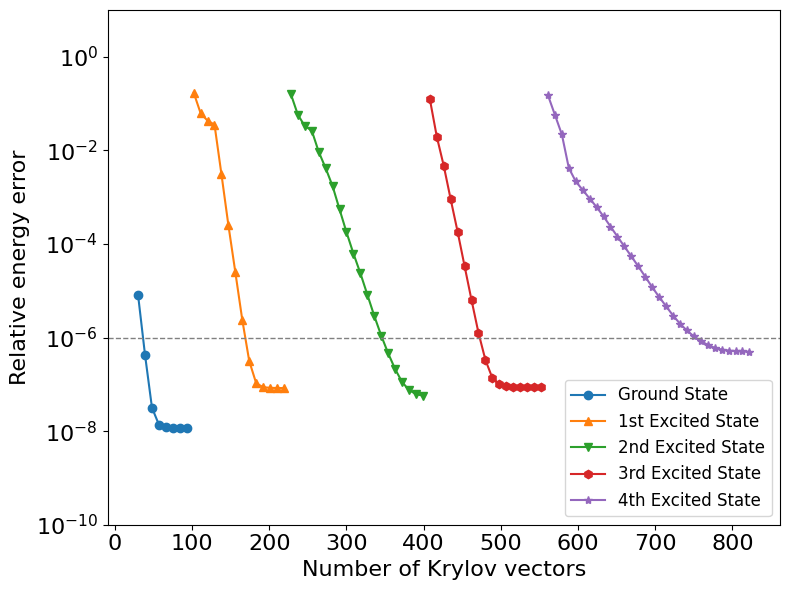

In [81]:
res_num = 30
from matplotlib.ticker import FuncFormatter
y0 = [(e_rs[i][0] - eigenvalues[0])/np.abs(eigenvalues[0]) for i in range(max_restart_num+1)]
y1 = [(e_rs[i][1] - eigenvalues[1])/np.abs(eigenvalues[1]) for i in range(max_restart_num+1)]
y2 = [(e_rs[i][2] - eigenvalues[5])/np.abs(eigenvalues[5]) for i in range(max_restart_num+1)]
y3 = [(e_rs[i][3] - eigenvalues[7])/np.abs(eigenvalues[7]) for i in range(max_restart_num+1)]
y4 = [(e_rs[i][4] - eigenvalues[12])/np.abs(eigenvalues[12]) for i in range(max_restart_num+1)]

plt.figure(figsize=(8, 6),dpi = 100)
# Plot each segment
plt.plot(x_list[0:8], y0[0:8], 'o-', label="Ground State")
plt.plot(x_list[8:22], y1[res_num+1:res_num+15], '^-', label="1st Excited State")
plt.plot(x_list[22:42], y2[2*res_num+1:2*res_num+21], 'v-', label="2nd Excited State")
plt.plot(x_list[42:59], y3[3*res_num+1:3*res_num+18], 'h-', label="3rd Excited State")
plt.plot(x_list[59:89], y4[4*res_num+1:4*res_num+31], '*-', label="4th Excited State")

# Log scale and axis formatting
plt.yscale('log')
plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Relative energy error", fontsize=16)
plt.ylim(1e-8, 1e1)

ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)

# Add horizontal line at 1e-7
plt.axhline(y=1e-6, color='gray', linestyle='--', linewidth=1)

# Optional: force y-axis ticks at each 10^-x
yticks = [10**(-i) for i in range(0,11,2)]  # 10^0 to 10^-10
plt.yticks(yticks)
formatter = FuncFormatter(lambda y, _: f"$10^{{{int(np.log10(y))}}}$")
ax.yaxis.set_major_formatter(formatter)

plt.legend(fontsize=12)

plt.tight_layout()

plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\fermi_rl.pdf", bbox_inches='tight',
        pad_inches=0.05)
plt.show()


In [ ]:
e_mrl_fermi = copy.deepcopy(e_band)
e_erl_fermi = copy.deepcopy(e_rs)

In [139]:
with open('e_mrl_fermi.pkl', 'wb') as f:
    pickle.dump(e_mrl_fermi, f)
with open('e_erl_fermi.pkl', 'wb') as f:
    pickle.dump(e_erl_fermi, f)

### TRL

In [23]:
N_Krylov = 30
max_bond_Krylov = 50
#max_bond_Krylov = 75
trunc_tol = 0
foldername = f"test_irlm"
generate_krylov_space(N_Krylov+1, H3, HFS, max_bond_Krylov, trunc_tol, foldername)
k = 10
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov, foldername, mpo_ref)
W = get_W(N_Krylov, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
e,v_ritz = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, N_Krylov, H3)
e_trl = [e[:4]]
v = v_ritz[:k]
filename = foldername + f"/Krylov_vec{N_Krylov}.pkl"
with open(filename, 'rb') as file:
    temp1 = pickle.load(file)
v.append(temp1)
max_restart_num = 10

for count in range(max_restart_num):
    generate_restart_with_ritz(v, N_Krylov+1, H3, max_bond_Krylov, trunc_tol, foldername)
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov, foldername, mpo_ref)
    W = get_W(N_Krylov, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    coeff = coeff[:N_Krylov,:N_Krylov]
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    e,v_ritz = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, k, H3)

    e_trl.append(e[:4])
    v = v_ritz[:k]
    with open(filename, 'rb') as file:
        temp1 = pickle.load(file)
    v.append(temp1)
    print("restart "+ str(count))
  

[1, 3, 3, 4, 3, 4, 3, 3, 1]
2
[1, 4, 11, 22, 27, 28, 14, 4, 1]
3
[1, 4, 16, 49, 50, 50, 16, 4, 1]
4
[1, 4, 16, 50, 50, 50, 16, 4, 1]
5
[1, 4, 16, 50, 50, 50, 16, 4, 1]
6
[1, 4, 16, 50, 50, 50, 16, 4, 1]
7
[1, 4, 16, 50, 50, 50, 16, 4, 1]
8
[1, 4, 16, 50, 50, 50, 16, 4, 1]
9
[1, 4, 16, 50, 50, 50, 16, 4, 1]
10
[1, 4, 16, 50, 50, 50, 16, 4, 1]
11
[1, 4, 16, 50, 50, 50, 16, 4, 1]
12
[1, 4, 16, 50, 50, 50, 16, 4, 1]
13
[1, 4, 16, 50, 50, 50, 16, 4, 1]
14
[1, 4, 16, 50, 50, 50, 16, 4, 1]
15
[1, 4, 16, 50, 50, 50, 16, 4, 1]
16
[1, 4, 16, 50, 50, 50, 16, 4, 1]
17
[1, 4, 16, 50, 50, 50, 16, 4, 1]
18
[1, 4, 16, 50, 50, 50, 16, 4, 1]
19
[1, 4, 16, 50, 50, 50, 16, 4, 1]
20
[1, 4, 16, 50, 50, 50, 16, 4, 1]
21
[1, 4, 16, 50, 50, 50, 16, 4, 1]
22
[1, 4, 16, 50, 50, 50, 16, 4, 1]
23
[1, 4, 16, 50, 50, 50, 16, 4, 1]
24
[1, 4, 16, 50, 50, 50, 16, 4, 1]
25
[1, 4, 16, 50, 50, 50, 16, 4, 1]
26
[1, 4, 16, 50, 50, 50, 16, 4, 1]
27
[1, 4, 16, 50, 50, 50, 16, 4, 1]
28
[1, 4, 16, 50, 50, 50, 16, 4, 1]
29
[1, 4

c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


12
[1, 4, 16, 50, 50, 50, 16, 4, 1]
13
[1, 4, 16, 50, 50, 50, 16, 4, 1]
14
[1, 4, 16, 50, 50, 50, 16, 4, 1]
15
[1, 4, 16, 50, 50, 50, 16, 4, 1]
16
[1, 4, 16, 50, 50, 50, 16, 4, 1]
17
[1, 4, 16, 50, 50, 50, 16, 4, 1]
18
[1, 4, 16, 50, 50, 50, 16, 4, 1]
19
[1, 4, 16, 50, 50, 50, 16, 4, 1]
20
[1, 4, 16, 50, 50, 50, 16, 4, 1]
21
[1, 4, 16, 50, 50, 50, 16, 4, 1]
22
[1, 4, 16, 50, 50, 50, 16, 4, 1]
23
[1, 4, 16, 50, 50, 50, 16, 4, 1]
24
[1, 4, 16, 50, 50, 50, 16, 4, 1]
25
[1, 4, 16, 50, 50, 50, 16, 4, 1]
26
[1, 4, 16, 50, 50, 50, 16, 4, 1]
27
[1, 4, 16, 50, 50, 50, 16, 4, 1]
28
[1, 4, 16, 50, 50, 50, 16, 4, 1]
29
[1, 4, 16, 50, 50, 50, 16, 4, 1]
30
[1, 4, 16, 50, 50, 50, 16, 4, 1]
restart 0
12
[1, 4, 16, 50, 50, 50, 16, 4, 1]
13
[1, 4, 16, 50, 50, 50, 16, 4, 1]
14
[1, 4, 16, 50, 50, 50, 16, 4, 1]
15
[1, 4, 16, 50, 50, 50, 16, 4, 1]
16
[1, 4, 16, 50, 50, 50, 16, 4, 1]
17
[1, 4, 16, 50, 50, 50, 16, 4, 1]
18
[1, 4, 16, 50, 50, 50, 16, 4, 1]
19
[1, 4, 16, 50, 50, 50, 16, 4, 1]
20
[1, 4, 16, 50, 

c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


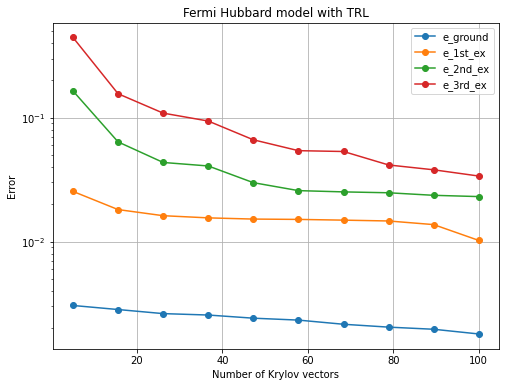

In [25]:
# Build the y-values for each of the five difference
y0 = [e_trl[i][0] - e_real[0] for i in range(10)]
y1 = [e_trl[i][1] - e_real[1] for i in range(10)]
y2 = [e_trl[i][2] - e_real[2] for i in range(10)]
y3 = [e_trl[i][3] - e_real[3] for i in range(10)]




plt.figure(figsize=(8, 6))
N_list = np.linspace(5, 100, 10)
# Plot each difference vs. xx
plt.plot(N_list, y0, 'o-', label="e_ground")
plt.plot(N_list, y1, 'o-', label="e_1st_ex")
plt.plot(N_list, y2, 'o-', label="e_2nd_ex")
plt.plot(N_list, y3, 'o-', label="e_3rd_ex")


plt.yscale('log')

plt.xlabel("Number of Krylov vectors")
plt.ylabel("Error")
plt.title("Fermi Hubbard model with TRL")
plt.legend()
plt.grid(True)
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\fermi_trl.pdf")
plt.show()


### BRL

In [82]:
N_Krylov = 30
max_bond_Krylov = 64
e_band = []
#HFS1 = generate_single_state(7, [3, 3, 3, 3, 3, 0, 0])
N_list = [0]
foldername = f"test_gs"
l = 5
trunc_tol = 10e-12
generate_krylov_space(N_Krylov, H3, HFS, max_bond_Krylov, trunc_tol, foldername)
N_use = 30
# C = coeff_canonical_orthogonalization(N_use, foldername)
# vector_list = generate_re_ortho_space_with_coeff(N_use, C, foldername)
#vector_list = generate_re_ortho_space(N_use, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, H3)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
e0,initial_block = solve_ritz_vecs(foldername, H_reduced, N_use, coeff, max_bond_Krylov, 5, H3)
initial_block = initial_block[:l]
e_band.append(np.array(e0))
err_var_fermi = []
fidelity_band_fermi = []
num_op = 6
N_Krylov = l * num_op 
num_restart = 25
lock_idx = 0   
real_state = [vecs_fermi.T[0],vecs_fermi.T[1],vecs_fermi.T[4],vecs_fermi.T[7],vecs_fermi.T[11]]         
for res in range(num_restart):
    generate_band_krylov(initial_block, N_Krylov, H3, max_bond_Krylov, trunc_tol, foldername,lock_idx)
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov+l, foldername, H3)
    W = get_W(N_Krylov+l, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    e,initial_block = solve_ritz_vecs(foldername, H_reduced, N_Krylov+l, coeff, max_bond_Krylov, 5, H3)
    initial_block = initial_block[:l]
    #if res>4:
    #    lock_idx = 2
    #if res>7:
    #    lock_idx = 4

    err_temp = []
    fidelity_temp = []
    
    for i in range(l):
        v_test = initial_block[i]
        temp1 = apply_operator(H3, v_test)  
        temp2 = add_mps(temp1,v_test,-e_band[-1][i])
        err_temp.append(vdot(temp2,temp2))
    err_var_fermi.append(np.array(err_temp))
    print(err_var_fermi[-1])


    for i in range(l):
        ritz_state = initial_block[i].as_vector() 
        fidelity_temp.append(1-np.abs(np.dot(real_state[i],ritz_state))**2)
    fidelity_band_fermi.append(np.array(fidelity_temp))

    
    e_band.append(np.array(e))
    N_Krylov = (l)*num_op

    print(f"restart {res} completed")

[1, 4, 16, 64, 64, 64, 16, 4, 1]
2
[1, 4, 16, 64, 64, 64, 16, 4, 1]
3
[1, 4, 16, 64, 64, 64, 16, 4, 1]
4
[1, 4, 16, 64, 64, 64, 16, 4, 1]
5
[1, 4, 16, 64, 64, 64, 16, 4, 1]
6
[1, 4, 16, 64, 64, 64, 16, 4, 1]
7
[1, 4, 16, 64, 64, 64, 16, 4, 1]
8
[1, 4, 16, 64, 64, 64, 16, 4, 1]
9
[1, 4, 16, 64, 64, 64, 16, 4, 1]
10
[1, 4, 16, 64, 64, 64, 16, 4, 1]
11
[1, 4, 16, 64, 64, 64, 16, 4, 1]
12
[1, 4, 16, 64, 64, 64, 16, 4, 1]
13
[1, 4, 16, 64, 64, 64, 16, 4, 1]
14
[1, 4, 16, 64, 64, 64, 16, 4, 1]
15
[1, 4, 16, 64, 64, 64, 16, 4, 1]
16
[1, 4, 16, 64, 64, 64, 16, 4, 1]
17
[1, 4, 16, 64, 64, 64, 16, 4, 1]
18
[1, 4, 16, 64, 64, 64, 16, 4, 1]
19
[1, 4, 16, 64, 64, 64, 16, 4, 1]
20
[1, 4, 16, 64, 64, 64, 16, 4, 1]
21
[1, 4, 16, 64, 64, 64, 16, 4, 1]
22
[1, 4, 16, 64, 64, 64, 16, 4, 1]
23
[1, 4, 16, 64, 64, 64, 16, 4, 1]
24
[1, 4, 16, 64, 64, 64, 16, 4, 1]
25
[1, 4, 16, 64, 64, 64, 16, 4, 1]
26
[1, 4, 16, 64, 64, 64, 16, 4, 1]
27
[1, 4, 16, 64, 64, 64, 16, 4, 1]
28
[1, 4, 16, 64, 64, 64, 16, 4, 1]
29


c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


5
[1, 4, 16, 64, 64, 64, 16, 4, 1]
6
[1, 4, 16, 64, 64, 64, 16, 4, 1]
7
[1, 4, 16, 64, 64, 64, 16, 4, 1]
8
[1, 4, 16, 64, 64, 64, 16, 4, 1]
9
[1, 4, 16, 64, 64, 64, 16, 4, 1]
10
[1, 4, 16, 64, 64, 64, 16, 4, 1]
11
[1, 4, 16, 64, 64, 64, 16, 4, 1]
12
[1, 4, 16, 64, 64, 64, 16, 4, 1]
13
[1, 4, 16, 64, 64, 64, 16, 4, 1]
14
[1, 4, 16, 64, 64, 64, 16, 4, 1]
15
[1, 4, 16, 64, 64, 64, 16, 4, 1]
16
[1, 4, 16, 64, 64, 64, 16, 4, 1]
17
[1, 4, 16, 64, 64, 64, 16, 4, 1]
18
[1, 4, 16, 64, 64, 64, 16, 4, 1]
19
[1, 4, 16, 64, 64, 64, 16, 4, 1]
20
[1, 4, 16, 64, 64, 64, 16, 4, 1]
21
[1, 4, 16, 64, 64, 64, 16, 4, 1]
22
[1, 4, 16, 64, 64, 64, 16, 4, 1]
23
[1, 4, 16, 64, 64, 64, 16, 4, 1]
24
[1, 4, 16, 64, 64, 64, 16, 4, 1]
25
[1, 4, 16, 64, 64, 64, 16, 4, 1]
26
[1, 4, 16, 64, 64, 64, 16, 4, 1]
27
[1, 4, 16, 64, 64, 64, 16, 4, 1]
28
[1, 4, 16, 64, 64, 64, 16, 4, 1]
29
[1, 4, 16, 64, 64, 64, 16, 4, 1]
30
[1, 4, 16, 64, 64, 64, 16, 4, 1]
31
[1, 4, 16, 64, 64, 64, 16, 4, 1]
32
[1, 4, 16, 64, 64, 64, 16, 4, 

KeyboardInterrupt: 

In [87]:
initial_block = copy.deepcopy(initial_block[:5])
for res in range(2):
    generate_band_krylov(initial_block, N_Krylov, H3, max_bond_Krylov, trunc_tol, foldername,lock_idx)
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov+l, foldername, H3)
    W = get_W(N_Krylov+l, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    e,initial_block = solve_ritz_vecs(foldername, H_reduced, N_Krylov+l, coeff, max_bond_Krylov, 5, H3)
    initial_block = initial_block[:l]
    #if res>4:
    #    lock_idx = 2
    #if res>7:
    #    lock_idx = 4

    err_temp = []
    fidelity_temp = []
    
    for i in range(l):
        v_test = initial_block[i]
        temp1 = apply_operator(H3, v_test)  
        temp2 = add_mps(temp1,v_test,-e_band[-1][i])
        err_temp.append(vdot(temp2,temp2))
    err_var_fermi.append(np.array(err_temp))
    print(err_var_fermi[-1])


    for i in range(l):
        ritz_state = initial_block[i].as_vector() 
        fidelity_temp.append(1-np.abs(np.dot(real_state[i],ritz_state))**2)
    fidelity_band_fermi.append(np.array(fidelity_temp))

    
    e_band.append(np.array(e))
    N_Krylov = (l)*num_op

    print(f"restart {res} completed")

5
[1, 4, 16, 64, 64, 64, 16, 4, 1]
6
[1, 4, 16, 64, 64, 64, 16, 4, 1]
7
[1, 4, 16, 64, 64, 64, 16, 4, 1]
8
[1, 4, 16, 64, 64, 64, 16, 4, 1]
9
[1, 4, 16, 64, 64, 64, 16, 4, 1]
10
[1, 4, 16, 64, 64, 64, 16, 4, 1]
11
[1, 4, 16, 64, 64, 64, 16, 4, 1]
12
[1, 4, 16, 64, 64, 64, 16, 4, 1]
13
[1, 4, 16, 64, 64, 64, 16, 4, 1]
14
[1, 4, 16, 64, 64, 64, 16, 4, 1]
15
[1, 4, 16, 64, 64, 64, 16, 4, 1]
16
[1, 4, 16, 64, 64, 64, 16, 4, 1]
17
[1, 4, 16, 64, 64, 64, 16, 4, 1]
18
[1, 4, 16, 64, 64, 64, 16, 4, 1]
19
[1, 4, 16, 64, 64, 64, 16, 4, 1]
20
[1, 4, 16, 64, 64, 64, 16, 4, 1]
21
[1, 4, 16, 64, 64, 64, 16, 4, 1]
22
[1, 4, 16, 64, 64, 64, 16, 4, 1]
23
[1, 4, 16, 64, 64, 64, 16, 4, 1]
24
[1, 4, 16, 64, 64, 64, 16, 4, 1]
25
[1, 4, 16, 64, 64, 64, 16, 4, 1]
26
[1, 4, 16, 64, 64, 64, 16, 4, 1]
27
[1, 4, 16, 64, 64, 64, 16, 4, 1]
28
[1, 4, 16, 64, 64, 64, 16, 4, 1]
29
[1, 4, 16, 64, 64, 64, 16, 4, 1]
30
[1, 4, 16, 64, 64, 64, 16, 4, 1]
31
[1, 4, 16, 64, 64, 64, 16, 4, 1]
32
[1, 4, 16, 64, 64, 64, 16, 4, 

c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


[0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
restart 0 completed
5
[1, 4, 16, 64, 64, 64, 16, 4, 1]
6
[1, 4, 16, 64, 64, 64, 16, 4, 1]
7
[1, 4, 16, 64, 64, 64, 16, 4, 1]
8
[1, 4, 16, 64, 64, 64, 16, 4, 1]
9
[1, 4, 16, 64, 64, 64, 16, 4, 1]
10
[1, 4, 16, 64, 64, 64, 16, 4, 1]
11
[1, 4, 16, 64, 64, 64, 16, 4, 1]
12
[1, 4, 16, 64, 64, 64, 16, 4, 1]
13
[1, 4, 16, 64, 64, 64, 16, 4, 1]
14
[1, 4, 16, 64, 64, 64, 16, 4, 1]
15
[1, 4, 16, 64, 64, 64, 16, 4, 1]
16
[1, 4, 16, 64, 64, 64, 16, 4, 1]
17
[1, 4, 16, 64, 64, 64, 16, 4, 1]
18
[1, 4, 16, 64, 64, 64, 16, 4, 1]
19
[1, 4, 16, 64, 64, 64, 16, 4, 1]
20
[1, 4, 16, 64, 64, 64, 16, 4, 1]
21
[1, 4, 16, 64, 64, 64, 16, 4, 1]
22
[1, 4, 16, 64, 64, 64, 16, 4, 1]
23
[1, 4, 16, 64, 64, 64, 16, 4, 1]
24
[1, 4, 16, 64, 64, 64, 16, 4, 1]
25
[1, 4, 16, 64, 64, 64, 16, 4, 1]
26
[1, 4, 16, 64, 64, 64, 16, 4, 1]
27
[1, 4, 16, 64, 64, 64, 16, 4, 1]
28
[1, 4, 16, 64, 64, 64, 16, 4, 1]
29
[1, 4, 16, 64, 64, 64, 16, 4, 1]
30
[1, 4, 16, 64, 64, 64, 16, 4, 1]
31
[1, 4, 16

In [88]:
e_band[-1]

array([-12.2358+0.j, -11.9165+0.j, -11.4213+0.j, -11.2291+0.j,
       -11.1753+0.j])

In [84]:
eigenvalues

array([-12.2358, -11.9165, -11.9165, -11.9165, -11.5402, -11.5402,
       -11.5402, -11.4213, -11.2506, -11.2506, -11.2506, -11.2506,
       -11.2291, -11.2291, -11.2291, -11.1753, -11.1753, -11.1753,
       -11.0927, -11.0242])

c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
c:\Users\Zhangyu\anaconda3\lib\site-packages\numpy\ma\core.py:3413: ComplexWarning: Casting complex values to real discards the imaginary part
  _data[indx] = dval
C:\Users\Zhangyu\AppData\Local\Temp/ipykernel_5616/161815449.py:55: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


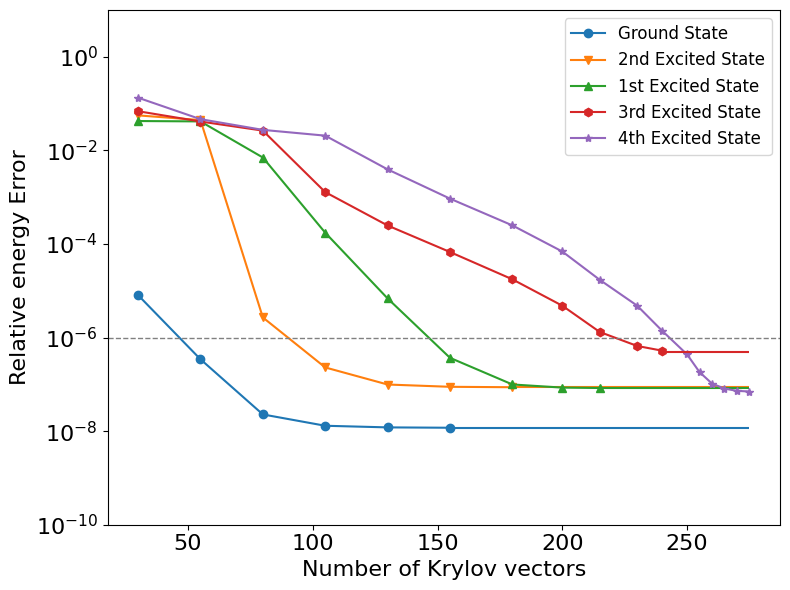

In [98]:
steps  = [25, 20, 15, 10,  5]
counts = [ 6,  1,  2,  2,  6]

xx_segments = []
start = 30

for step, count in zip(steps, counts):
    end = start + step*(count-1)
    xx_seg = np.linspace(start, end, count)
    xx_segments.append(xx_seg)
    # next segment starts one full step past this segment’s end
    start = end + step

# concatenate into your full 16-point array
xx = np.concatenate(xx_segments)

y0 = [(e_band[i][0] - eigenvalues[0])/np.abs(eigenvalues[0]) for i in range(17)]
y1 = [(e_band[i][1] - eigenvalues[1])/np.abs(eigenvalues[1]) for i in range(17)]
y2 = [(e_band[i][2] - eigenvalues[7])/np.abs(eigenvalues[7]) for i in range(17)]
y3 = [(e_band[i][3] - eigenvalues[12])/np.abs(eigenvalues[12]) for i in range(17)]
y4 = [(e_band[i][4] - eigenvalues[-3])/np.abs(eigenvalues[-3]) for i in range(17)]
plt.figure(figsize=(8, 6),dpi=100, constrained_layout=True)
x_max = xx[-1]
# original plots
plt.plot(xx[:6],  y0[:6],  'o-', label="Ground State")
plt.plot(xx[:7],  y2[:7],  'v-', label="2nd Excited State")
plt.hlines(y2[7],  xx[6],  x_max, colors='C1', linestyles='-')
plt.plot(xx[:9],  y1[:9],  '^-', label="1st Excited State")
plt.hlines(y1[9],  xx[8],  x_max, colors='C2', linestyles='-')
plt.plot(xx[:11], y3[:11], 'h-', label="3rd Excited State")
plt.plot(xx[:17],  y4[:17],  '*-', label="4th Excited State")


# extend each to the full x-axis
plt.hlines(y0[6],  xx[5],  x_max, colors='C0', linestyles='-')


plt.hlines(y3[11], xx[10], x_max, colors='C3', linestyles='-')

# rest of your formatting...
plt.yscale('log')
plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Relative energy Error", fontsize=16)
plt.ylim(1e-9, 1e1)
plt.axhline(1e-6, color='gray', linestyle='--', linewidth=1)

ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)
yticks = [10**(-i) for i in range(0, 11, 2)]
plt.yticks(yticks)
formatter = FuncFormatter(lambda y, _: f"$10^{{{int(np.log10(y))}}}$")
ax.yaxis.set_major_formatter(formatter)

plt.legend(fontsize = 12)
plt.tight_layout()
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\fermi_mrl.pdf", bbox_inches='tight',
        pad_inches=0.05)
plt.show()

c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
c:\Users\Zhangyu\anaconda3\lib\site-packages\numpy\ma\core.py:3413: ComplexWarning: Casting complex values to real discards the imaginary part
  _data[indx] = dval


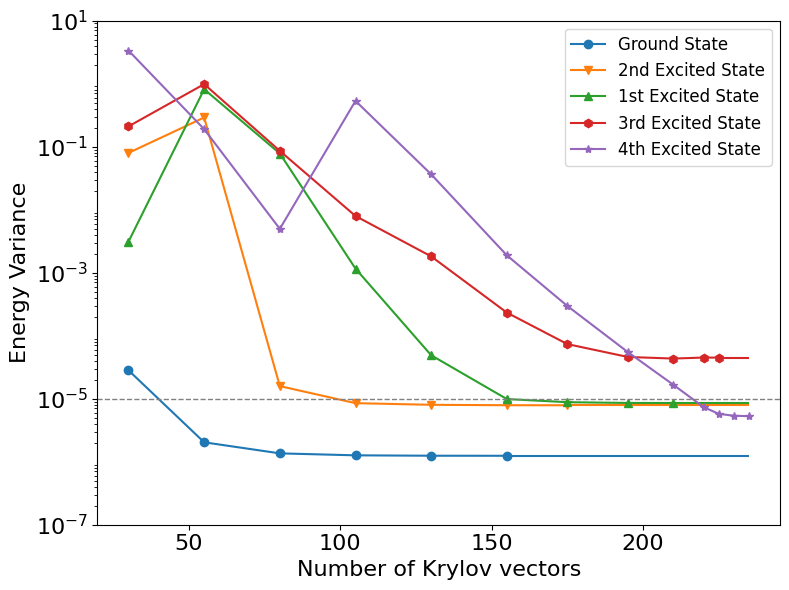

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# your xx‐generation
steps = [25, 20, 15, 10, 5]
counts = [5, 2, 1, 1, 4]

xx_segments = []
start = 30
for step, count in zip(steps, counts):
    end = start + step*(count-1)
    xx_seg = np.linspace(start, end, count)
    xx_segments.append(xx_seg)
    # next segment starts one full step past this segment’s end
    start = end + step
xx = np.concatenate(xx_segments)
x_max = xx[-1]
# your y‐data
y0 = [err_var_fermi[i][0] for i in range(13)]
y1 = [err_var_fermi[i][1] for i in range(13)]
y2 = [err_var_fermi[i][2] for i in range(13)]
y3 = [err_var_fermi[i][3] for i in range(13)]
y4 = [err_var_fermi[i][4] for i in range(13)]

plt.figure(figsize=(8, 6),dpi=100,constrained_layout=True)
x_max = xx[-1]
# original plots
plt.plot(xx[:6],  y0[:6],  'o-', label="Ground State")
plt.plot(xx[:7],  y2[:7],  'v-', label="2nd Excited State")
plt.hlines(y2[7],  xx[6],  x_max, colors='C1', linestyles='-')
plt.plot(xx[:9],  y1[:9],  '^-', label="1st Excited State")
plt.hlines(y1[9],  xx[8],  x_max, colors='C2', linestyles='-')
plt.plot(xx[:11], y3[:11], 'h-', label="3rd Excited State")
plt.plot(xx[:15],  y4[:15],  '*-', label="4th Excited State")


# extend each to the full x-axis
plt.hlines(y0[6],  xx[5],  x_max, colors='C0', linestyles='-')


plt.hlines(y3[11], xx[10], x_max, colors='C3', linestyles='-')

# rest of your formatting...
plt.yscale('log')
plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Energy Variance", fontsize=16)
plt.ylim(1e-7, 1e1)
plt.axhline(1e-5, color='gray', linestyle='--', linewidth=1)

ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)
yticks = [10**(-i) for i in range(-1, 9, 2)]
plt.yticks(yticks)
formatter = FuncFormatter(lambda y, _: f"$10^{{{int(np.log10(y))}}}$")
ax.yaxis.set_major_formatter(formatter)

plt.legend(fontsize=12)
plt.tight_layout()
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\fermi_variance.pdf", bbox_inches='tight',
        pad_inches=0.05)
plt.show()


###    molecular_hamiltonian

In [30]:
#load integrals
with h5py.File("data_water/eri_water.hdf5", "r") as f:
#with h5py.File("/work_fast/ge49cag/pytenet_yu/water/eri_water.hdf5", "r") as f:
    eri = f["eri"][()]
    hkin = f["hkin"][()]
    hnuc = f["hnuc"][()]

#print(np.linalg.norm(eri))
#print(eri.shape)

no = eri.shape[0]
MV = eri.reshape(no*no,no*no)

u = np.load("data_water/x.npy")
#u = np.load("/work_fast/ge49cag/pytenet_yu/water/x.npy")
X_mo = u.transpose(1,0)
g_thc, Z_mo = eval_func(u,eri,hkin,hnuc,)
h1 = hnuc+hkin
nmo = X_mo.shape[1]
L = X_mo.shape[1]
g_thc = g_thc.reshape(nmo, nmo, nmo, nmo)
r_thc = X_mo.shape[0]
g_phy =  eri.transpose(0, 2, 1, 3)
#mpo_ref = ptn.hamiltonian.molecular_hamiltonian_mpo(h1_spin, g_spin_phy)
mpo_ref = ptn.hamiltonian.spin_molecular_hamiltonian_mpo(h1, g_phy)

7
(7, 28)
(28, 28)
rl errV: 2.5804847549658373e-12
abs errV: 1.874062745450254e-11
errt: 2.6607105502789027e-13
errh: 2.300673316482739e-13
errht: 2.100739977085022e-13


In [31]:
HFS1 = ptn.generate_single_state(7, [3, 3, 3, 3, 3, 0, 0])
HFS2 = ptn.generate_single_state(7, [3, 3, 3, 3, 1, 2, 0])



HFS = add_mps(HFS1, HFS2)
HFS.orthonormalize('right')

np.float64(1.4142135623730951)

### Plain Lanczos

In [32]:
N_Krylov = 100
psi_original = copy.deepcopy(HFS)
max_bond_Krylov = 27
#max_bond_Krylov = 75
trunc_tol = 0
foldername = f"test"
e_mo = [] 
H = mpo_ref

N_list = []
foldername = f"test"
generate_krylov_space(N_Krylov, H, HFS, max_bond_Krylov, trunc_tol, foldername) 

N_use = 100
# C = coeff_canonical_orthogonalization(N_use, foldername)
# vector_list = generate_re_ortho_space_with_coeff(N_use, C, foldername)
#vector_list = generate_re_ortho_space(N_use, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, H)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
for N in range(5, N_use+1, 5):
    N_list.append(N)
    H_part = H_reduced[:N, :N]
    e_rotate, v_rotate = np.linalg.eigh(H_part)
    e_mo.append(e_rotate)

[1, 4, 11, 19, 21, 14, 4, 1]
2
[1, 4, 16, 27, 27, 16, 4, 1]
3
[1, 4, 16, 27, 27, 16, 4, 1]
4
[1, 4, 16, 27, 27, 16, 4, 1]
5
[1, 4, 16, 27, 27, 16, 4, 1]
6
[1, 4, 16, 27, 27, 16, 4, 1]
7
[1, 4, 16, 27, 27, 16, 4, 1]
8
[1, 4, 16, 27, 27, 16, 4, 1]
9
[1, 4, 16, 27, 27, 16, 4, 1]
10
[1, 4, 16, 27, 27, 16, 4, 1]
11
[1, 4, 16, 27, 27, 16, 4, 1]
12
[1, 4, 16, 27, 27, 16, 4, 1]
13
[1, 4, 16, 27, 27, 16, 4, 1]
14
[1, 4, 16, 27, 27, 16, 4, 1]
15
[1, 4, 16, 27, 27, 16, 4, 1]
16
[1, 4, 16, 27, 27, 16, 4, 1]
17
[1, 4, 16, 27, 27, 16, 4, 1]
18
[1, 4, 16, 27, 27, 16, 4, 1]
19
[1, 4, 16, 27, 27, 16, 4, 1]
20
[1, 4, 16, 27, 27, 16, 4, 1]
21
[1, 4, 16, 27, 27, 16, 4, 1]
22
[1, 4, 16, 27, 27, 16, 4, 1]
23
[1, 4, 16, 27, 27, 16, 4, 1]
24
[1, 4, 16, 27, 27, 16, 4, 1]
25
[1, 4, 16, 27, 27, 16, 4, 1]
26
[1, 4, 16, 27, 27, 16, 4, 1]
27
[1, 4, 16, 27, 27, 16, 4, 1]
28
[1, 4, 16, 27, 27, 16, 4, 1]
29
[1, 4, 16, 27, 27, 16, 4, 1]
30
[1, 4, 16, 27, 27, 16, 4, 1]
31
[1, 4, 16, 27, 27, 16, 4, 1]
32
[1, 4, 16, 27, 2

c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


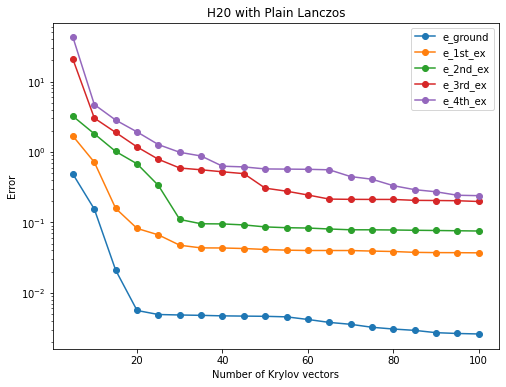

In [33]:
e_ground = -84.92262983120877
e_1st_ex = -84.52780562388604
e_2nd_ex = -84.46820215626565
e_3rd_ex = -84.42486181064207
e_4th_ex = -84.42379006099287

# Build the y-values for each of the five difference
y0 = [e_mo[i][0] - e_ground for i in range(20)]
y1 = [e_mo[i][1] - e_1st_ex for i in range(20)]
y2 = [e_mo[i][2] - e_2nd_ex for i in range(20)]
y3 = [e_mo[i][3] - e_3rd_ex for i in range(20)]
y4 = [e_mo[i][4] - e_4th_ex for i in range(20)]


plt.figure(figsize=(8, 6))
N_list = np.linspace(5, 100, 20)
# Plot each difference vs. xx
plt.plot(N_list, y0, 'o-', label="e_ground")
plt.plot(N_list, y1, 'o-', label="e_1st_ex")
plt.plot(N_list, y2, 'o-', label="e_2nd_ex")
plt.plot(N_list, y3, 'o-', label="e_3rd_ex")
plt.plot(N_list, y4, 'o-', label="e_4th_ex")


plt.yscale('log')

plt.xlabel("Number of Krylov vectors")
plt.ylabel("Error")
plt.title("H20 with Plain Lanczos")
plt.legend()
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\h20_plain.pdf")
plt.show()


### BRL

In [ ]:
N_Krylov = 50
max_bond_Krylov = 20
e_band = []
#HFS1 = generate_single_state(7, [3, 3, 3, 3, 3, 0, 0])
N_list = [0]
foldername = f"test_gs"
l = 4
trunc_tol = 0
lock_idx = 0
initial_block = [HFS_bose1,HFS_bose2,HFS_bose3,HFS_bose4,HFS_bose5]
N_use = 60+l
generate_band_krylov(initial_block, N_Krylov, H2, max_bond_Krylov, trunc_tol, foldername,0)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, H2)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
e0,initial_block = solve_ritz_vecs(foldername, H_reduced, N_use, coeff, max_bond_Krylov, 5, H2)
initial_block = initial_block[:l]
e_band.append(np.array(e0))

num_op = 10
N_Krylov = l * num_op 
num_restart = 20
lock_idx = 0    

for res in range(num_restart):
    generate_band_krylov(initial_block, N_Krylov, H, max_bond_Krylov, trunc_tol, foldername)
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_Krylov+l, foldername, H)
    W = get_W(N_Krylov+l, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    e,initial_block = solve_ritz_vecs(foldername, H_reduced, N_Krylov+l, coeff, max_bond_Krylov, 5, H)
    initial_block = initial_block[:l]
    e_band.append(np.array(e))
    print(f"restart {res} completed")

[1, 4, 7, 13, 15, 14, 4, 1]
2
[1, 4, 13, 26, 27, 16, 4, 1]
3
[1, 4, 16, 27, 27, 16, 4, 1]
4
[1, 4, 16, 27, 27, 16, 4, 1]
5
[1, 4, 16, 27, 27, 16, 4, 1]
6
[1, 4, 16, 27, 27, 16, 4, 1]
7
[1, 4, 16, 27, 27, 16, 4, 1]
8
[1, 4, 16, 27, 27, 16, 4, 1]
9
[1, 4, 16, 27, 27, 16, 4, 1]
10
[1, 4, 16, 27, 27, 16, 4, 1]
11
[1, 4, 16, 27, 27, 16, 4, 1]
12
[1, 4, 16, 27, 27, 16, 4, 1]
13
[1, 4, 16, 27, 27, 16, 4, 1]
14
[1, 4, 16, 27, 27, 16, 4, 1]
15
[1, 4, 16, 27, 27, 16, 4, 1]
16
[1, 4, 16, 27, 27, 16, 4, 1]
17
[1, 4, 16, 27, 27, 16, 4, 1]
18
[1, 4, 16, 27, 27, 16, 4, 1]
19
[1, 4, 16, 27, 27, 16, 4, 1]
20
[1, 4, 16, 27, 27, 16, 4, 1]
21
[1, 4, 16, 27, 27, 16, 4, 1]
22
[1, 4, 16, 27, 27, 16, 4, 1]
23
[1, 4, 16, 27, 27, 16, 4, 1]
24
[1, 4, 16, 27, 27, 16, 4, 1]
25
[1, 4, 16, 27, 27, 16, 4, 1]
26
[1, 4, 16, 27, 27, 16, 4, 1]
27
[1, 4, 16, 27, 27, 16, 4, 1]
28
[1, 4, 16, 27, 27, 16, 4, 1]
29
[1, 4, 16, 27, 27, 16, 4, 1]


c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


4
[1, 4, 16, 27, 27, 15, 4, 1]
5
[1, 4, 16, 27, 27, 16, 4, 1]
6
[1, 4, 16, 27, 27, 16, 4, 1]
7
[1, 4, 16, 27, 27, 16, 4, 1]
8
[1, 4, 16, 27, 27, 16, 4, 1]
9
[1, 4, 16, 27, 27, 16, 4, 1]
10
[1, 4, 16, 27, 27, 16, 4, 1]
11
[1, 4, 16, 27, 27, 16, 4, 1]
12
[1, 4, 16, 27, 27, 16, 4, 1]
13
[1, 4, 16, 27, 27, 16, 4, 1]
14
[1, 4, 16, 27, 27, 16, 4, 1]
15
[1, 4, 16, 27, 27, 16, 4, 1]
16
[1, 4, 16, 27, 27, 16, 4, 1]
17
[1, 4, 16, 27, 27, 16, 4, 1]
18
[1, 4, 16, 27, 27, 16, 4, 1]
19
[1, 4, 16, 27, 27, 16, 4, 1]
20
[1, 4, 16, 27, 27, 16, 4, 1]
21
[1, 4, 16, 27, 27, 16, 4, 1]
22
[1, 4, 16, 27, 27, 16, 4, 1]
23
[1, 4, 16, 27, 27, 16, 4, 1]
24
[1, 4, 16, 27, 27, 16, 4, 1]
25
[1, 4, 16, 27, 27, 16, 4, 1]
26
[1, 4, 16, 27, 27, 16, 4, 1]
27
[1, 4, 16, 27, 27, 16, 4, 1]
28
[1, 4, 16, 27, 27, 16, 4, 1]
29
[1, 4, 16, 27, 27, 16, 4, 1]
30
[1, 4, 16, 27, 27, 16, 4, 1]
31
[1, 4, 16, 27, 27, 16, 4, 1]
32
[1, 4, 16, 27, 27, 16, 4, 1]
33
[1, 4, 16, 27, 27, 16, 4, 1]
34
[1, 4, 16, 27, 27, 16, 4, 1]
35
[1, 4, 16, 

c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


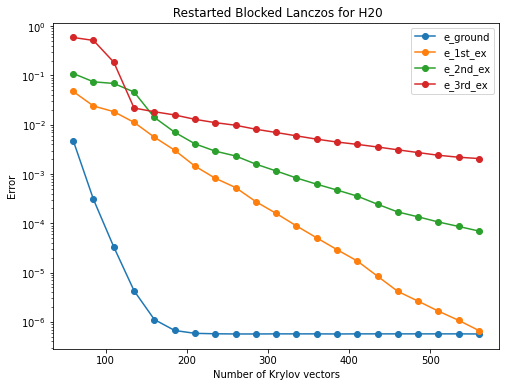

In [35]:
xx = np.linspace(60,60 + 20*25 , 21)

# Suppose err_band is a 2D list/array with shape (10, 5) or larger
# and you have defined your reference energies:
# e_ground, e_1st_ex, e_2nd_ex

# Build the y-values for each of the five differences
y0 = [e_band[i][0] - e_ground for i in range(21)]
y1 = [e_band[i][1] - e_1st_ex for i in range(21)]
y2 = [e_band[i][2] - e_2nd_ex for i in range(21)]
y3 = [e_band[i][3] - e_3rd_ex for i in range(21)]



plt.figure(figsize=(8, 6))

# Plot each difference vs. xx
plt.plot(xx, y0, 'o-', label="e_ground")
plt.plot(xx, y1, 'o-', label="e_1st_ex")
plt.plot(xx, y2, 'o-', label="e_2nd_ex")
plt.plot(xx, y3, 'o-', label="e_3rd_ex")


plt.yscale('log')

plt.xlabel("Number of Krylov vectors")
plt.ylabel("Error")
plt.title(" Restarted Blocked Lanczos for H20")
plt.legend()
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\h2o_brl.pdf")
plt.show()


### Fidelity Test

#### Heisenberg

In [72]:
### Here we have no truncation, for testing the eigenvalues
test_N_Krylov = 50

rng_master = np.random.default_rng(42)
#test_H = ptn.heisenberg_xxz_mpo(16,1,1,0)
test_H = ptn.bose_hubbard_mpo(d=2, L = 16, U=8, t=1, mu=1)
#test_H = ptn.ising_mpo(16, 1, 1, 0)
test_HFS = create_random_mps([1] * 17, 'right', rng=rng_master)
#test_HFS =  ptn.generate_single_state(8, [3, 3, 3, 3, 1, 2, 0,3])
test_HFS.zero_qnumbers()
test_H.zero_qnumbers()


test_foldername = f"test_poly"
generate_krylov_space(test_N_Krylov, test_H, test_HFS, 500, 0, test_foldername) 


#test_H_reduced_non_rotho = generate_reduced_H_non_ortho(50, test_foldername, test_H)
#test_W = get_W(50, test_foldername)
#test_coeff = get_S(test_W)
#test_coeff = np.array(test_coeff)
#tet_H_reduced = np.einsum('ik, kl, jl -> ij', test_coeff.conj(), test_H_reduced_non_rotho, test_coeff)


[1, 2, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 2, 1]
2
[1, 2, 4, 8, 16, 26, 26, 26, 26, 26, 26, 26, 16, 8, 4, 2, 1]
3
[1, 2, 4, 8, 16, 32, 64, 128, 135, 128, 64, 32, 16, 8, 4, 2, 1]
4
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 32, 64, 128, 256, 128, 64, 32, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 3

In [73]:
filename = test_foldername + f"/Krylov_vec{49}.pkl"
with open(filename, 'rb') as file:
    krylov1 = pickle.load(file)
bond = [10,20,30,40,50,60,70,80,90,100]
bond_test = []
for b in bond:
    v = copy.deepcopy(krylov1)
    v.orthonormalize('right')
    v.compress_direct_svd_left_max_bond(tol = 1e-14, max_bond=b)
    v.orthonormalize('right')
    bond_test.append(np.abs(vdot(v,krylov1))**2)

In [74]:
bond_test1 = []

for b in bond:
    generate_krylov_space(test_N_Krylov, test_H, test_HFS, b, 0, test_foldername) 
    filename = test_foldername + f"/Krylov_vec{49}.pkl"
    with open(filename, 'rb') as file:
        krylov2 = pickle.load(file)
    bond_test1.append(np.abs(vdot(krylov2,krylov1))**2)


[1, 2, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 2, 1]
2
[1, 2, 4, 8, 10, 10, 10, 10, 10, 10, 10, 10, 10, 8, 4, 2, 1]
3
[1, 2, 4, 8, 10, 10, 10, 10, 10, 10, 10, 10, 10, 8, 4, 2, 1]
4
[1, 2, 4, 8, 10, 10, 10, 10, 10, 10, 10, 10, 10, 8, 4, 2, 1]
5
[1, 2, 4, 8, 10, 10, 10, 10, 10, 10, 10, 10, 10, 8, 4, 2, 1]
6
[1, 2, 4, 8, 10, 10, 10, 10, 10, 10, 10, 10, 10, 8, 4, 2, 1]
7
[1, 2, 4, 8, 10, 10, 10, 10, 10, 10, 10, 10, 10, 8, 4, 2, 1]
8
[1, 2, 4, 8, 10, 10, 10, 10, 10, 10, 10, 10, 10, 8, 4, 2, 1]
9
[1, 2, 4, 8, 10, 10, 10, 10, 10, 10, 10, 10, 10, 8, 4, 2, 1]
10
[1, 2, 4, 8, 10, 10, 10, 10, 10, 10, 10, 10, 10, 8, 4, 2, 1]
11
[1, 2, 4, 8, 10, 10, 10, 10, 10, 10, 10, 10, 10, 8, 4, 2, 1]
12
[1, 2, 4, 8, 10, 10, 10, 10, 10, 10, 10, 10, 10, 8, 4, 2, 1]
13
[1, 2, 4, 8, 10, 10, 10, 10, 10, 10, 10, 10, 10, 8, 4, 2, 1]
14
[1, 2, 4, 8, 10, 10, 10, 10, 10, 10, 10, 10, 10, 8, 4, 2, 1]
15
[1, 2, 4, 8, 10, 10, 10, 10, 10, 10, 10, 10, 10, 8, 4, 2, 1]
16
[1, 2, 4, 8, 10, 10, 10, 10, 10, 10, 10, 10, 10, 8, 4, 2,

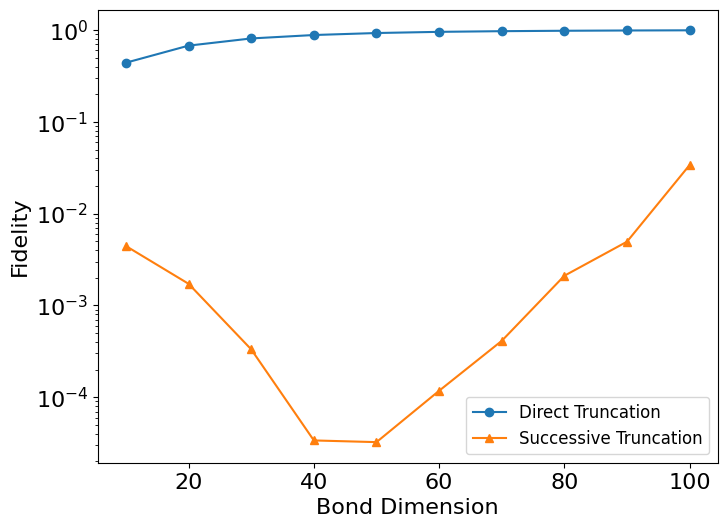

In [75]:
plt.figure(figsize=(8, 6),dpi=100)

plt.plot(bond, bond_test, 'o-', label="Direct Truncation")
plt.plot(bond, bond_test1, '^-', label="Successive Truncation")


plt.xlabel("Bond Dimension", fontsize=16)
plt.ylabel("Fidelity", fontsize=16)


ax = plt.gca()
ax.tick_params(axis='both', which='major', labelsize=16)

# Add horizontal grid line at 1e-7

# Set log scale
ax.set_yscale('log')


plt.legend(fontsize = 12)
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\bond_bose.pdf",bbox_inches='tight',
        pad_inches=0.05)
plt.show()


In [ ]:
e_list = []
N_list = range(5, N_use+1, 5)
for b in bond:
    generate_krylov_space(test_N_Krylov, test_H, test_HFS, b, 1e-12, test_foldername) 
    e = []
    N_use = 50
    H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, test_H)
    W = get_W(N_use, foldername)
    coeff = get_S(W)
    coeff = np.array(coeff)
    H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
    for N in range(5, N_use+1, 5):
        H_part = H_reduced[:N, :N]
        e_rotate, v_rotate = np.linalg.eigh(H_part)
        e.append(e_rotate)
    e_list.append(e)

In [32]:
N_Krylov = 30
foldername = f"test"
generate_krylov_space(N_Krylov, H, HFS2, 64, trunc_tol, foldername)  

N_use = 30
# C = coeff_canonical_orthogonalization(N_use, foldername)
# vector_list = generate_re_ortho_space_with_coeff(N_use, C, foldername)
#vector_list = generate_re_ortho_space(N_use, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, mpo_ref)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
e,v = solve_ritz_vecs(foldername, H_reduced, 30, coeff, max_bond_Krylov, 30, H)



[1, 2, 4, 5, 4, 5, 5, 4, 5, 5, 4, 2, 1]
2
[1, 2, 4, 8, 16, 32, 37, 31, 16, 8, 4, 2, 1]
3
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
4
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
17
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
18
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
19
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
20
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
21
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
22
[1, 2

In [49]:
N_use = 50
# C = coeff_canonical_orthogonalization(N_use, foldername)
# vector_list = generate_re_ortho_space_with_coeff(N_use, C, foldername)
#vector_list = generate_re_ortho_space(N_use, foldername)
#_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, mpo_ref)
W = get_W(N_use, test_foldername)
coeff = get_S(W)
coeff = np.array(coeff)



c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)


In [71]:
np.allclose(coeff **(-1/2), W, atol=1e-10)

C:\Users\Zhangyu\AppData\Local\Temp/ipykernel_30060/3236702797.py:1: RuntimeWarning: divide by zero encountered in power
  np.allclose(coeff **(-1/2), W, atol=1e-10)
C:\Users\Zhangyu\AppData\Local\Temp/ipykernel_30060/3236702797.py:1: RuntimeWarning: invalid value encountered in power
  np.allclose(coeff **(-1/2), W, atol=1e-10)


False

In [8]:
N_use = 30
# C = coeff_canonical_orthogonalization(N_use, foldername)
# vector_list = generate_re_ortho_space_with_coeff(N_use, C, foldername)
#vector_list = generate_re_ortho_space(N_use, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, H)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
e,v = solve_ritz_vecs(foldername, H_reduced, 30, coeff, max_bond_Krylov, 30, H)
foldername =f"restart_3"
generate_krylov_space(30, H, v[0], max_bond_Krylov, trunc_tol, foldername)



foldername = f"fidelity_test_4"
generate_krylov_space(30, H, v[0], 256, trunc_tol, foldername)


[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
2
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
3
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
4
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
17
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
18
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
19
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
20
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
21
[1, 2, 4, 8, 16, 30, 30, 30, 16, 8, 4, 2, 1]
22


c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Zhangyu\anaconda3\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


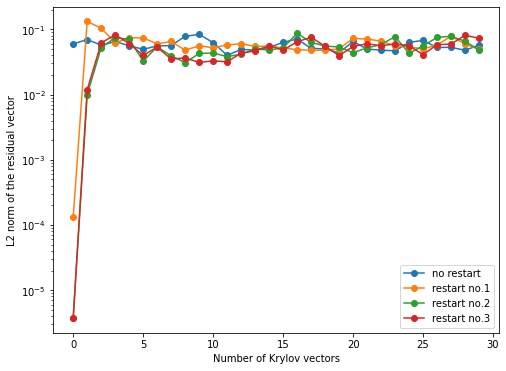

In [9]:
test_4 = []
test_5 = []
test_6 = []
test_7 = []
for i in range(30):
    foldername = f"test"
    filename = foldername + f"/Krylov_vec{i+29}.pkl"
    with open(filename, 'rb') as file:
        temp1 = pickle.load(file)
    Htemp1 = apply_operator(H,temp1)
    Htemp1.orthonormalize('right')
    Htemp2 = apply_operator_and_compress(H,temp1, trunc_tol, 30)
    Htemp2.orthonormalize('right')
    r = add_mps(Htemp1, Htemp2,-1)
    test_4.append( np.sqrt(vdot(r, r)) )


for i in range(30):
    foldername = f"restart_1"
    filename = foldername + f"/Krylov_vec{i}.pkl"
    with open(filename, 'rb') as file:
        temp1 = pickle.load(file)
    Htemp1 = apply_operator(H,temp1)
    Htemp1.orthonormalize('right')
    Htemp2 = apply_operator_and_compress(H,temp1, trunc_tol, 30)
    Htemp2.orthonormalize('right')
    r = add_mps(Htemp1, Htemp2,-1)
    test_5.append( np.sqrt(vdot(r, r)) )



for i in range(30):
    foldername = f"restart_2"
    filename = foldername + f"/Krylov_vec{i}.pkl"
    with open(filename, 'rb') as file:
        temp1 = pickle.load(file)
    Htemp1 = apply_operator(H,temp1)
    Htemp1.orthonormalize('right')
    Htemp2 = apply_operator_and_compress(H,temp1, trunc_tol, 30)
    Htemp2.orthonormalize('right')
    r = add_mps(Htemp1, Htemp2,-1)
    test_6.append( np.sqrt(vdot(r, r)) )

for i in range(30):
    foldername = f"restart_3"
    filename = foldername + f"/Krylov_vec{i}.pkl"
    with open(filename, 'rb') as file:
        temp1 = pickle.load(file)
    Htemp1 = apply_operator(H,temp1)
    Htemp1.orthonormalize('right')
    Htemp2 = apply_operator_and_compress(H,temp1, trunc_tol, 30)
    Htemp2.orthonormalize('right')
    r = add_mps(Htemp1, Htemp2,-1)
    test_7.append( np.sqrt(vdot(r, r)) )

plt.figure(figsize=(8, 6))
plt.plot(test_4, 'o-', label="no restart")
plt.plot(test_5, 'o-', label="restart no.1")
plt.plot(test_6, 'o-', label="restart no.2")
plt.plot(test_7, 'o-', label="restart no.3")
plt.yscale('log')
plt.xlabel("Number of Krylov vectors")
plt.ylabel("L2 norm of the residual vector")
plt.legend()




In [10]:
### Here we have no truncation, for testing the eigenvalues
N_Krylov = 50
H = mpo_ref
psi_original = v[0]
max_bond_Krylov = 200
#max_bond_Krylov = 75
trunc_tol = 0
foldername = f"restart_1"
generate_krylov_space(N_Krylov, H, psi_original, max_bond_Krylov, trunc_tol, foldername) 

N_use = 50
# C = coeff_canonical_orthogonalization(N_use, foldername)
# vector_list = generate_re_ortho_space_with_coeff(N_use, C, foldername)
#vector_list = generate_re_ortho_space(N_use, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, mpo_ref)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
e_real = np.linalg.eigvalsh(H_reduced)
e_real

[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
2
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
3
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
4
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
17
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
18
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
19
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
20
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
21
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
22


array([-5.1421, -4.8611, -4.5133, -4.4078, -4.1883, -4.0099, -3.7918,
       -3.7013, -3.4504, -3.3892, -3.2128, -3.1108, -3.0913, -2.8107,
       -2.6291, -2.5237, -2.336 , -2.0349, -1.8716, -1.7295, -1.505 ,
       -1.4089, -1.104 , -1.0103, -0.7791, -0.5928, -0.3935, -0.1839,
       -0.0362,  0.1428,  0.4112,  0.5026,  0.7064,  0.7676,  0.9953,
        1.138 ,  1.2413,  1.4471,  1.5025,  1.7501,  1.8312,  1.9697,
        2.1349,  2.2585,  2.3355,  2.4238,  2.4762,  2.5954,  2.6792,
        2.75  ])

In [21]:
max_bond_Krylov = 75
#max_bond_Krylov = 75
trunc_tol = 0
foldername = f"fidelity_test_2"
generate_krylov_space(N_Krylov, H, HFS2, max_bond_Krylov, trunc_tol, foldername)  
N_use = 50
# C = coeff_canonical_orthogonalization(N_use, foldername)
# vector_list = generate_re_ortho_space_with_coeff(N_use, C, foldername)
#vector_list = generate_re_ortho_space(N_use, foldername)
#H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, mpo_ref)
#W = get_W(N_use, foldername)
#coeff = get_S(W)
#coeff = np.array(coeff)
#H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
#e,v = solve_ritz_vecs(foldername, H_reduced, N_Krylov, coeff, max_bond_Krylov, N_Krylov, H)
#e

[1, 2, 4, 5, 4, 5, 5, 4, 5, 5, 4, 2, 1]
2
[1, 2, 4, 8, 16, 32, 37, 31, 16, 8, 4, 2, 1]
3
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
4
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
17
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
18
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
19
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
20
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
21
[1, 2, 4, 8, 16, 32, 64, 32, 16, 8, 4, 2, 1]
22
[1, 2

C:\Users\Zhangyu\AppData\Local\Temp/ipykernel_24144/3266938817.py:55: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=16)


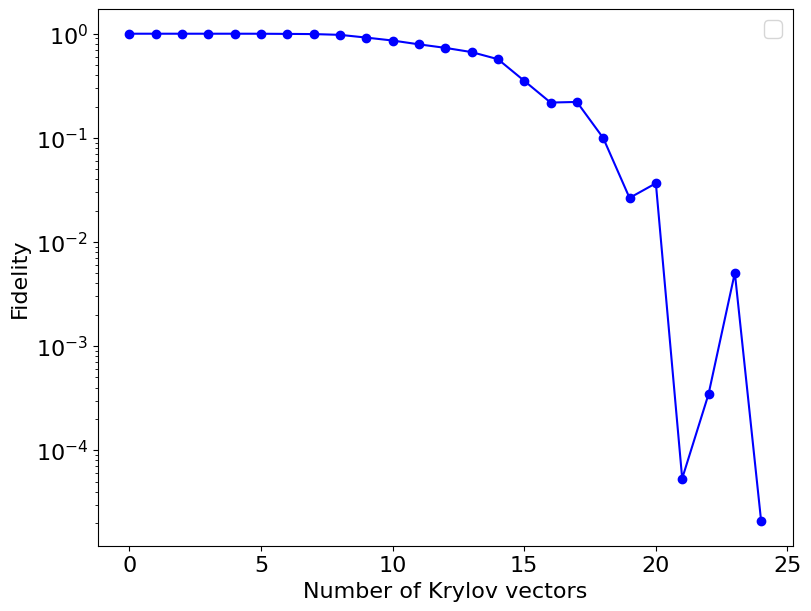

In [36]:
folder_containing_Krylov = f"test"
k_nontrunc = [ ]
k_trunc = [ ]
k_rs_nontrunc = [ ]
k_rs_trunc = []
for i in range(50):
    filename = folder_containing_Krylov + f"/Krylov_vec{i}.pkl"
    with open(filename, 'rb') as file:
        temp = pickle.load(file)
    k_nontrunc.append(temp)


folder_containing_Krylov = f"fidelity_test_1"

for i in range(50):
    filename = folder_containing_Krylov + f"/Krylov_vec{i}.pkl"
    with open(filename, 'rb') as file:
        temp = pickle.load(file)
    k_trunc.append(temp)


folder_containing_Krylov = f"restart_1"


for i in range(50):
    filename = folder_containing_Krylov + f"/Krylov_vec{i}.pkl"
    with open(filename, 'rb') as file:
        temp = pickle.load(file)
    k_rs_trunc.append(temp)


folder_containing_Krylov = f"fidelity_test_2"

for i in range(50):
    filename = folder_containing_Krylov + f"/Krylov_vec{i}.pkl"
    with open(filename, 'rb') as file:
        temp = pickle.load(file)
    k_rs_nontrunc.append(temp)


fidelity_trunc = []
fidelity_rs = []
for i in range(30):
    fidelity_trunc.append(np.abs(vdot(k_trunc[i], k_nontrunc[i])) **2 )
#    fidelity_rs.append(np.abs(vdot(k_rs_trunc[i], k_rs_nontrunc[i]))**2 )
plt.figure(figsize=(8, 6),dpi=100,constrained_layout=True)
plt.plot(fidelity_trunc[:25], 'o-', color='blue')
#plt.plot(fidelity_rs, 'o-', color='red')
plt.xlabel("Number of Krylov vectors", fontsize=16)
plt.ylabel("Fidelity", fontsize=16)
ax = plt.gca() # Get current axes
ax.tick_params(axis='both', which='major', labelsize=16) # Set size for major ticks on both axes


plt.legend(fontsize=16)  
plt.yscale('log')
plt.savefig(r"C:\Users\Zhangyu\Downloads\plot lanczos\fide.pdf", bbox_inches='tight',pad_inches=0.05)    
plt.show()


Power–basis coefficients:
[0.039  1.0426 4.4699 7.2459 5.8229 2.6284 0.7079 0.116  0.0113 0.0006
 0.    ]


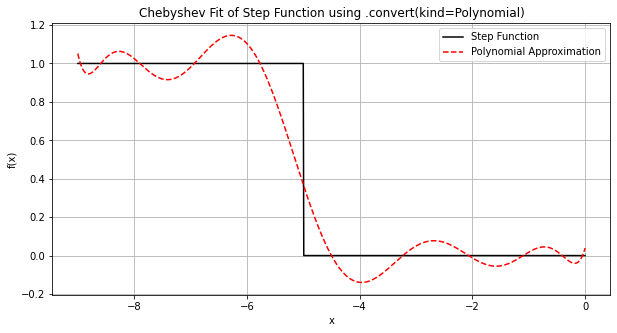

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial import Chebyshev, Polynomial

def plot_chebyshev_fit():
    def step_func(x):
        return np.where(x <= -5, 1, 0)
    
    # Define the interval and degree for the approximation.
    a, b = -9, 0
    N = 10  # Degree of the polynomial (adjust as needed)
    
    # Compute Chebyshev nodes in [-1, 1] and map them to [a, b].
    k = np.arange(N + 1)
    t_nodes = np.cos((2 * k + 1) * np.pi / (2 * (N + 1)))
    x_nodes = 0.5 * ((b - a) * t_nodes + (a + b))
    
    # Evaluate the step function at these nodes.
    y_nodes = step_func(x_nodes)
    
    # Fit a Chebyshev polynomial on [a, b].
    cheb_poly = Chebyshev.fit(x_nodes, y_nodes, N, domain=[a, b])
    
    # Convert the Chebyshev polynomial to a standard power–basis polynomial.
    poly_obj = cheb_poly.convert(kind=Polynomial)
    
    # (Optional) Print the power–basis coefficients.
    print("Power–basis coefficients:")
    print(poly_obj.coef)
    
    # Create a dense grid for plotting.
    x_dense = np.linspace(a, b, 1000)
    y_true = step_func(x_dense)
    y_fit = poly_obj(x_dense)
    
    # Plot the step function and its Chebyshev (power–basis) approximation.
    plt.figure(figsize=(10, 5))
    plt.plot(x_dense, y_true, 'k-', label="Step Function")
    plt.plot(x_dense, y_fit, 'r--', label="Polynomial Approximation")
    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.title('Chebyshev Fit of Step Function using .convert(kind=Polynomial)')
    plt.legend()
    plt.grid(True)
    plt.show()
    return poly_obj.coef

# Call the function to plot the approximation.
coeff_fit = plot_chebyshev_fit()



Full spectral domain for filter: [-5.7635, 0.0000]
Target cutoff energy (max of lowest eigs): -4.8286

Chebyshev Coefficients (Degree 6):
[ 0.295  -0.5116  0.3177 -0.0884 -0.0766  0.1306 -0.0766]
Number of coefficients: 7


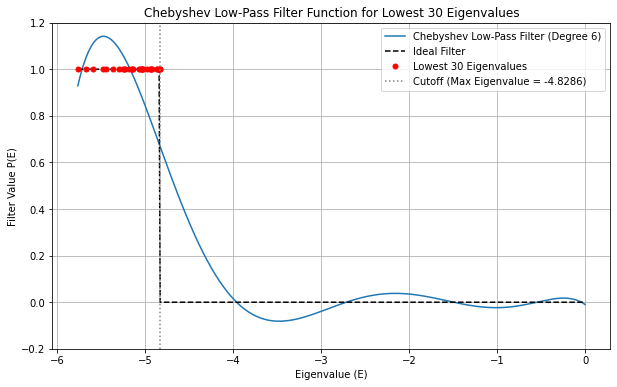


Filter weights evaluated at the 30 lowest eigenvalues (should be close to 1):
[0.6686 0.6738 0.6802 0.7019 0.706 ]
...
[1.1403 1.1413 1.1076 1.0467 0.929 ]
Min weight: 0.6686, Max weight: 1.1413


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial import Chebyshev

def create_chebyshev_lowpass_filter(lowest_eigenvalues, E_max_full, degree):
    """
    Creates a Chebyshev polynomial approximation of an ideal low-pass filter
    targeting the subspace spanned by the provided lowest eigenvalues.

    Args:
        lowest_eigenvalues (np.ndarray): Array of the lowest eigenvalues.
                                         Used to determine the cutoff and E_min_full.
        E_max_full (float): The upper bound of the full spectral domain (e.g., 0.0).
        degree (int): The degree of the Chebyshev polynomial filter.

    Returns:
        tuple: A tuple containing:
            - numpy.polynomial.Chebyshev: The Chebyshev polynomial object.
            - numpy.ndarray: The array of Chebyshev coefficients for the filter P(E).
    """
    E_min_full = np.min(lowest_eigenvalues)
    E_cutoff = np.max(lowest_eigenvalues) # Filter passes up to this energy
    full_range = [E_min_full, E_max_full]

    print(f"Full spectral domain for filter: [{E_min_full:.4f}, {E_max_full:.4f}]")
    print(f"Target cutoff energy (max of lowest eigs): {E_cutoff:.4f}")

    # Define the ideal low-pass function (1 up to E_cutoff, 0 above)
    def ideal_filter_func(E):
        return np.where(E <= E_cutoff, 1.0, 0.0)

    # --- Chebyshev Fitting ---
    num_nodes = 2 * degree + 1 # Use sufficient nodes for fit
    k = np.arange(num_nodes)
    t_nodes = np.cos(k * np.pi / (num_nodes - 1)) # Nodes in [-1, 1]
    E_nodes = 0.5 * ((E_max_full - E_min_full) * t_nodes + (E_min_full + E_max_full))
    y_nodes = ideal_filter_func(E_nodes)
    cheb_filter_poly = Chebyshev.fit(E_nodes, y_nodes, degree, domain=full_range)

    # Return BOTH the object and its coefficients
    return cheb_filter_poly, cheb_filter_poly.coef # <-- MODIFIED RETURN

# --- Your Lowest 30 Eigenvalues ---
eigs_low30 = np.array([
    -4.8286, -4.8336, -4.8397, -4.8605, -4.8644, -4.9248, -4.9319,
    -4.9357, -4.9463, -4.9776, -5.0242, -5.0322, -5.0336, -5.038 ,
    -5.052 , -5.0688, -5.1357, -5.1469, -5.1474, -5.1848, -5.2322,
    -5.238 , -5.2488, -5.2928, -5.3663, -5.4488, -5.4735, -5.596 ,
    -5.6735, -5.7635
])

# --- Define Filter Parameters ---
E_UPPER_BOUND = 0.0       # Upper bound of the full spectrum
FILTER_DEGREE = 6        # Polynomial degree (adjust for sharpness)

# --- Create the Filter ---
# Unpack both returned values
cheb_lowpass_filter_obj, poly_coeffs = create_chebyshev_lowpass_filter( # <-- MODIFIED CALL
    eigs_low30, E_UPPER_BOUND, FILTER_DEGREE
)

# --- Now you have the coefficients ---
print(f"\nChebyshev Coefficients (Degree {FILTER_DEGREE}):")
print(poly_coeffs)
print(f"Number of coefficients: {len(poly_coeffs)}") # Should be FILTER_DEGREE + 1

# --- Visualization (using the object is still convenient) ---
E_min_plot = np.min(eigs_low30)
E_max_plot = E_UPPER_BOUND
E_plot = np.linspace(E_min_plot, E_max_plot, 500)
filter_values = cheb_lowpass_filter_obj(E_plot) # Use the object for plotting

# Calculate E_cutoff for plotting reference line
E_cutoff_val = np.max(eigs_low30)

plt.figure(figsize=(10, 6))
plt.plot(E_plot, filter_values, label=f'Chebyshev Low-Pass Filter (Degree {FILTER_DEGREE})')
plt.plot(E_plot, np.where(E_plot <= E_cutoff_val, 1.0, 0.0),
         'k--', label='Ideal Filter')
plt.plot(eigs_low30, np.ones_like(eigs_low30), 'ro', label='Lowest 30 Eigenvalues', markersize=5)
plt.axvline(E_cutoff_val, color='gray', linestyle=':', label=f'Cutoff (Max Eigenvalue = {E_cutoff_val:.4f})')

plt.title('Chebyshev Low-Pass Filter Function for Lowest 30 Eigenvalues')
plt.xlabel('Eigenvalue (E)')
plt.ylabel('Filter Value P(E)')
plt.ylim(-0.2, 1.2)
plt.legend()
plt.grid(True)
plt.show()

# --- Evaluation check (using the object) ---
filter_weights_on_eigs = cheb_lowpass_filter_obj(eigs_low30)
print(f"\nFilter weights evaluated at the {len(eigs_low30)} lowest eigenvalues (should be close to 1):")
print(filter_weights_on_eigs[:5])
print("...")
print(filter_weights_on_eigs[-5:])
print(f"Min weight: {np.min(filter_weights_on_eigs):.4f}, Max weight: {np.max(filter_weights_on_eigs):.4f}")

Full spectral domain for filter: [-7.0000, 4.0000]
Target cutoff energy (max of lowest eigs): -4.8286

Power Basis Coefficients (Degree 10):
[-0.0079  0.0479  0.0079 -0.0345 -0.0011  0.0064  0.0002 -0.0004 -0.
  0.      0.    ]
Number of coefficients: 11


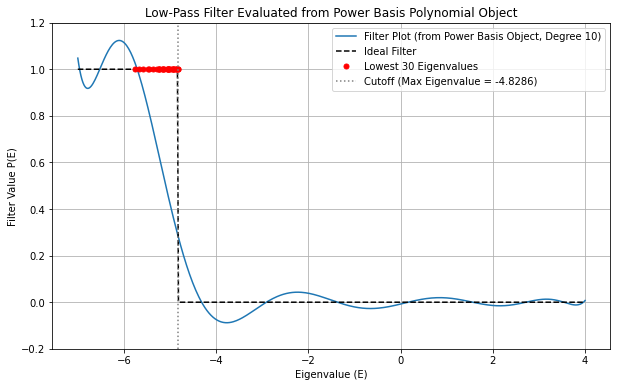


Check: Are evaluations from object and manual function close? True


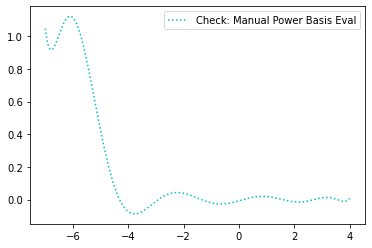

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial import Chebyshev, Polynomial # Import Polynomial

def create_power_basis_filter(lowest_eigenvalues, E_max_full, degree):
    """
    Creates a polynomial filter targeting the lowest eigenvalues and returns
    the filter represented as a numpy.polynomial.Polynomial object (power basis).

    Args:
        lowest_eigenvalues (np.ndarray): Array of the lowest eigenvalues.
                                         Used to determine the cutoff and E_min_full.
        E_max_full (float): The upper bound of the full spectral domain (e.g., 0.0).
        degree (int): The degree of the initial Chebyshev polynomial filter.

    Returns:
        numpy.polynomial.Polynomial: The filter polynomial object in power basis.
                                      Coefficients can be accessed via the .coef attribute.
    """
    #E_min_full = np.min(lowest_eigenvalues)
    E_min_full = -7.0 # <-- Set to a fixed value for the example
    E_cutoff = np.max(lowest_eigenvalues)
    full_range = [E_min_full, E_max_full]

    print(f"Full spectral domain for filter: [{E_min_full:.4f}, {E_max_full:.4f}]")
    print(f"Target cutoff energy (max of lowest eigs): {E_cutoff:.4f}")

    # Define the ideal low-pass function
    def ideal_filter_func(E):
        return np.where(E <= E_cutoff, 1.0, 0.0)

    # --- Chebyshev Fitting (Intermediate step) ---
    num_nodes = 2 * degree + 1
    k = np.arange(num_nodes)
    t_nodes = np.cos(k * np.pi / (num_nodes - 1))
    E_nodes = 0.5 * ((E_max_full - E_min_full) * t_nodes + (E_min_full + E_max_full))
    y_nodes = ideal_filter_func(E_nodes)
    cheb_filter_poly = Chebyshev.fit(E_nodes, y_nodes, degree, domain=full_range)

    # --- Convert to Power Basis ---
    power_filter_poly = cheb_filter_poly.convert(kind=Polynomial)

    # --- Return the Polynomial object (power basis) ---
    return power_filter_poly # <-- RETURNING POWER BASIS OBJECT

# --- Your Lowest 30 Eigenvalues ---
eigs_low30 = np.array([
    -4.8286, -4.8336, -4.8397, -4.8605, -4.8644, -4.9248, -4.9319,
    -4.9357, -4.9463, -4.9776, -5.0242, -5.0322, -5.0336, -5.038 ,
    -5.052 , -5.0688, -5.1357, -5.1469, -5.1474, -5.1848, -5.2322,
    -5.238 , -5.2488, -5.2928, -5.3663, -5.4488, -5.4735, -5.596 ,
    -5.6735, -5.7635
])

# --- Define Filter Parameters ---
E_UPPER_BOUND = 4      # Upper bound of the full spectrum
FILTER_DEGREE = 10        # Polynomial degree

# --- Create the Filter (now returns a Polynomial object) ---
power_filter_object = create_power_basis_filter( # <-- Function name changed
    eigs_low30, E_UPPER_BOUND, FILTER_DEGREE
)

# --- Get the Power Basis Coefficients ---
power_basis_coeffs = power_filter_object.coef
print(f"\nPower Basis Coefficients (Degree {power_filter_object.degree()}):")
print(power_basis_coeffs)
print(f"Number of coefficients: {len(power_basis_coeffs)}")

# --- Visualization (using the returned Polynomial object) ---
E_min_plot = np.min(eigs_low30) #
E_min_plot = -7
E_max_plot = E_UPPER_BOUND
E_plot = np.linspace(E_min_plot, E_max_plot, 500)

# Evaluate using the Polynomial object
filter_values = power_filter_object(E_plot)

# Calculate E_cutoff for plotting reference line
E_cutoff_val = np.max(eigs_low30)

plt.figure(figsize=(10, 6))
# Plot using values evaluated from the Polynomial object
plt.plot(E_plot, filter_values, label=f'Filter Plot (from Power Basis Object, Degree {FILTER_DEGREE})')

# Plot the ideal filter for comparison
plt.plot(E_plot, np.where(E_plot <= E_cutoff_val, 1.0, 0.0),
         'k--', label='Ideal Filter')
# Plot the lowest 30 eigenvalues themselves
plt.plot(eigs_low30, np.ones_like(eigs_low30), 'ro', label='Lowest 30 Eigenvalues', markersize=5)
# Mark the cutoff energy
plt.axvline(E_cutoff_val, color='gray', linestyle=':', label=f'Cutoff (Max Eigenvalue = {E_cutoff_val:.4f})')

plt.title('Low-Pass Filter Evaluated from Power Basis Polynomial Object')
plt.xlabel('Eigenvalue (E)')
plt.ylabel('Filter Value P(E)')
plt.ylim(-0.2, 1.2)
plt.legend()
plt.grid(True)
plt.show()

# --- Optional: Check evaluation using your power basis function ---
# Define the power basis evaluation function (like your corrected polynomial_approx)
def eval_power_poly(x, p_coeffs):
     val = 0.0
     x = np.asarray(x) # Ensure x is array for vectorized power operation
     for k in range(len(p_coeffs)):
         val += p_coeffs[k] * (x ** k)
     return val

# Evaluate using the function and the extracted power basis coefficients
y_poly_check = eval_power_poly(E_plot, power_basis_coeffs)
print("\nCheck: Are evaluations from object and manual function close?", np.allclose(filter_values, y_poly_check))
plt.plot(E_plot, y_poly_check, 'c:', label='Check: Manual Power Basis Eval')
plt.legend()
plt.show() # Show again if check plot added

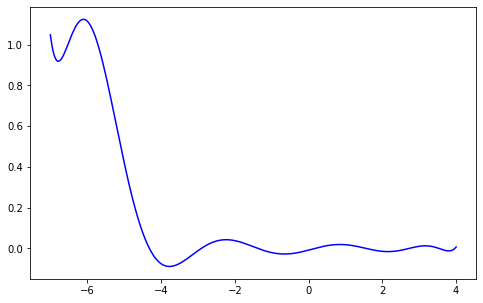

In [ ]:
def polynomial_approx(x, coeffs):
    """
    Given x and the fitted coeffs = [a_1, a_2, ..., a_d],
    evaluate p(x) = a_1 x + a_2 x^2 + ... + a_d x^d.
    """
    # We can use np.polyval-like logic but carefully in the correct order:
    # Or simply sum up a_k x^k in a loop
    return sum(coeffs[k] * (x ** (k )) for k in range(len(coeffs)))

# 5. Evaluate the fitted polynomial on a fine grid
x_plot = np.linspace(-7, 4, 300)
y_poly = polynomial_approx(x_plot, power_basis_coeffs)



# 7. Plot results
plt.figure(figsize=(8, 5))
#plt.scatter(x_data, y_data, label='Sample Data (for fitting)', color='red', zorder=3)
plt.plot(x_plot, y_poly, label=f'Degree-{16} Poly, a0=0', color='blue')


In [ ]:
e_poly = [] 

foldername = f"test_poly"
#generate_krylov_space(N_Krylov, H, HFS, max_bond_Krylov, trunc_tol, foldername) 
#generate_krylov_space_test_poly_with_constant(N_Krylov, H,coeffs, HFS, max_bond_Krylov, trunc_tol, foldername)
generate_krylov_space_test_poly_with_constant(200, H,power_basis_coeffs, HFS2, 30, trunc_tol, foldername)
N_use = 200
# C = coeff_canonical_orthogonalization(N_use, foldername)
# vector_list = generate_re_ortho_space_with_coeff(N_use, C, foldername)
#vector_list = generate_re_ortho_space(N_use, foldername)
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, mpo_ref)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
for N in range(5, N_use+1, 5):
    N_list.append(N)
    H_part = H_reduced[:N, :N]
    e_rotate, v_rotate = np.linalg.eigh(H_part)
    e_poly.append(e_rotate)

[1, 2, 4, 8, 15, 27, 30, 30, 30, 30, 30, 26, 15, 8, 4, 2, 1]
2
[1, 2, 4, 8, 16, 30, 30, 30, 30, 30, 30, 29, 16, 8, 4, 2, 1]
3
[1, 2, 4, 8, 16, 29, 30, 30, 30, 30, 30, 29, 16, 8, 4, 2, 1]
4
[1, 2, 4, 8, 16, 29, 30, 30, 30, 30, 30, 29, 16, 8, 4, 2, 1]
5
[1, 2, 4, 8, 16, 30, 30, 30, 30, 30, 30, 29, 16, 8, 4, 2, 1]
6
[1, 2, 4, 8, 16, 30, 30, 30, 30, 30, 30, 29, 16, 8, 4, 2, 1]
7
[1, 2, 4, 8, 16, 29, 30, 30, 30, 30, 30, 29, 16, 8, 4, 2, 1]
8
[1, 2, 4, 8, 16, 29, 30, 30, 30, 30, 30, 29, 16, 8, 4, 2, 1]
9
[1, 2, 4, 8, 16, 30, 30, 30, 30, 30, 30, 29, 16, 8, 4, 2, 1]
10
[1, 2, 4, 8, 16, 29, 30, 30, 30, 30, 30, 29, 16, 8, 4, 2, 1]
11
[1, 2, 4, 8, 16, 30, 30, 30, 30, 30, 30, 29, 16, 8, 4, 2, 1]
12
[1, 2, 4, 8, 16, 29, 30, 30, 30, 30, 30, 29, 16, 8, 4, 2, 1]
13
[1, 2, 4, 8, 16, 29, 30, 30, 30, 30, 30, 29, 16, 8, 4, 2, 1]
14
[1, 2, 4, 8, 16, 30, 30, 30, 30, 30, 30, 29, 16, 8, 4, 2, 1]
15
[1, 2, 4, 8, 16, 30, 30, 30, 30, 30, 30, 29, 16, 8, 4, 2, 1]
16
[1, 2, 4, 8, 16, 30, 30, 30, 30, 30, 30, 29, 16,

In [ ]:
eigenvalues

array([-4.8286, -4.8336, -4.8397, -4.8605, -4.8644, -4.9248, -4.9319,
       -4.9357, -4.9463, -4.9776, -5.0242, -5.0322, -5.0336, -5.038 ,
       -5.052 , -5.0688, -5.1357, -5.1469, -5.1474, -5.1848, -5.2322,
       -5.238 , -5.2488, -5.2928, -5.3663, -5.4488, -5.4735, -5.596 ,
       -5.6735, -5.7635])

### DMRG

In [ ]:
H_hei1 = pytenet.heisenberg_xxz_spin1_mpo(L = 10, J= 0.8, D=5, h= 0.1)
print(H_hei1.bond_dims)

### Convert the MPO to a matrix for testing exact eigenvalue 
matrix = H_hei1.as_matrix( sparse_format=True)
print(np.shape(matrix))
eigenvalues = eigsh(matrix, k=30, which='SA', return_eigenvectors=False)

[1, 4, 5, 5, 5, 5, 5, 5, 5, 4, 1]
(59049, 59049)


In [ ]:
print(eigenvalues)

[-35.5847 -35.5922 -35.5973 -35.6047 -35.6047 -35.6628 -35.6628 -35.6748
 -35.6766 -35.687  -35.7278 -35.7289 -35.8354 -35.9501 -35.9709 -36.1709
 -36.2045 -36.2045 -36.2091 -36.2091 -36.4966 -36.6966 -36.8682 -37.0682
 -40.4165 -40.4165 -40.6165 -40.6165 -45.4283 -45.4283]


In [ ]:
HFS_hei = generate_single_state_spin1(10,[0,2,0,2,0,2,0,2,0,2])
apply_operator(H_hei1, HFS_hei)

In [ ]:
N_Krylov = 150
max_bond_Krylov = 300
#max_bond_Krylov = 75
trunc_tol = 0
foldername = f"test"
e_hei1 = [] 
generate_krylov_space(N_Krylov, H_hei1, HFS_hei, max_bond_Krylov, trunc_tol, foldername) 

N_use = 120
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, H_hei1)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
for N in range(5, N_use+1, 5):
    N_list.append(N)
    H_part = H_reduced[:N, :N]
    e_rotate, v_rotate = np.linalg.eigh(H_part)
    e_hei1.append(e_rotate)

[1, 2, 3, 4, 4, 4, 4, 4, 3, 2, 1]
2
[1, 3, 7, 15, 26, 31, 25, 15, 6, 3, 1]
3
[1, 3, 8, 22, 57, 133, 57, 22, 8, 3, 1]
4
[1, 3, 9, 26, 74, 200, 74, 26, 9, 3, 1]
5
[1, 3, 9, 27, 80, 232, 80, 27, 9, 3, 1]
6
[1, 3, 9, 27, 81, 240, 80, 27, 9, 3, 1]
7
[1, 3, 9, 27, 81, 242, 81, 27, 9, 3, 1]
8
[1, 3, 9, 27, 81, 242, 81, 27, 9, 3, 1]
9
[1, 3, 9, 27, 81, 242, 81, 27, 9, 3, 1]
10
[1, 3, 9, 27, 81, 242, 81, 27, 9, 3, 1]
11
[1, 3, 9, 27, 81, 243, 81, 27, 9, 3, 1]
12
[1, 3, 9, 27, 81, 243, 81, 27, 9, 3, 1]
13
[1, 3, 9, 27, 81, 243, 81, 27, 9, 3, 1]
14
[1, 3, 9, 27, 81, 243, 81, 27, 9, 3, 1]
15
[1, 3, 9, 27, 81, 243, 81, 27, 9, 3, 1]
16
[1, 3, 9, 27, 81, 243, 81, 27, 9, 3, 1]
17
[1, 3, 9, 27, 81, 243, 81, 27, 9, 3, 1]
18
[1, 3, 9, 27, 81, 243, 81, 27, 9, 3, 1]
19
[1, 3, 9, 27, 81, 243, 81, 27, 9, 3, 1]
20
[1, 3, 9, 27, 81, 243, 81, 27, 9, 3, 1]
21
[1, 3, 9, 27, 81, 243, 81, 27, 9, 3, 1]
22
[1, 3, 9, 27, 81, 243, 81, 27, 9, 3, 1]
23
[1, 3, 9, 27, 81, 243, 81, 27, 9, 3, 1]
24
[1, 3, 9, 27, 81, 243, 81,

c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:456: ComplexWarning: Casting complex values to real discards the imaginary part
  H_reduced[i, j] = operator_inner_product(temp1, H_mpo, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:355: ComplexWarning: Casting complex values to real discards the imaginary part
  W[i,j] = vdot(temp1, temp2)
c:\Users\Zhangyu\pytenet_thc\pytenet\global_krylov_method.py:389: RuntimeWarning: invalid value encountered in sqrt
  Normalization[n] = np.sqrt(sum(S[n][p] * S[n][q] * W[p, q] for p in range(n + 1) for q in range(n + 1)))


In [ ]:
N_use = 50
H_reduced_non_rotho = generate_reduced_H_non_ortho(N_use, foldername, H_hei1)
W = get_W(N_use, foldername)
coeff = get_S(W)
coeff = np.array(coeff)
H_reduced = np.einsum('ik, kl, jl -> ij', coeff.conj(), H_reduced_non_rotho, coeff)
for N in range(5, N_use+1, 5):
    N_list.append(N)
    H_part = H_reduced[:N, :N]
    e_rotate, v_rotate = np.linalg.eigh(H_part)
    e_hei1.append(e_rotate)
e_hei1[-1]

array([-45.4283, -45.4283, -36.209 , -36.2044, -35.6628, -35.424 ,
       -34.619 , -33.723 , -32.005 , -31.5101, -30.8454, -30.2355,
       -29.3841, -27.9185, -26.6657, -25.3838, -24.1151, -22.7495,
       -21.3159, -19.8823, -18.4635, -16.4201, -15.091 , -13.56  ,
       -11.811 , -10.1168,  -8.5106,  -6.8355,  -4.7839,  -3.1675,
        -1.7195,   0.4065,   1.6251,   3.7111,   4.8111,   6.5711,
         7.4336,   9.912 ,  10.9618,  11.5364,  15.2876,  15.419 ,
        16.5528,  19.4722,  20.5381,  21.0438,  25.2607,  25.9323,
        30.24  ,  35.0197])

In [ ]:
HFS_test = generate_single_state_spin1(10,[0,2,0,2,0,2,0,2,0,2])
numsweeps = 100
en_sweeps = dmrg_twosite(H_hei1, HFS_test, numsweeps,25, 0)

# value after last iteration
e0 = en_sweeps[-1]
e0

c:\Users\Zhangyu\pytenet_thc\pytenet\krylov.py:40: RuntimeWarning: beta[2] ~= 0 encountered during Lanczos iteration.
  warnings.warn(
c:\Users\Zhangyu\pytenet_thc\pytenet\krylov.py:40: RuntimeWarning: beta[0] ~= 0 encountered during Lanczos iteration.
  warnings.warn(


np.float64(-45.42825805956042)

In [ ]:
en_sweeps

array([-45.4283, -45.4283, -45.4283, -45.4283, -45.4283, -45.4283,
       -45.4283, -45.4283, -45.4283, -45.4283, -45.4283, -45.4283,
       -45.4283, -45.4283, -45.4283, -45.4283, -45.4283, -45.4283,
       -45.4283, -45.4283, -45.4283, -45.4283, -45.4283, -45.4283,
       -45.4283, -45.4283, -45.4283, -45.4283, -45.4283, -45.4283,
       -45.4283, -45.4283, -45.4283, -45.4283, -45.4283, -45.4283,
       -45.4283, -45.4283, -45.4283, -45.4283, -45.4283, -45.4283,
       -45.4283, -45.4283, -45.4283, -45.4283, -45.4283, -45.4283,
       -45.4283, -45.4283, -45.4283, -45.4283, -45.4283, -45.4283,
       -45.4283, -45.4283, -45.4283, -45.4283, -45.4283, -45.4283,
       -45.4283, -45.4283, -45.4283, -45.4283, -45.4283, -45.4283,
       -45.4283, -45.4283, -45.4283, -45.4283, -45.4283, -45.4283,
       -45.4283, -45.4283, -45.4283, -45.4283, -45.4283, -45.4283,
       -45.4283, -45.4283, -45.4283, -45.4283, -45.4283, -45.4283,
       -45.4283, -45.4283, -45.4283, -45.4283, -45.4283, -45.4

In [ ]:
real_gs = copy.deepcopy(HFS_test)
real_gs.compress_no_normalization_max_bond(tol = 0, max_bond = 15)
eigenvalues[-1] - operator_average(real_gs, H_hei1)


np.complex128(-1.4925802815923817e-09+0j)

In [ ]:
HFS_hei = generate_single_state_spin1(10,[0,2,0,2,0,2,0,2,0,2])
numsweeps = 100
en_sweeps = dmrg_singlesite(H_hei1, HFS_hei, numsweeps,25)

# value after last iteration
e0 = en_sweeps[-1]
e0

c:\Users\Zhangyu\pytenet_thc\pytenet\krylov.py:40: RuntimeWarning: beta[0] ~= 0 encountered during Lanczos iteration.
  warnings.warn(


np.float64(-45.0)

In [ ]:
en_sweeps

array([-45., -45., -45., -45., -45., -45., -45., -45., -45., -45., -45.,
       -45., -45., -45., -45., -45., -45., -45., -45., -45., -45., -45.,
       -45., -45., -45., -45., -45., -45., -45., -45., -45., -45., -45.,
       -45., -45., -45., -45., -45., -45., -45., -45., -45., -45., -45.,
       -45., -45., -45., -45., -45., -45., -45., -45., -45., -45., -45.,
       -45., -45., -45., -45., -45., -45., -45., -45., -45., -45., -45.,
       -45., -45., -45., -45., -45., -45., -45., -45., -45., -45., -45.,
       -45., -45., -45., -45., -45., -45., -45., -45., -45., -45., -45.,
       -45., -45., -45., -45., -45., -45., -45., -45., -45., -45., -45.,
       -45.])

In [ ]:
print(eigenvalues[-1]-e0)
#print(eigenvalues[-1]-e_hei1[-1][0])

2.0605739337042905e-13


In [ ]:
eigenvalues[-1]

np.float64(-45.428258059560214)